# Speech Emotion Recognition on CREMA-D
**ARTI 502 — Robust Speech Emotion Recognition Across Speakers and Recording Conditions Using Deep Learning**

## 1. Introduction and objectives
We compare a CNN–LSTM and a Transformer for six-class speech emotion recognition on CREMA-D. The experiments examine architecture, hyperparameters, mel-band reduction and sensitivity to additive noise. Both models learn from scratch under the same speaker-disjoint partition; development decisions precede held-out evaluation.

The fixed budget comprises two baselines, 16 HPO trials, 36 feature-CV trials and 2–4 final fits, totaling at most 566 epochs. Configure the Drive path below and select a Colab GPU. `smoke` uses generated fixtures for software checks; `full` acquires CREMA-D automatically. A device and checkpoint round trip precedes data preparation.

### Experimental Setup

The following cells define the experiment configuration, initialize the required libraries, and verify GPU availability and checkpoint storage before data preparation.

In [1]:
import os
import sys
import subprocess
import tempfile
from pathlib import Path
RUN_MODE = 'full'
STUDY_ID = 'CREMAD_SER'
OUTPUT_PARENT = Path('/content/drive/MyDrive/ARTI502_Research')
CACHE_DIR = Path('/content/cremad_cache')
AUDIO_DIR = None
DATASET_ID = 'cfahlgren1/crema-d'
MAX_NEW_TRIALS = None


In [2]:
import importlib.util
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    packages = ['numpy==2.2.6', 'scipy==1.15.3', 'pandas==2.2.3', 'scikit-learn==1.6.1',
        'matplotlib==3.10.1', 'librosa==0.11.0', 'soundfile==0.13.1', 'datasets==3.6.0',
        'huggingface-hub==0.33.4']
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *packages], check=True)
    from google.colab import drive
    drive.mount('/content/drive')
else:
    assert RUN_MODE == 'smoke', 'Run on a Colab GPU.'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['NUMBA_CACHE_DIR'] = str(Path(tempfile.gettempdir()) / 'cremad_ser_numba_cache')
os.environ['MPLCONFIGDIR'] = str(Path(tempfile.gettempdir()) / 'cremad_ser_matplotlib')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import copy
import hashlib
import io
import json
import platform
import random
import shutil
import time
import importlib.metadata as metadata
from types import SimpleNamespace
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix, classification_report, roc_curve, auc
from IPython.display import display, Markdown, Image
assert RUN_MODE in ['full', 'smoke']
for module, package in [(np, 'numpy'), (pd, 'pandas'), (torch, 'torch')]:
    if module.__version__ != metadata.version(package):
        raise RuntimeError('Restart the runtime after dependency installation, then rerun the notebook.')
torch.set_num_threads(2)
LABELS = ['angry', 'disgust', 'fearful', 'happy', 'neutral', 'sad']
SIZES = [40, 20, 10, 5, 2, 1]


In [4]:
IMPLEMENTATION_SHA256 = '1573c56cc00819dedfd9b1817f241782bcadbebeeec828922069c4cbed9dd65a'

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()

def signature(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()

def write_json(path, value):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.pending')
    tmp.write_text(json.dumps(value, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    os.replace(tmp, path)

def immutable_json(path, value):
    path = Path(path)
    if path.exists():
        if json.loads(path.read_text()) != value:
            raise ValueError('Experiment configuration mismatch: ' + str(path))
    else:
        write_json(path, value)

def implementation_fingerprint():
    return IMPLEMENTATION_SHA256

def runtime_versions():
    versions = {'python': platform.python_version()}
    for name in ['torch', 'numpy', 'scipy', 'pandas', 'scikit-learn', 'librosa',
        'soundfile', 'datasets', 'huggingface-hub', 'matplotlib']:
        try:
            versions[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            versions[name] = 'absent'
    return versions


In [5]:
def open_run_root(root, mode):
    root = Path(root).resolve()
    if mode not in ('full', 'smoke') or 'exported' in [part.lower() for part in root.parts]:
        raise ValueError('Invalid run mode or protected output path')
    marker = root / 'complete_run_identity.json'
    if root.exists() and any(root.iterdir()) and (not marker.exists()):
        raise ValueError('Choose a new run folder; existing files will not be adopted or overwritten')
    root.mkdir(parents=True, exist_ok=True)
    immutable_json(marker, dict(study=STUDY_ID, mode=mode, implementation=implementation_fingerprint(),
        software=runtime_versions()))
    return root


In [6]:
def atomic_torch_save(value, path):
    temporary = Path(path).with_suffix('.pending')
    torch.save(value, temporary)
    os.replace(temporary, path)


In [7]:
def runtime_preflight(run_root, mode, in_colab=False):
    """Exercise the selected device and an atomic checkpoint round trip before data acquisition."""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if mode == 'full' and (not in_colab or device.type != 'cuda'):
        raise RuntimeError('Full experiments require a Google Colab GPU runtime')
    drive_path = Path('/content/drive').resolve()
    if in_colab and (not (drive_path / 'MyDrive').is_dir() or not Path(run_root).resolve().is_relative_to(drive_path)):
        raise RuntimeError('Mount Google Drive and place OUTPUT_PARENT inside that mount')
    model = nn.Linear(8, 6).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == 'cuda')
    values = torch.arange(32, dtype=torch.float32, device=device).reshape(4, 8) / 32
    with torch.autocast(device.type, enabled=device.type == 'cuda'):
        loss = model(values).square().mean()
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    if not torch.isfinite(loss) or any((not torch.isfinite(p).all() for p in model.parameters())):
        raise RuntimeError('Device preflight produced nonfinite values')
    directory = Path(run_root) / 'preflight'
    directory.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    checkpoint = directory / (stamp + '.pt')
    payload = dict(model={name: value.detach().cpu() for name, value in model.state_dict().items()},
        optimizer=optimizer.state_dict(), scaler=scaler.state_dict())
    atomic_torch_save(payload, checkpoint)
    recovered = torch.load(checkpoint, map_location='cpu', weights_only=True)
    for name, value in payload['model'].items():
        torch.testing.assert_close(value, recovered['model'][name], rtol=0, atol=0)
    record = dict(device=str(device), cuda_executed=device.type == 'cuda',
        google_drive_exercised=in_colab, checkpoint_round_trip=True, checkpoint=checkpoint.name,
        sha256=digest(checkpoint), software=runtime_versions())
    write_json(directory / (stamp + '.json'), record)
    return record


In [8]:
RUN_ROOT = open_run_root(OUTPUT_PARENT / STUDY_ID / RUN_MODE, RUN_MODE)
AUDIT_DIR = RUN_ROOT / 'data_audit'
AUDIT_DIR.mkdir(exist_ok=True)
CACHE_DIR = CACHE_DIR / STUDY_ID / RUN_MODE
CACHE_DIR.mkdir(parents=True, exist_ok=True)
SCOPE = 'CREMA-D' if RUN_MODE == 'full' else 'Synthetic Test'
preflight = runtime_preflight(RUN_ROOT, RUN_MODE, IN_COLAB)
environment = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
timestamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
(RUN_ROOT / f'environment_{timestamp}.txt').write_text(environment, encoding='utf-8')
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Study outputs:', RUN_ROOT)


Device: Tesla T4
Study outputs: /content/drive/MyDrive/ARTI502_Research/CREMAD_SER/full



## 2. Dataset Exploration

CREMA-D contains 7,442 recordings of acted English speech across six emotions and 91 speakers ([Cao et al., 2014](https://doi.org/10.1109/TAFFC.2014.2336244)).

A fixed speaker-disjoint partition assigns 5,152 recordings to training, 1,148 to validation, and 1,142 to testing, with 63, 14, and 14 speakers, respectively. The split manifest is generated from recording filenames and predefined speaker groups, with SHA256 verification to ensure reproducibility.

The dataset revision is recorded, and audio files are cached for reuse. Data integrity checks verify recording metadata, valid audio signals, and duplicate recordings across partitions. Descriptive statistics and visualizations examine emotion distribution, speaker representation, recording duration, and signal levels.


In [9]:
def original_speaker_groups():
    validation = {1001, 1005, 1011, 1012, 1013, 1029, 1034, 1041, 1050, 1056, 1065, 1067, 1078, 1086}
    test = {1016, 1019, 1023, 1027, 1031, 1036, 1040, 1045, 1063, 1066, 1068, 1069, 1071, 1089}
    return (validation, test)


In [10]:
def validate_manifest(rows, strict=True):
    required = {'idx', 'source_file', 'speaker', 'label', 'class_id', 'split'}
    if not required <= set(rows):
        raise ValueError('Incomplete split manifest')
    if rows.idx.duplicated().any() or rows.source_file.duplicated().any():
        raise ValueError('Duplicate source identity')
    if not set(rows.split) <= {'train', 'val', 'test'}:
        raise ValueError('Unknown split')
    if rows.groupby('speaker').split.nunique().max() != 1:
        raise ValueError('Speaker leakage')
    codes = dict(ANG='angry', DIS='disgust', FEA='fearful', HAP='happy', NEU='neutral', SAD='sad')
    for r in rows.itertuples():
        parts = Path(r.source_file).stem.split('_')
        if not 0 <= r.class_id < 6 or LABELS[r.class_id] != r.label:
            raise ValueError('Class order differs')
        if 'crema_' + parts[0] != r.speaker or codes[parts[2]] != r.label:
            raise ValueError('Filename metadata differs')
    if strict:
        if len(rows) != 7442 or rows.speaker.nunique() != 91:
            raise ValueError('Wrong corpus')
        if rows.groupby('split').size().to_dict() != {'train': 5152, 'val': 1148, 'test': 1142}:
            raise ValueError('Wrong split counts')
        if rows.groupby('split').speaker.nunique().to_dict() != {'train': 63, 'val': 14, 'test': 14}:
            raise ValueError('Wrong speaker counts')
        val, test = original_speaker_groups()
        for split, expected in [('val', val), ('test', test)]:
            if set(rows.loc[rows.split == split, 'speaker']) != {'crema_' + str(i) for i in expected}:
                raise ValueError('Original speakers changed')
    return rows.copy()


In [11]:
def reproduce_manifest(source_files, destination):
    """Generate and validate the speaker-disjoint split manifest."""
    names = sorted((Path(name).name for name in source_files))
    if len(names) != 7442 or len(set(names)) != len(names):
        raise ValueError('Expected exactly 7,442 unique CREMA-D recordings')
    validation, test = original_speaker_groups()
    labels = dict(ANG='angry', DIS='disgust', FEA='fearful', HAP='happy', NEU='neutral', SAD='sad')
    records = []
    for index, filename in enumerate(names):
        actor, sentence, emotion, intensity = Path(filename).stem.split('_')
        label = labels[emotion]
        split = 'val' if int(actor) in validation else 'test' if int(actor) in test else 'train'
        records.append(dict(idx=index, speaker='crema_' + actor, label=label,
            class_id=LABELS.index(label), source_file=filename, split=split))
    rows = validate_manifest(pd.DataFrame(records))
    content = rows.to_csv(index=False, lineterminator='\n').encode('utf-8')
    expected = '57c73f5cda0a4d67cb9f933e694e5ae0ad7917fec1d5a2377eec50d895adbf54'
    if hashlib.sha256(content).hexdigest() != expected:
        raise ValueError('Split manifest checksum mismatch')
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and digest(destination) != expected:
        raise ValueError('Saved split manifest changed')
    if not destination.exists():
        temporary = destination.with_suffix('.pending')
        temporary.write_bytes(content)
        os.replace(temporary, destination)
    return rows


In [12]:
def stage_cached_files(persistent, local, inventory):
    """Restore verified cache files to local storage."""
    persistent, local = (Path(persistent), Path(local))
    for relative, checksum in inventory.items():
        source, destination = (persistent / relative, local / relative)
        if destination.is_file() and digest(destination) == checksum:
            continue
        if digest(source) != checksum:
            raise ValueError('Persistent dataset cache is incomplete or changed: ' + relative)
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_suffix(destination.suffix + '.pending')
        shutil.copyfile(source, temporary)
        if digest(temporary) != checksum:
            raise ValueError('Dataset cache copy failed checksum verification')
        os.replace(temporary, destination)


In [13]:
def acquire_audio_dataset(cache_dir, audit_dir, dataset_id):
    from datasets import Audio, load_dataset, load_from_disk
    from huggingface_hub import HfApi
    audit_dir, cache_dir = (Path(audit_dir), Path(cache_dir))
    revision_file = audit_dir / 'dataset_revision.json'
    if revision_file.exists():
        source = json.loads(revision_file.read_text())
        if source['dataset'] != dataset_id:
            raise ValueError('Dataset source mismatch')
    else:
        source = dict(dataset=dataset_id, revision=HfApi().dataset_info(dataset_id).sha)
        immutable_json(revision_file, source)
    persistent = audit_dir.parent / 'cache' / 'audio_dataset'
    local = cache_dir / 'audio_dataset'
    marker = persistent / 'cache_complete.json'
    if marker.exists():
        saved = json.loads(marker.read_text())
        if saved['source'] != source:
            raise ValueError('Cached dataset revision differs')
        stage_cached_files(persistent, local, saved['files'])
        dataset = load_from_disk(str(local / 'arrow'))
    else:
        dataset = load_dataset(dataset_id, revision=source['revision'], split='train',
            cache_dir=str(cache_dir / 'hf')).cast_column('audio', Audio(decode=False))
        persistent.mkdir(parents=True, exist_ok=True)
        dataset.save_to_disk(str(persistent / 'arrow'), max_shard_size='250MB')
        files = {path.relative_to(persistent).as_posix(): digest(path) for path in (persistent / 'arrow').rglob('*') if path.is_file()}
        write_json(marker, dict(source=source, files=files))
    return (dataset.cast_column('audio', Audio(decode=False)), source, digest(marker))


In [14]:
def synthetic_audio_fixture(directory):
    """Generate synthetic audio for pipeline testing."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    generator = np.random.default_rng(502)
    rows = []
    for speaker in range(12):
        for label, code in enumerate(['ANG', 'DIS', 'FEA', 'HAP', 'NEU', 'SAD']):
            filename = f'{1001 + speaker}_DFA_{code}_XX.wav'
            time_axis = np.arange(3200 + 160 * label) / 16000
            waveform = 0.08 * np.sin(2 * np.pi * (180 + 50 * label) * time_axis)
            waveform += generator.normal(0, 0.005, len(time_axis))
            buffer = io.BytesIO()
            sf.write(buffer, waveform, 16000, format='WAV', subtype='PCM_16')
            path = directory / filename
            if path.exists():
                assert path.read_bytes() == buffer.getvalue()
            else:
                path.write_bytes(buffer.getvalue())
            rows.append(dict(idx=len(rows), source_file=filename, speaker=f'crema_{1001 + speaker}',
                label=LABELS[label], class_id=label, split='train' if speaker < 8 else 'val' if speaker < 10 else 'test'))
    return pd.DataFrame(rows)


In [15]:
class AudioCorpus:
    """Load CREMA-D audio recordings from local files or Hugging Face."""

    def __init__(self, records, cache_dir, audit_dir, audio_dir=None, dataset_id='cfahlgren1/crema-d'):
        self.records = records
        self.audio_dir = Path(audio_dir) if audio_dir else None
        self.audit_dir = Path(audit_dir)
        self.audit_dir.mkdir(parents=True, exist_ok=True)
        self.cache_identity = None
        if self.audio_dir:
            paths = list(self.audio_dir.rglob('*.wav'))
            self.files = {path.name: path for path in paths}
            if len(self.files) != len(paths):
                raise ValueError('Duplicate WAV filenames in the configured audio directory')
            if records is not None and (not set(records.source_file) <= set(self.files)):
                raise ValueError('The WAV directory is missing manifest recordings')
            self.source = {'kind': 'local_wav_directory'}
        else:
            self.dataset, self.source, self.cache_identity = acquire_audio_dataset(cache_dir, audit_dir, dataset_id)
            self.indices = {Path(name).name: index for index, name in enumerate(self.dataset['source_file'])}
            if len(self.indices) != len(self.dataset):
                raise ValueError('Duplicate source filenames in downloaded data')
            if records is not None and (len(self.dataset) != len(records) or set(self.indices) != set(records.source_file)):
                raise ValueError('Dataset filenames do not match the split manifest')
        self.source_files = sorted(self.files if self.audio_dir else self.indices)

    def read(self, record):
        if self.audio_dir:
            raw = self.files[record.source_file].read_bytes()
        else:
            item = self.dataset[self.indices[record.source_file]]
            labels = self.dataset.features['label'].names
            aliases = {'anger': 'angry', 'fear': 'fearful'}
            label = labels[item['label']]
            if aliases.get(label, label) != record.label or f"crema_{item['actor_id']}" != record.speaker:
                raise ValueError('Actor or emotion differs from the manifest')
            raw = item['audio'].get('bytes')
            if raw is None:
                raw = Path(item['audio']['path']).read_bytes()
        waveform, sample_rate = sf.read(io.BytesIO(raw), dtype='float32')
        if waveform.ndim == 2:
            waveform = waveform.mean(axis=1)
        if waveform.ndim != 1 or not len(waveform) or (not np.isfinite(waveform).all()):
            raise ValueError('Empty or invalid audio')
        return (waveform, sample_rate, hashlib.sha256(raw).hexdigest())


In [16]:
def inspect_audio(corpus, records, output_dir, scope):
    output_dir = Path(output_dir)
    marker = output_dir / 'audio_audit_complete.json'
    identity = dict(source=corpus.cache_identity, manifest=signature(records.to_dict('records')), scope=scope)
    if marker.exists() and corpus.cache_identity:
        saved = json.loads(marker.read_text())
        if saved['identity'] != identity:
            raise ValueError('Audio audit identity changed')
        for filename, checksum in saved['files'].items():
            if digest(output_dir / filename) != checksum:
                raise ValueError('Saved audio audit changed')
        return (pd.read_csv(output_dir / 'audio_statistics_per_clip.csv'),
            pd.DataFrame(json.loads((output_dir / 'audio_inventory.json').read_text())))
    statistics, inventory = ([], [])
    for number, record in enumerate(records.itertuples(), 1):
        waveform, sample_rate, checksum = corpus.read(record)
        decoded = hashlib.sha256(str(sample_rate).encode() + waveform.astype('<f4').tobytes()).hexdigest()
        statistics.append(dict(idx=int(record.idx), source_file=record.source_file,
            speaker=record.speaker, label=record.label, split=record.split, duration_seconds=len(waveform) / sample_rate,
            sample_rate=sample_rate, peak=float(np.abs(waveform).max()), rms_dbfs=20 * np.log10(max(np.sqrt(np.mean(waveform.astype(float) ** 2)),
            1e-12))))
        inventory.append(dict(idx=int(record.idx), source_file=record.source_file,
            split=record.split, audio_sha256=checksum, decoded_sha256=decoded))
        if number % 1000 == 0:
            print(f'Inspected {number}/{len(records)} recordings', flush=True)
    inventory = pd.DataFrame(inventory)
    if (inventory.groupby('decoded_sha256').split.nunique() > 1).any():
        raise ValueError('Identical decoded audio crosses the speaker partitions')
    immutable_json(Path(output_dir) / 'audio_inventory.json', inventory.to_dict('records'))
    statistics = pd.DataFrame(statistics)
    statistics['evidence_scope'] = scope
    statistics.to_csv(Path(output_dir) / 'audio_statistics_per_clip.csv', index=False)
    write_json(marker, dict(identity=identity, files={name: digest(output_dir / name) for name in ['audio_inventory.json',
        'audio_statistics_per_clip.csv']}))
    return (statistics, inventory)


In [17]:
def plotting():
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False,
        'axes.spines.right': False})
    return plt


In [18]:
def save_figure(fig, path, scope):
    if scope == 'Synthetic Test':
        fig.text(
            0.5, 0.005, 'Synthetic Test',
            ha='center', va='bottom',
            fontsize=8, color='#a43131'
        )
        fig.tight_layout(rect=(0, 0.035, 1, 0.97))
    else:
        fig.tight_layout()

    fig.savefig(path, dpi=300, bbox_inches='tight')
    fig.savefig(Path(path).with_suffix('.svg'), bbox_inches='tight')
    plotting().close(fig)


In [19]:
def manifest_tables(rows, output, scope):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    counts = pd.crosstab(rows.split, rows.label).reindex(index=['train', 'val', 'test'], columns=LABELS)
    counts['recordings'] = counts.sum(axis=1)
    counts['speakers'] = rows.groupby('split').speaker.nunique()
    counts.assign(evidence_scope=scope).to_csv(output / 'split_class_counts.csv')
    speakers = rows.groupby(['split', 'speaker']).size().rename('recordings').reset_index()
    speakers.assign(evidence_scope=scope).to_csv(output / 'speaker_counts.csv', index=False)
    speakers.groupby('split').recordings.describe().rename(columns={'50%': 'median'})[['count',
        'mean', 'median', 'std', 'min', 'max']].assign(evidence_scope=scope).to_csv(output / 'speaker_statistics.csv')
    plt = plotting()
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    counts[LABELS].T.plot.bar(stacked=True, ax=axes[0], color=['#157a8a', '#e0a13a', '#446688'])
    axes[0].set(ylabel='Recordings', xlabel='Emotion', title='Emotion Distribution by Data Split')
    axes[0].tick_params(axis='x', rotation=30)
    axes[1].bar(counts.index, counts.speakers, color='#157a8a')
    axes[1].set(ylabel='Distinct speakers', title='Speaker-disjoint partition')
    save_figure(fig, output / 'dataset_distribution.png', scope)


In [20]:
def dataset_statistics(records, audio_statistics, output_dir, scope):
    output_dir = Path(output_dir)
    manifest_tables(records, output_dir, scope)
    summaries = []
    for split in ['all', 'train', 'val', 'test']:
        subset = audio_statistics if split == 'all' else audio_statistics[audio_statistics.split == split]
        summary = subset[['duration_seconds', 'rms_dbfs', 'peak']].describe().T
        summary = summary.rename(columns={'50%': 'median'})
        summary = summary[['count', 'mean', 'median', 'std', 'min', 'max']]
        summaries.append(summary.assign(split=split).reset_index(names='measure'))
    summary = pd.concat(summaries).assign(evidence_scope=scope)
    summary.to_csv(output_dir / 'audio_descriptive_statistics.csv', index=False)
    plt = plotting()
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    bins = np.histogram_bin_edges(audio_statistics.duration_seconds, bins=25)
    for split in ['train', 'val', 'test']:
        values = audio_statistics.loc[audio_statistics.split == split, 'duration_seconds']
        axes[0].hist(values, bins=bins, alpha=0.5, label=split)
    axes[0].set(xlabel='Duration (s)', ylabel='Recordings', title='Recording duration by partition')
    axes[0].legend()
    audio_statistics.boxplot(column='rms_dbfs', by='label', ax=axes[1], grid=False)
    axes[1].set(title='Recording level by emotion', xlabel='Emotion', ylabel='RMS (dBFS)')
    axes[1].tick_params(axis='x', rotation=30)
    figure.suptitle('CREMA-D acoustic overview')
    save_figure(figure, output_dir / 'audio_distributions.png', scope)
    return summary


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00004.parquet:   0%|          | 0.00/160M [00:00<?, ?B/s]

data/train-00001-of-00004.parquet:   0%|          | 0.00/148M [00:00<?, ?B/s]

data/train-00002-of-00004.parquet:   0%|          | 0.00/146M [00:00<?, ?B/s]

data/train-00003-of-00004.parquet:   0%|          | 0.00/152M [00:00<?, ?B/s]

... (2 outputs left out)

Inspected 1000/7442 recordings
Inspected 2000/7442 recordings
Inspected 3000/7442 recordings
Inspected 4000/7442 recordings
Inspected 5000/7442 recordings
Inspected 6000/7442 recordings
Inspected 7000/7442 recordings


,split,angry,disgust,fearful,happy,neutral,sad,recordings,speakers
0,train,880,880,880,880,752,880,5152,63
1,val,196,196,196,196,168,196,1148,14
2,test,195,195,195,195,167,195,1142,14


,split,count,mean,median,std,min,max
0,test,14.0,81.571429,82.0,1.603567,76.0,82.0
1,train,63.0,81.777778,82.0,1.069284,76.0,82.0
2,val,14.0,82.000000,82.0,0.000000,82.0,82.0


,measure,count,mean,median,std,min,max,split
0,duration_seconds,7442.0,2.543,2.502,0.506,1.268,5.005,all
1,rms_dbfs,7442.0,-31.646,-32.897,7.742,-240.000,-10.356,all
2,peak,7442.0,0.313,0.198,0.283,0.000,1.000,all
0,duration_seconds,5152.0,2.577,2.502,0.522,1.335,5.005,train
1,rms_dbfs,5152.0,-31.882,-32.986,7.883,-240.000,-10.620,train
2,peak,5152.0,0.306,0.193,0.279,0.000,1.000,train
0,duration_seconds,1148.0,2.485,2.436,0.472,1.268,4.805,val
1,rms_dbfs,1148.0,-30.942,-32.234,7.211,-45.713,-10.481,val
2,peak,1148.0,0.339,0.216,0.288,0.032,1.000,val
0,duration_seconds,1142.0,2.448,2.402,0.444,1.368,4.538,test


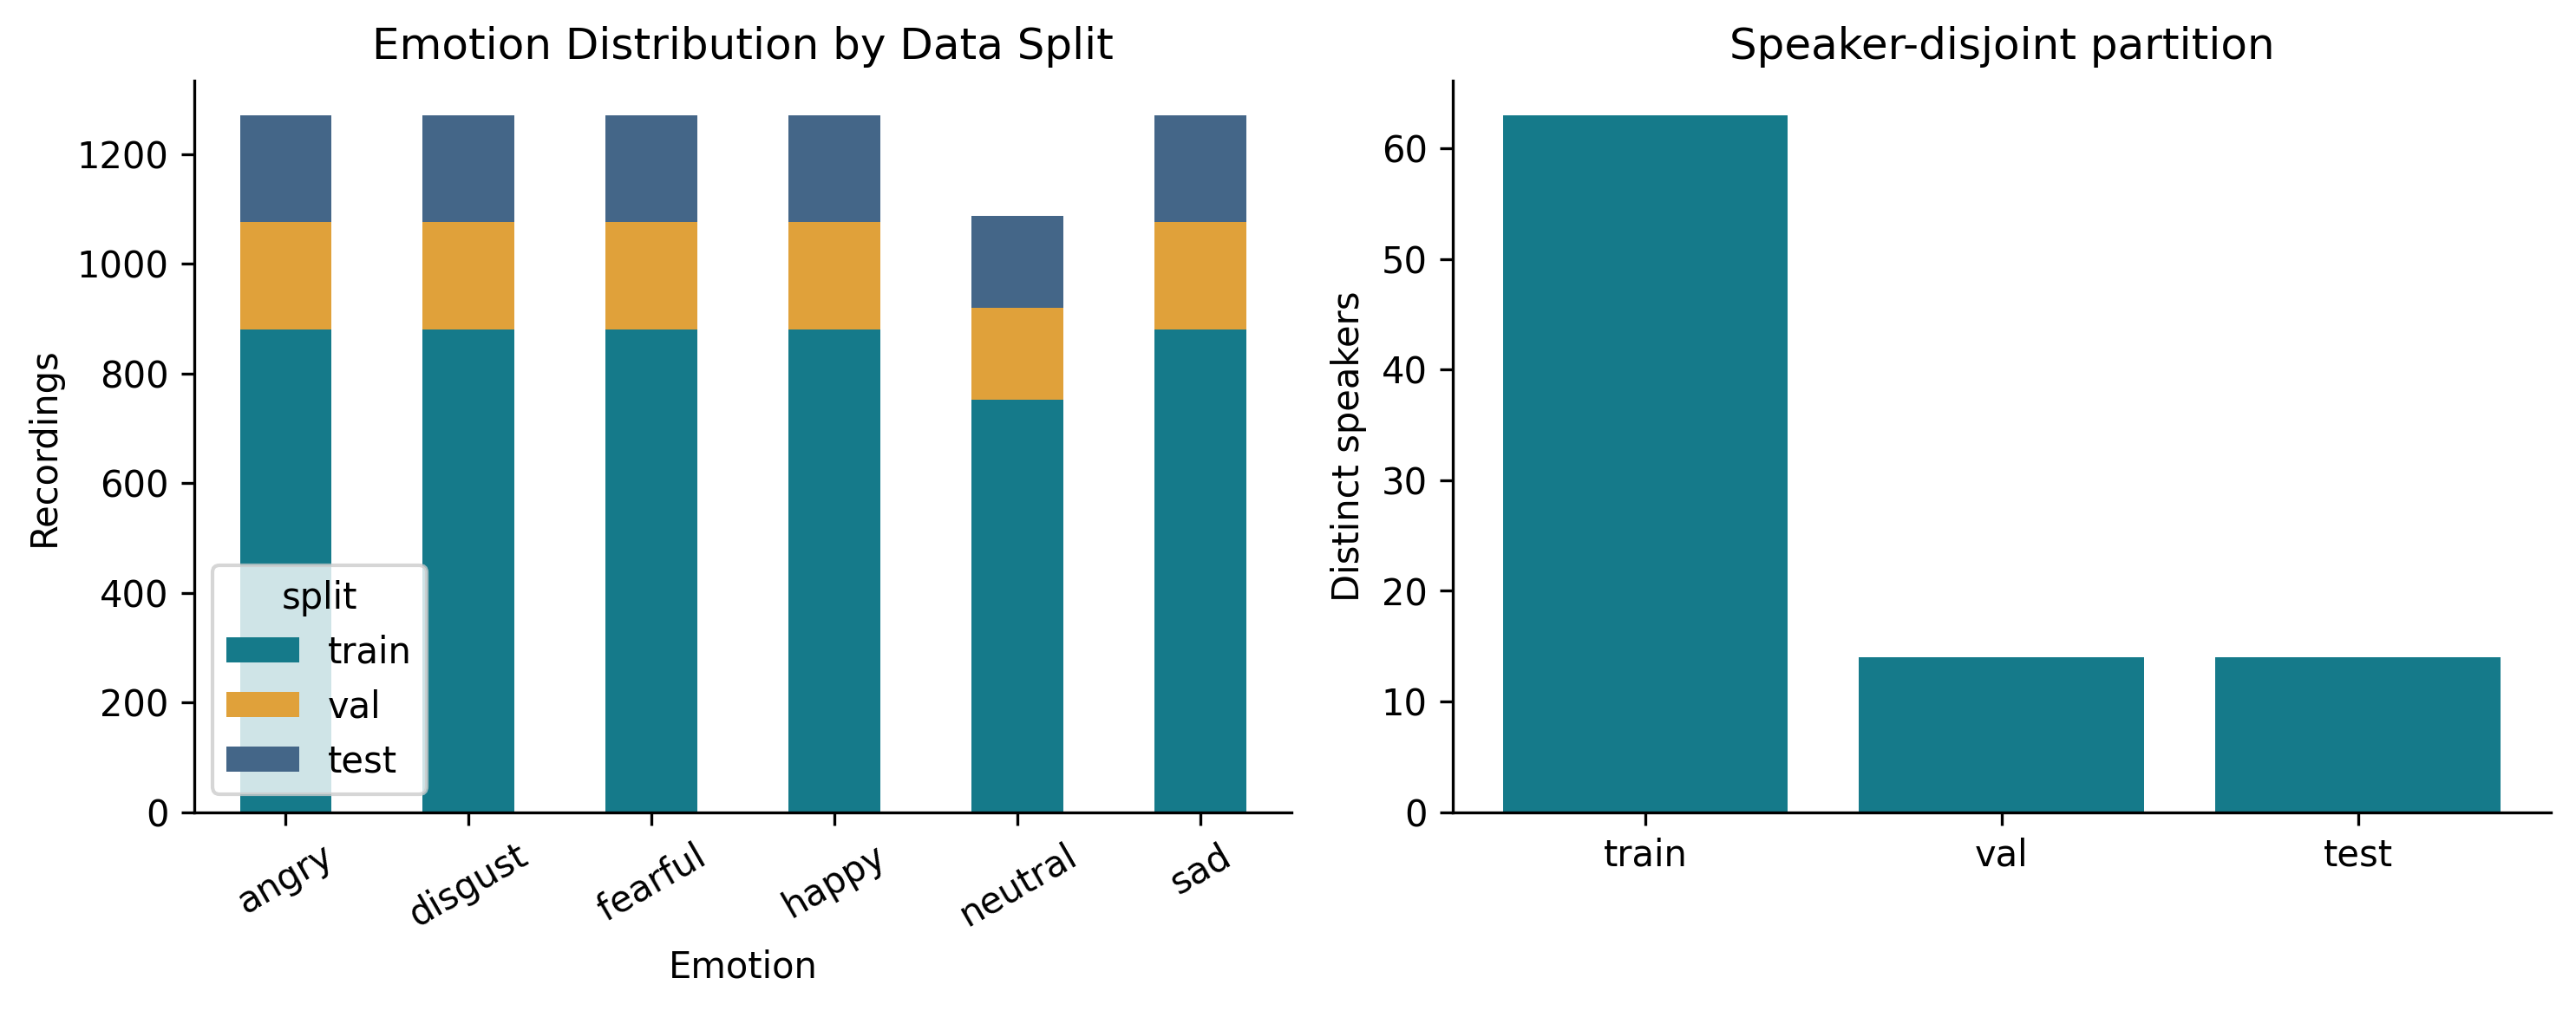

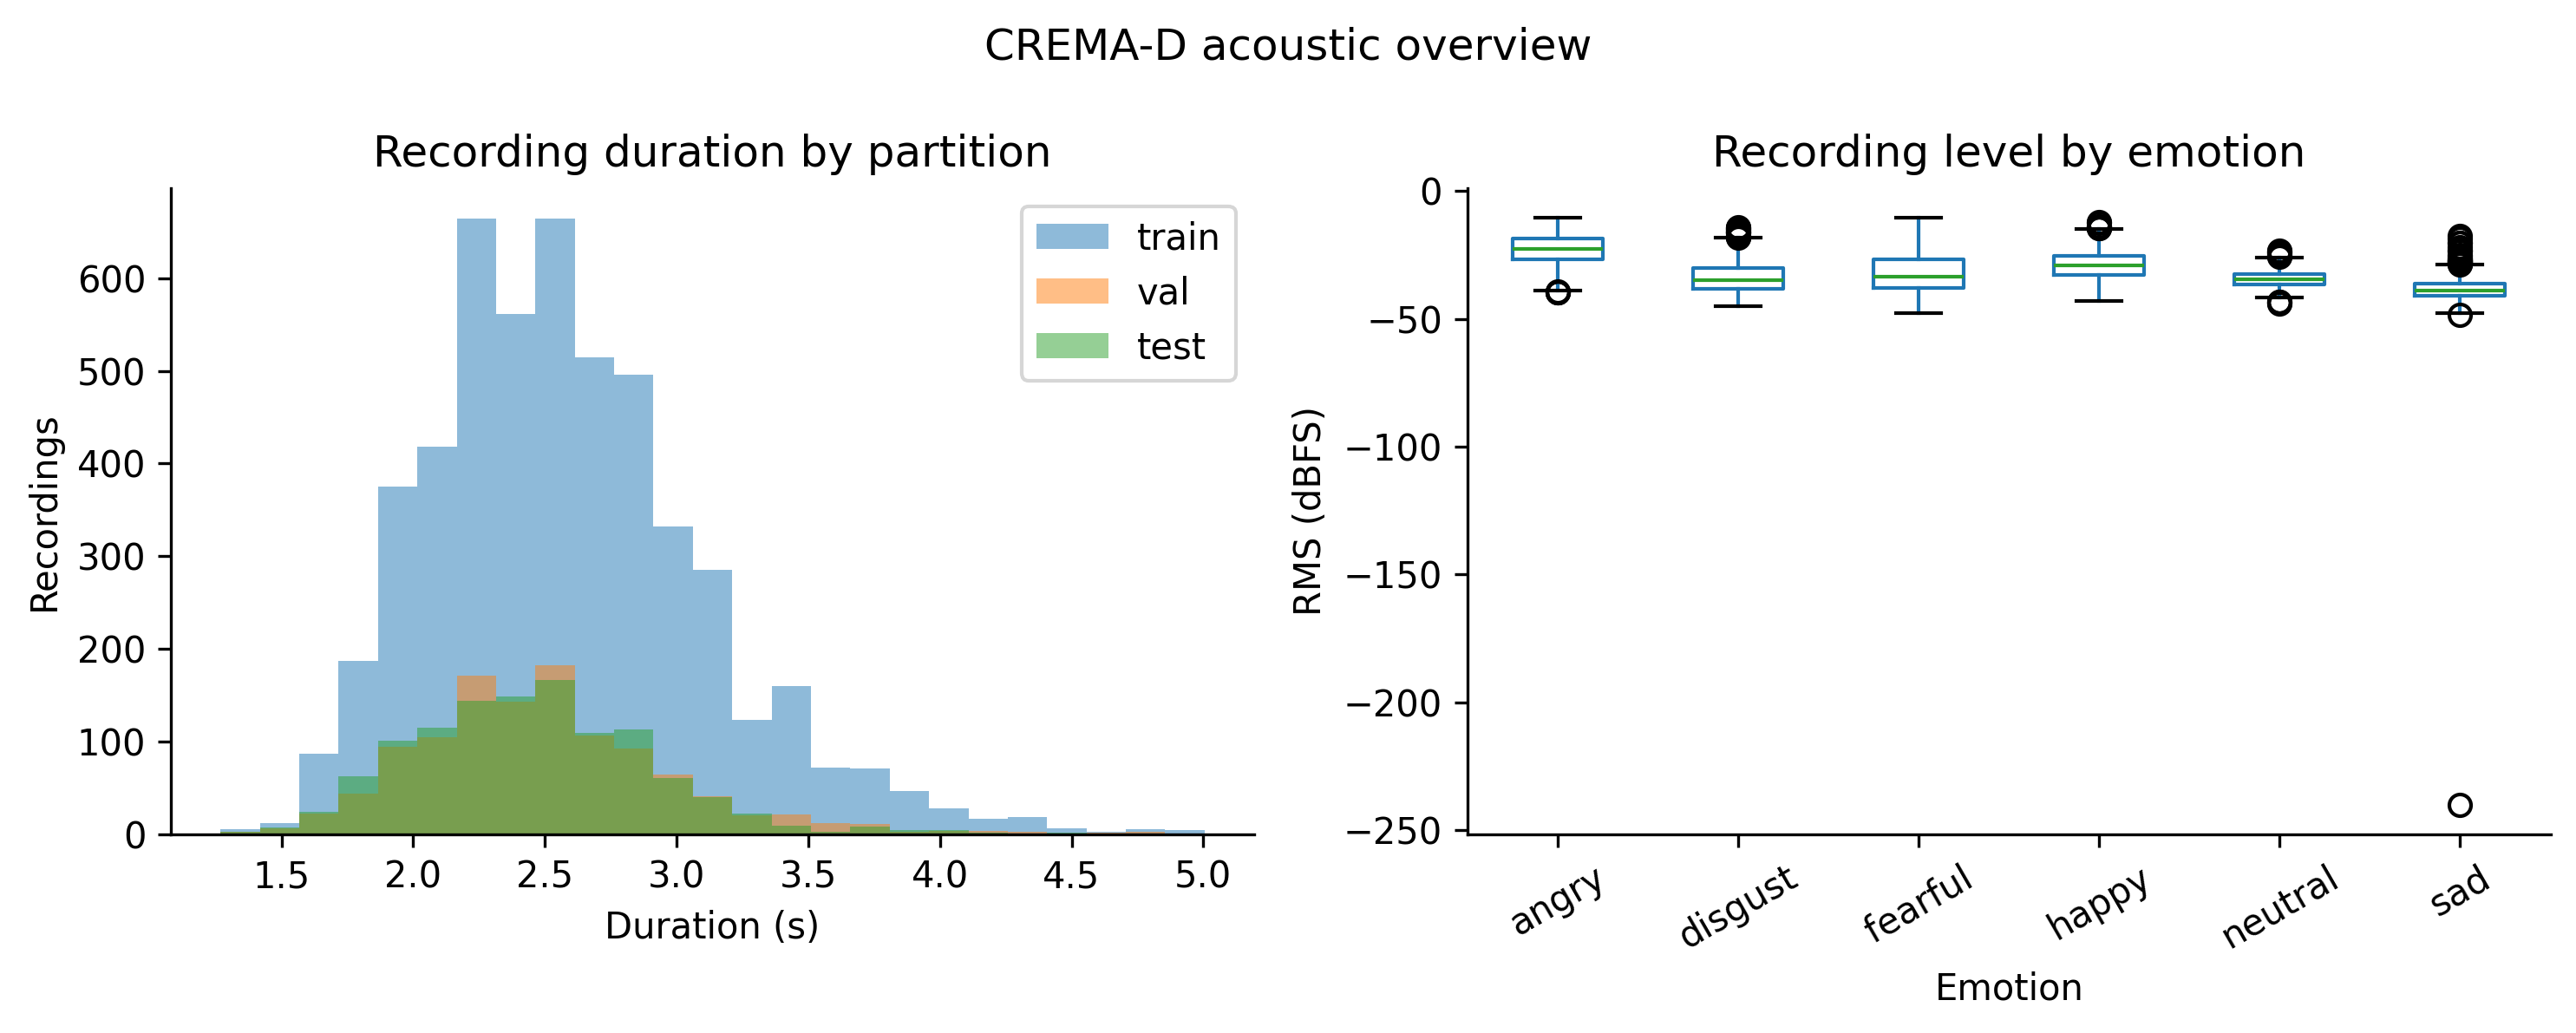

In [21]:
MANIFEST_PATH = RUN_ROOT / 'split_manifest.csv'
if RUN_MODE == 'smoke':
    audio_location = CACHE_DIR / 'synthetic_audio'
    records = synthetic_audio_fixture(audio_location)
    records.to_csv(MANIFEST_PATH, index=False, lineterminator='\n')
    corpus = AudioCorpus(records, CACHE_DIR, AUDIT_DIR, audio_location, DATASET_ID)
else:
    corpus = AudioCorpus(None, CACHE_DIR, AUDIT_DIR, AUDIO_DIR, DATASET_ID)
    records = reproduce_manifest(corpus.source_files, MANIFEST_PATH)
    corpus.records = records
audio_statistics, audio_inventory = inspect_audio(corpus, records, AUDIT_DIR, SCOPE)
descriptive_statistics = dataset_statistics(records, audio_statistics, AUDIT_DIR, SCOPE)
display(pd.read_csv(AUDIT_DIR / 'split_class_counts.csv').drop(columns='evidence_scope'))
display(pd.read_csv(AUDIT_DIR / 'speaker_statistics.csv').drop(columns='evidence_scope'))
display(descriptive_statistics.drop(columns='evidence_scope').round(3))
display(Image(filename=str(AUDIT_DIR / 'dataset_distribution.png')))
display(Image(filename=str(AUDIT_DIR / 'audio_distributions.png')))


## 3. Preprocessing and Acoustic Representation

Audio recordings are converted to mono and resampled to 16 kHz. Log-mel spectrograms are extracted using 40 mel bands, an FFT size of 400, a hop length of 320, and a frequency range of 20–7,600 Hz. Sequences are limited to 300 frames (approximately six seconds) to control memory usage. Extracted features are stored in float16 format for efficient reuse.

Normalization statistics are computed using valid training frames only. Each sequence is normalized before padding to avoid including padded values in the calculations.

Data augmentation is applied only during training and includes time scaling, small feature noise, and time and frequency masking. Frequency masking is adjusted to the number of selected mel bands and disabled when only one band is retained.

In [22]:
FULL_PROTOCOL = dict(version='CREMAD_SER', model_seed=42, search_seed=502,
    baseline_epochs=25, hpo_trials_per_model=8, hpo_epochs=8, cv_folds=3, cv_epochs=8,
    feature_sizes=SIZES, final_epochs=25, early_stopping_patience=6, selection='Validation UAR; feature size from training-speaker CV',
    test_policy='Freeze both architectures and baselines before one cached test pass each',
    class_weights='Inverse training frequency, normalized to mean one', cv_schedule='Fixed StepLR, step_size=5, gamma=0.5; independent of evaluation metrics',
    preprocessing='mono; 16k; FFT400; hop320; 40mel; 20-7600Hz; 6s/300frames; float16 cache',
    cnn_padding='Valid-frame BatchNorm, masked convolutions and packed BiLSTM',
    noise_evaluation=dict(seed=502, snr_db=[20, 10, 0], noise='Additive white Gaussian',
    power_window='Mono 16 kHz; first six seconds, including pauses', headroom='One common gain per recording across clean and all SNRs; peak at most 0.99',
    role='Frozen final models only; no model selection'))


In [23]:
def extract_logmel(wave, rate):
    import librosa
    wave = np.asarray(wave, dtype=np.float32)
    if wave.ndim == 2:
        wave = wave.mean(axis=1)
    if wave.ndim != 1 or not len(wave) or (not np.isfinite(wave).all()):
        raise ValueError('Invalid source audio')
    if rate != 16000:
        wave = librosa.resample(wave, orig_sr=rate, target_sr=16000, res_type='soxr_hq')
    wave = wave[:96000]
    mel = librosa.feature.melspectrogram(y=wave, sr=16000, n_fft=400, hop_length=320,
        n_mels=40, fmin=20, fmax=7600, power=2)
    return librosa.power_to_db(mel, ref=1.0).astype(np.float32)[:, :300].astype(np.float16)


In [24]:
class FeatureBank:

    def __init__(self, folder, fingerprint):
        self.folder, self.fingerprint = (Path(folder), fingerprint)

    def get(self, idx):
        a = np.load(self.folder / f'{int(idx):05d}.npy', allow_pickle=False).astype(np.float32)
        if a.shape[0] != 40 or not 1 <= a.shape[1] <= 300 or (not np.isfinite(a).all()):
            raise ValueError('Invalid feature cache')
        return a


In [25]:
def atomic_numpy_save(path, array):
    temporary = Path(path).with_suffix('.pending')
    with temporary.open('wb') as stream:
        np.save(stream, np.ascontiguousarray(array), allow_pickle=False)
    os.replace(temporary, path)


In [26]:
def feature_cache_block(corpus, rows, expected, persistent, local, number):
    identity = dict(audio=[expected[index] for index in rows.idx], rows=rows.to_dict('records'),
        preprocessing=FULL_PROTOCOL['preprocessing'])
    marker = persistent / f'block_{number:04d}.json'
    data_file = persistent / f'block_{number:04d}.npy'
    if marker.exists():
        saved = json.loads(marker.read_text())
        if saved['identity'] != identity:
            raise ValueError('Feature cache does not match the audio or preprocessing settings')
        if all(((local / f"{item['idx']:05d}.npy").exists() and digest(local / f"{item['idx']:05d}.npy") == item['sha256'] for item in saved['features'])):
            return saved['features']
        if digest(data_file) != saved['sha256']:
            raise ValueError('Persistent feature data failed checksum verification')
        block = np.load(data_file, allow_pickle=False)
        offset = 0
        for item in saved['features']:
            path = local / f"{item['idx']:05d}.npy"
            end = offset + item['frames']
            if not path.exists() or digest(path) != item['sha256']:
                atomic_numpy_save(path, block[:, offset:end])
            if digest(path) != item['sha256']:
                raise ValueError('Restored feature file failed checksum verification')
            offset = end
        return saved['features']
    arrays, items = ([], [])
    for record in rows.itertuples():
        waveform, rate, checksum = corpus.read(record)
        if checksum != expected[record.idx]:
            raise ValueError('Audio changed after the dataset audit')
        features = np.ascontiguousarray(extract_logmel(waveform, rate))
        path = local / f'{int(record.idx):05d}.npy'
        atomic_numpy_save(path, features)
        arrays.append(features)
        items.append(dict(idx=int(record.idx), sha256=digest(path), frames=features.shape[1]))
    atomic_numpy_save(data_file, np.concatenate(arrays, axis=1))
    write_json(marker, dict(identity=identity, features=items, sha256=digest(data_file)))
    return items


In [27]:
def extract_feature_bank(corpus, records, inventory, cache_dir, audit_dir):
    feature_dir = Path(cache_dir) / 'features'
    feature_dir.mkdir(parents=True, exist_ok=True)
    expected = inventory.set_index('idx').audio_sha256.to_dict()
    persistent = Path(audit_dir).parent / 'cache' / 'features'
    persistent.mkdir(parents=True, exist_ok=True)
    feature_hashes = []
    for number, start in enumerate(range(0, len(records), 64)):
        block = records.iloc[start:start + 64]
        feature_hashes.extend(feature_cache_block(corpus, block, expected, persistent, feature_dir, number))
    identity = dict(source=corpus.source, manifest=signature(records.to_dict('records')),
        audio=signature(inventory.to_dict('records')), features=feature_hashes, preprocessing=FULL_PROTOCOL['preprocessing'])
    immutable_json(Path(audit_dir) / 'feature_inventory.json', identity)
    return FeatureBank(feature_dir, signature(identity))


In [28]:
def fit_normalizer(bank, rows):
    if set(rows.split) != {'train'}:
        raise ValueError('Normalization must be fitted on training speakers only')
    total = np.zeros(40)
    squared = np.zeros(40)
    n = 0
    for i in rows.idx:
        a = bank.get(i).astype(np.float64)
        total += a.sum(1)
        squared += (a * a).sum(1)
        n += a.shape[1]
    mean = total / n
    std = np.sqrt(np.maximum(squared / n - mean ** 2, 1e-05))
    return (mean, std)


In [29]:
def augment(real):
    import torch.nn.functional as F
    t = real.clone()
    n = t.shape[1]
    if torch.rand(()) < 0.45:
        size = max(1, min(300, round(len(t) * float(torch.empty(()).uniform_(0.94, 1.06)))))
        t = F.interpolate(t.T.unsqueeze(0), size=size, mode='linear', align_corners=False).squeeze(0).T
    if torch.rand(()) < 0.45:
        t += float(torch.empty(()).uniform_(0.01, 0.04)) * torch.randn_like(t)
    if torch.rand(()) < 0.4 and n > 1:
        width = int(torch.randint(1, min(4, n - 1) + 1, (1,)))
        start = int(torch.randint(0, n - width + 1, (1,)))
        t[:, start:start + width] = 0
    if len(t) > 12 and torch.rand(()) < 0.4:
        width = int(torch.randint(1, min(11, len(t)) + 1, (1,)))
        start = int(torch.randint(0, len(t) - width + 1, (1,)))
        t[start:start + width] = 0
    return t


In [30]:
class MelDataset(Dataset):

    def __init__(self, bank, rows, norm, bands, training=False):
        self.bank, self.rows, self.norm, self.bands, self.training = (bank,
            rows.reset_index(drop=True), norm, bands, training)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        r = self.rows.iloc[i]
        mean, std = self.norm
        a = self.bank.get(r.idx)
        x = ((a - mean[:, None]) / std[:, None])[self.bands].T.astype(np.float32)
        real = torch.from_numpy(x.copy())
        if self.training:
            real = augment(real)
        out = torch.zeros(300, len(self.bands))
        out[:len(real)] = real
        return (out, int(r.class_id), len(real))


In [31]:
feature_bank = extract_feature_bank(corpus, records, audio_inventory, CACHE_DIR, AUDIT_DIR)
training_rows = records[records.split == 'train']
training_normalizer = fit_normalizer(feature_bank, training_rows)
example = feature_bank.get(training_rows.iloc[0].idx)
print('Example spectrogram (mel bands, valid frames):', example.shape)
print('Padded model input: (batch, 300 frames, retained bands)')
np.savez(AUDIT_DIR / 'full_training_normalizer.npz', mean=training_normalizer[0], std=training_normalizer[1])


Example spectrogram (mel bands, valid frames): (40, 129)
Padded model input: (batch, 300 frames, retained bands)



## 4. CNN–LSTM and Transformer Architectures

Two deep learning architectures are implemented for six-class speech emotion recognition.

The CNN–LSTM combines convolutional layers for local acoustic feature extraction with a bidirectional LSTM for modeling temporal dependencies. The Transformer uses self-attention and learned positional embeddings to capture relationships across audio frames. Both architectures aggregate valid temporal representations before classification into six emotion categories.

Padding is handled to prevent artificial frames from influencing model representations. The CNN–LSTM uses valid-frame normalization, convolutional masking, and packed LSTM sequences. When insufficient valid values are available for BatchNorm, stored running statistics are used. The Transformer applies attention masks and excludes padded frames during pooling.


In [32]:
def protocol_for(mode):
    if mode not in ('full', 'smoke'):
        raise ValueError('Choose full or smoke explicitly')
    p = copy.deepcopy(FULL_PROTOCOL)
    if mode == 'smoke':
        p.update(baseline_epochs=1, hpo_trials_per_model=2, hpo_epochs=1,
            cv_folds=2, cv_epochs=1, feature_sizes=[40, 1], final_epochs=1)
    return p


In [33]:
def experimental_flow(records, protocol, output_dir, scope):
    """Visualize the experimental workflow and evaluation procedure."""
    plt = plotting()
    figure, axis = plt.subplots(figsize=(11, 6))
    axis.set(xlim=(0, 1), ylim=(0, 1))
    axis.axis('off')
    counts = records.groupby('split').size()
    labels = [(0.5, 0.91, f'{scope}: Speaker-Disjoint Data Partition ({len(records):,} recordings)'),
        (0.25, 0.69, f"Train: {counts['train']:,}\nFit normalization; augment training only"),
        (0.77, 0.69, f"Validation: {counts['val']:,}\nSelect epochs and hyperparameters"),
        (0.25, 0.41, f"{protocol['cv_folds']}-fold training-speaker CV\nFold-local ranking and normalization\nSelect feature count"),
        (0.77, 0.41, 'CNN–LSTM and Transformer: Baselines and HPO\nFinal model training\nSelection by validation UAR'),
        (0.5, 0.1,f"Freeze selected models and configurations\nTest: {counts['test']:,} recordings; evaluate baselines and final models\nPerformance metrics, comparisons, and error analysis")]
    for x, y, label in labels:
        axis.text(x, y, label, ha='center', va='center', fontsize=10, bbox=dict(boxstyle='round,pad=.7',
            facecolor='#edf5f7', edgecolor='#157a8a'))
    for start, end in [((0.5, 0.85), (0.25, 0.76)), ((0.5, 0.85), (0.77, 0.76)),
        ((0.25, 0.62), (0.25, 0.5)), ((0.77, 0.62), (0.77, 0.5)), ((0.45, 0.41),
        (0.53, 0.41)), ((0.77, 0.32), (0.5, 0.2))]:
        axis.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color='#18324a'))
    save_figure(figure, Path(output_dir) / 'experimental_workflow.png', scope)


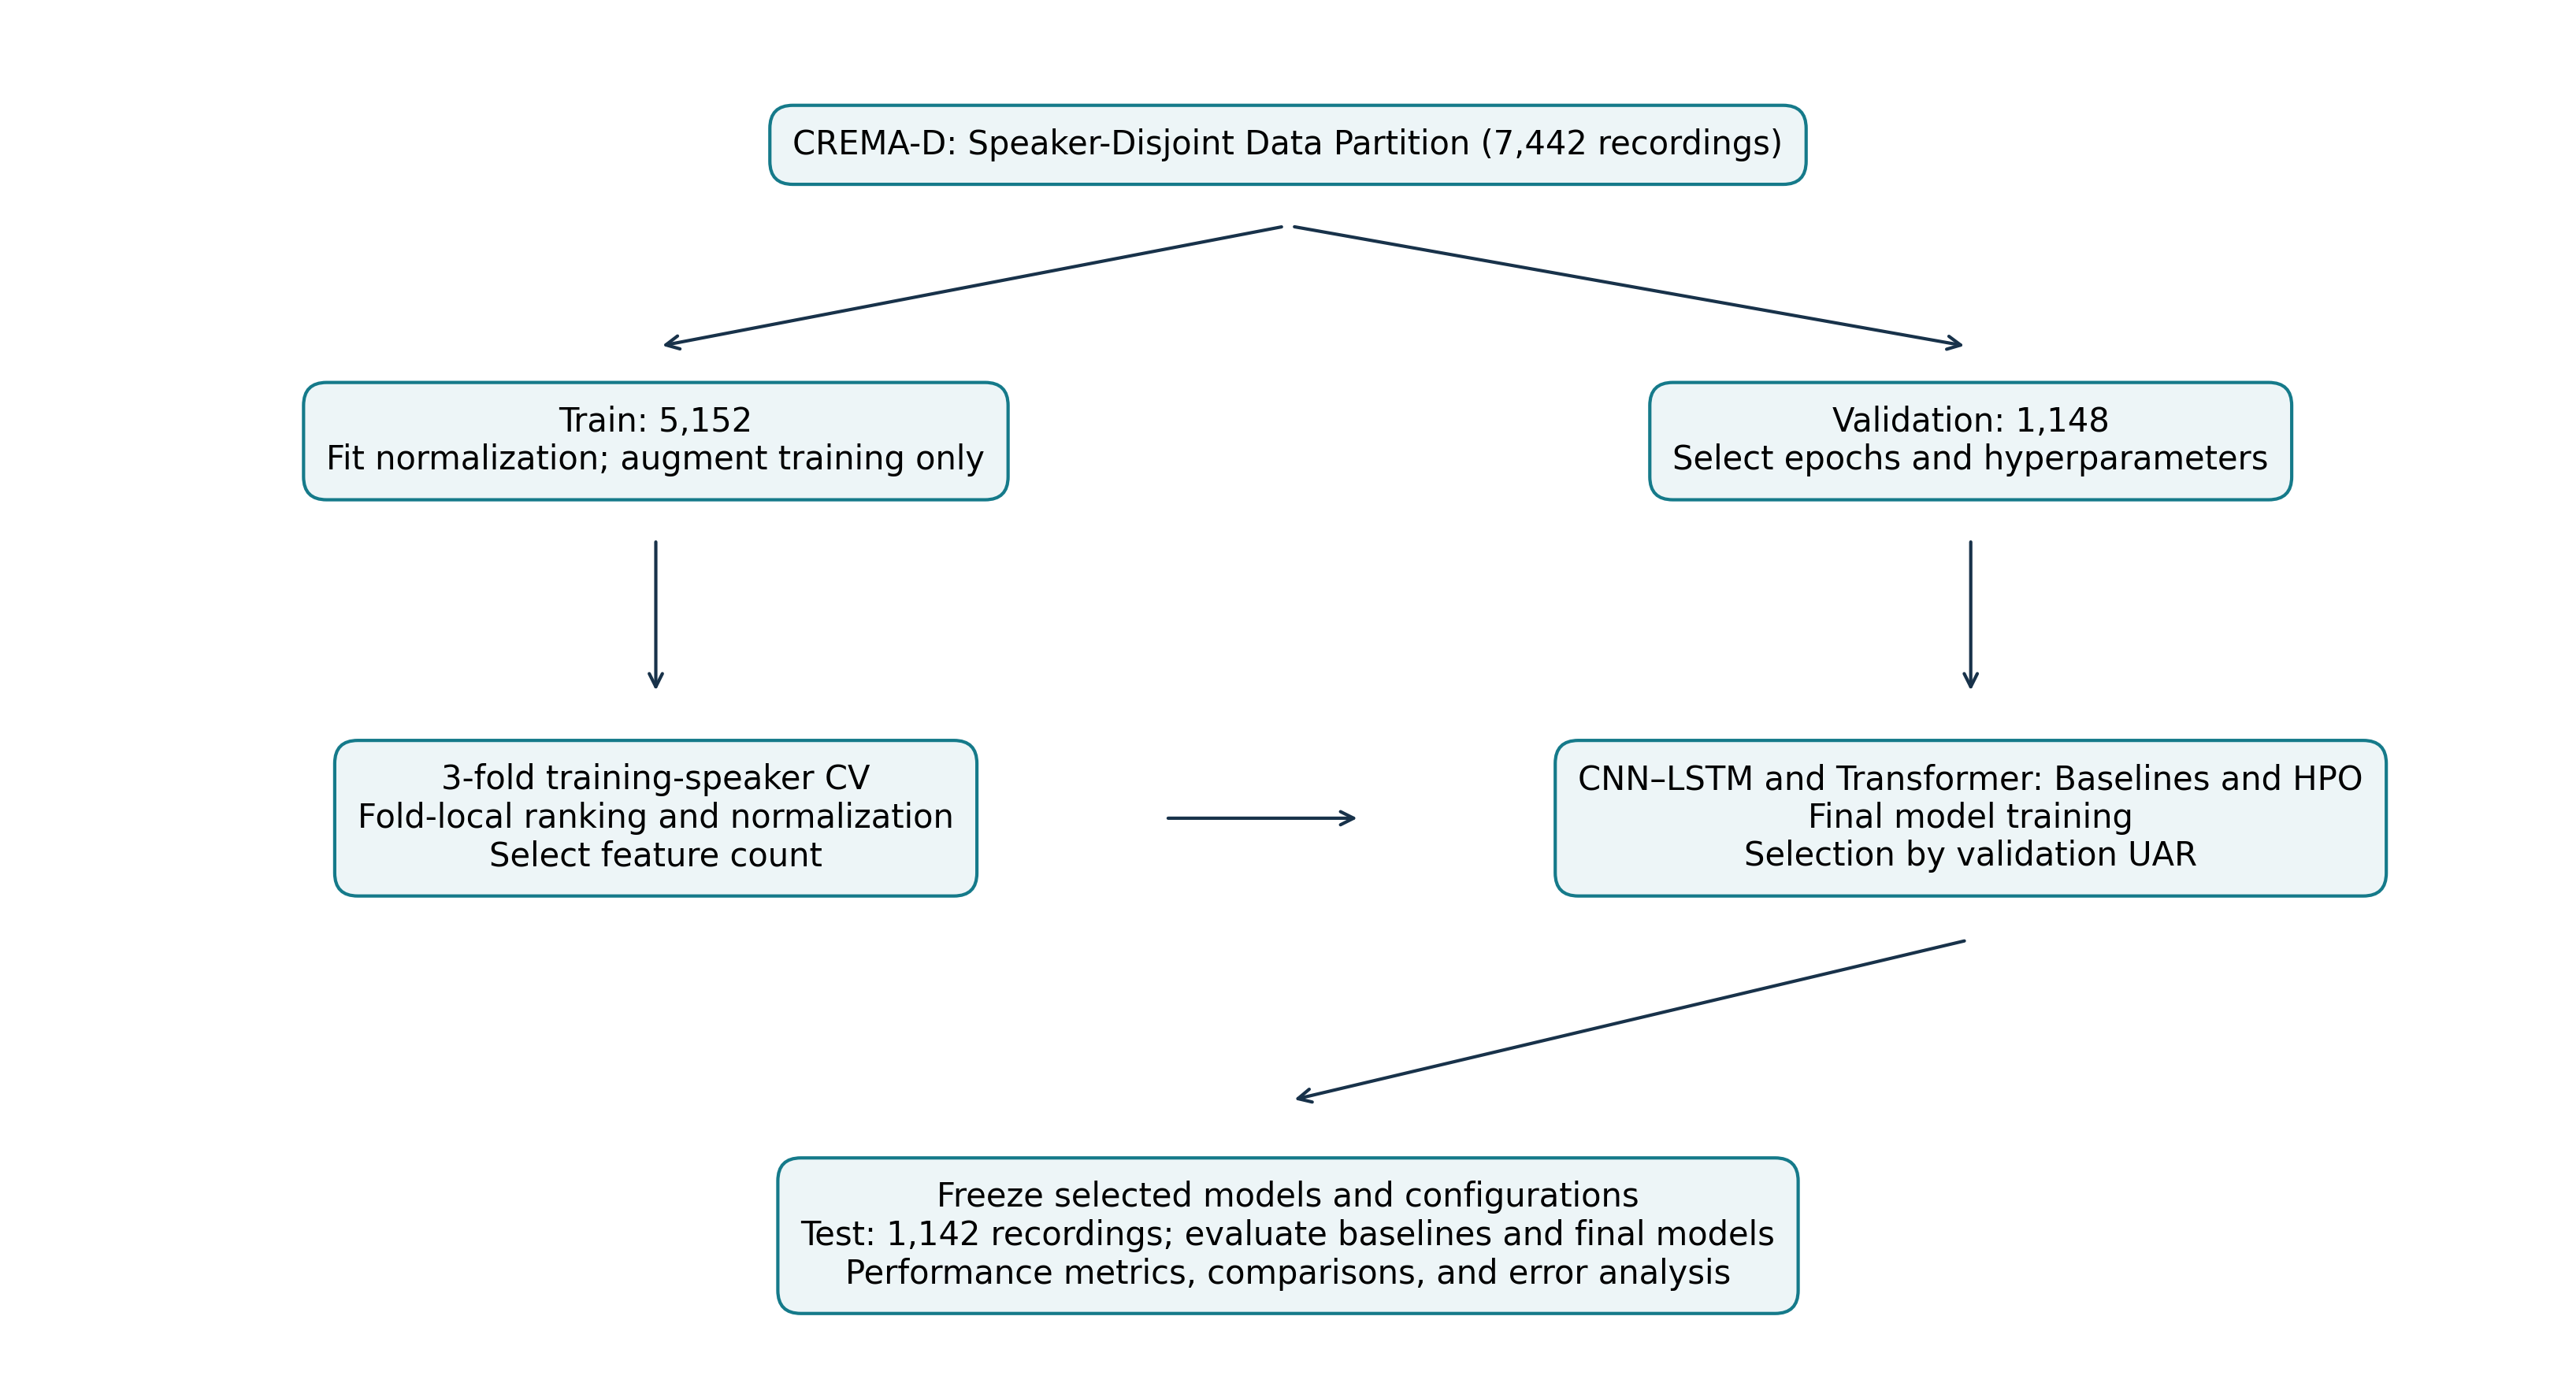

In [34]:
experimental_flow(records, protocol_for(RUN_MODE), AUDIT_DIR, SCOPE)
display(Image(filename=str(AUDIT_DIR / 'experimental_workflow.png')))


In [35]:
def default_config(architecture, mode='full'):
    if architecture not in ('cnn_lstm', 'transformer'):
        raise ValueError('Unknown architecture')
    c = dict(architecture=architecture, lr=0.0003, weight_decay=0.01, dropout=0.25 if architecture == 'cnn_lstm' else 0.1,
        head_dropout=0.2, batch_size=32, hidden=96, width=128, layers=3, heads=4,
        augment=True, scheduler=True)
    if mode == 'smoke':
        c.update(hidden=8, width=16, layers=1, batch_size=24)
    return c


In [36]:
def convolution_lengths(lengths, convolution):
    """PyTorch Conv1d output-length formula, applied to each valid sequence."""
    return (lengths + 2 * convolution.padding[0] - convolution.dilation[0] * (convolution.kernel_size[0] - 1) - 1) // convolution.stride[0] + 1


In [37]:
def masked_convolution(x, lengths, convolution, normalization, activation):
    valid = torch.arange(x.shape[2], device=x.device)[None, :] < lengths[:, None]
    x = convolution(x.masked_fill(~valid[:, None, :], 0))
    lengths = convolution_lengths(lengths, convolution)
    valid = torch.arange(x.shape[2], device=x.device)[None, :] < lengths[:, None]
    frames = x.transpose(1, 2)
    real = frames[valid]
    if normalization.training and len(real) == 1:
        real = torch.nn.functional.batch_norm(real, normalization.running_mean,
            normalization.running_var, normalization.weight, normalization.bias, training=False,
            eps=normalization.eps)
    else:
        real = normalization(real)
    output = torch.zeros_like(frames)
    output[valid] = activation(real).to(output.dtype)
    return (output.transpose(1, 2), lengths)


In [38]:
class CNNLSTM(nn.Module):

    def __init__(self, n_features, config):
        super().__init__()
        h = config['hidden']
        self.conv = nn.Sequential(nn.Conv1d(n_features, 64, 5, padding=2),
            nn.BatchNorm1d(64), nn.GELU(), nn.Conv1d(64, 96, 3, padding=1), nn.BatchNorm1d(96),
            nn.GELU())
        self.rnn = nn.LSTM(96, h, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(config['dropout']), nn.Linear(2 * h, 6))

    def forward(self, x, lengths):
        lengths = torch.as_tensor(lengths, device=x.device)
        if x.ndim != 3 or lengths.shape != (len(x),) or lengths.is_floating_point() or torch.any(lengths < 1) or torch.any(lengths > x.shape[1]):
            raise ValueError('Expected positive integer lengths within the padded sequence')
        x = x[:, :int(lengths.max())].transpose(1, 2)
        for offset in (0, 3):
            x, lengths = masked_convolution(x, lengths, *self.conv[offset:offset + 3])
        packed = nn.utils.rnn.pack_padded_sequence(x.transpose(1, 2), lengths.detach().cpu(),
            batch_first=True, enforce_sorted=False)
        packed, _ = self.rnn(packed)
        x, _ = nn.utils.rnn.pad_packed_sequence(packed, batch_first=True)
        return self.head(x.sum(1) / lengths.unsqueeze(1))


In [39]:
class Transformer(nn.Module):

    def __init__(self, n_features, config):
        super().__init__()
        w = config['width']
        self.in_proj = nn.Linear(n_features, w)
        self.pos = nn.Parameter(torch.zeros(1, 300, w))
        nn.init.normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(w, config['heads'], 2 * w, config['dropout'],
            batch_first=True, activation='gelu')
        self.encoder = nn.TransformerEncoder(layer, config['layers'], enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Dropout(config['head_dropout']), nn.Linear(w, 6))

    def forward(self, x, lengths):
        mask = torch.arange(x.shape[1], device=x.device)[None, :] >= lengths[:, None]
        z = self.encoder(self.in_proj(x) + self.pos[:, :x.shape[1]], src_key_padding_mask=mask)
        return self.head(z.masked_fill(mask.unsqueeze(-1), 0).sum(1) / lengths.clamp(min=1).unsqueeze(1))


In [40]:
def model_for(config, bands):
    return (CNNLSTM if config['architecture'] == 'cnn_lstm' else Transformer)(len(bands), config)


In [41]:
def dimension_preflight(mode='full'):
    torch.set_num_threads(2)
    records = []
    for arch in ['cnn_lstm', 'transformer']:
        for size in SIZES:
            model = model_for(default_config(arch, mode), list(range(size))).eval()
            with torch.inference_mode():
                output = model(torch.zeros(2, 300, size), torch.tensor([1, 300]))
            if output.shape != (2, 6) or not torch.isfinite(output).all():
                raise ValueError('Invalid architecture/subset output')
            records.append(dict(architecture=arch, bands=size, output_shape=list(output.shape),
                parameters=sum((p.numel() for p in model.parameters()))))
    return pd.DataFrame(records)


In [42]:
for architecture in ['cnn_lstm', 'transformer']:
    parameters = default_config(architecture, RUN_MODE)
    model = model_for(parameters, list(range(40)))
    print(architecture, '— trainable parameters:', sum((p.numel() for p in model.parameters())))
    display(model)
dimensions = dimension_preflight(RUN_MODE)
display(dimensions)


cnn_lstm — trainable parameters: 181862


CNNLSTM(
  (conv): Sequential(
    (0): Conv1d(40, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Conv1d(64, 96, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): GELU(approximate='none')
  )
  (rnn): LSTM(96, 96, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Dropout(p=0.25, inplace=False)
    (1): Linear(in_features=192, out_features=6, bias=True)
  )
)

transformer — trainable parameters: 441862


Transformer(
  (in_proj): Linear(in_features=40, out_features=128, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=128, out_features=6, bias=True)
  )
)

,architecture,bands,output_shape,parameters
0,cnn_lstm,40,"[2, 6]",181862
1,cnn_lstm,20,"[2, 6]",175462
2,cnn_lstm,10,"[2, 6]",172262
3,cnn_lstm,5,"[2, 6]",170662
4,cnn_lstm,2,"[2, 6]",169702
5,cnn_lstm,1,"[2, 6]",169382
6,transformer,40,"[2, 6]",441862
7,transformer,20,"[2, 6]",439302
8,transformer,10,"[2, 6]",438022
9,transformer,5,"[2, 6]",437382



## 5. Baseline Experiments

Baseline CNN–LSTM and Transformer models are trained using AdamW with a learning rate of 3 × 10⁻⁴, weight decay of 0.01, and batch size of 32. Class-weighted cross-entropy uses inverse training-class frequencies to address class imbalance. Dropout is set to 0.25 for the CNN–LSTM classification head and 0.10/0.20 for the Transformer encoder and classification head, respectively. Both models use the same training-only data augmentation.

Training is limited to 25 epochs, with early stopping after six consecutive epochs without improvement in validation UAR. Unweighted Average Recall (UAR) gives equal importance to all six emotion classes. Random seed 42 is used for reproducibility, and training checkpoints are saved to support recovery. Learning curves and performance tables summarize the baseline results on the validation set.


In [43]:
def measures(y, probabilities):
    probabilities = np.asarray(probabilities)
    if probabilities.shape != (len(y), 6) or not np.isfinite(probabilities).all():
        raise ValueError('Invalid six-class scores')
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(1), 1, atol=1e-05):
        raise ValueError('Scores are not probabilities')
    pred = probabilities.argmax(1)
    recall = float(recall_score(y, pred, labels=range(6), average='macro', zero_division=0))
    return dict(accuracy=float(accuracy_score(y, pred)), precision_macro=float(precision_score(y,
        pred, labels=range(6), average='macro', zero_division=0)), recall_macro=recall,
        uar=recall, balanced_accuracy=recall, macro_f1=float(f1_score(y, pred, labels=range(6),
        average='macro', zero_division=0)), weighted_f1=float(f1_score(y, pred, labels=range(6),
        average='weighted', zero_division=0)))


In [44]:
def pass_epoch(model, loader, device, weights, optimizer=None, scaler=None):
    model.train(optimizer is not None)
    ys, probabilities = ([], [])
    numerator = denominator = 0.0
    for x, y, lengths in loader:
        x, y, lengths = (x.to(device), y.to(device), lengths.to(device))
        if optimizer is not None:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(optimizer is not None), torch.autocast(device_type=device.type,
            enabled=device.type == 'cuda'):
            logits = model(x, lengths)
            losses = nn.functional.cross_entropy(logits, y, weight=weights, reduction='none')
            mass = weights[y].sum()
            loss = losses.sum() / mass
        if not torch.isfinite(loss):
            raise ValueError('Non-finite loss encountered')
        if optimizer is not None:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1)
            scaler.step(optimizer)
            scaler.update()
        numerator += float(losses.detach().sum())
        denominator += float(mass)
        probabilities.extend(logits.detach().float().softmax(1).cpu().numpy())
        ys.extend(y.cpu().tolist())
    probabilities = np.asarray(probabilities)
    metrics = measures(ys, probabilities)
    metrics['loss'] = numerator / denominator
    return (metrics, np.asarray(ys), probabilities)


In [45]:
def search_configs(architecture, mode='full'):
    p = protocol_for(mode)
    rng = random.Random(p['search_seed'] + (architecture == 'transformer'))
    configs = [default_config(architecture, mode)]
    while len(configs) < p['hpo_trials_per_model']:
        c = default_config(architecture, mode)
        c.update(lr=rng.choice([0.0001, 0.0003, 0.001]), weight_decay=rng.choice([0.001,
            0.01, 0.03]), dropout=rng.choice([0.25, 0.4, 0.5] if architecture == 'cnn_lstm' else [0.1,
            0.2, 0.3]), batch_size=rng.choice([16, 32]))
        if mode == 'full':
            if architecture == 'cnn_lstm':
                c['hidden'] = rng.choice([64, 96])
            else:
                c.update(width=rng.choice([64, 128]), layers=rng.choice([2, 3]))
        if c not in configs:
            configs.append(c)
    if mode == 'full':
        levels = [0.25, 0.4, 0.5] if architecture == 'cnn_lstm' else [0.1, 0.2, 0.3]
        for level in levels:
            observed = [c['dropout'] for c in configs]
            if level not in observed:
                slot = next((i for i in range(1, len(configs)) if observed.count(configs[i]['dropout']) > 1))
                configs[slot]['dropout'] = level
    return configs


In [46]:

def create_experiment(root, rows, bank, mode='full', device=None):
    experiment = SimpleNamespace()
    experiment.mode = mode
    experiment.protocol = protocol_for(mode)
    experiment.rows = validate_manifest(rows, strict=mode == 'full')
    experiment.bank = bank
    experiment.root = Path(root).resolve()

    if 'exported' in [part.lower() for part in experiment.root.parts]:
        raise ValueError('Experiment directory cannot be inside exported files')

    marker = experiment.root / 'study_identity.json'
    if experiment.root.exists() and any(experiment.root.iterdir()) and (not marker.exists()):
        raise ValueError('Experiment directory contains unrelated files')

    experiment.device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
    if mode == 'full' and experiment.device.type != 'cuda':
        raise RuntimeError('Full scientific training requires a Colab GPU')

    experiment.scope = 'CREMA-D' if mode == 'full' else 'Synthetic Test'

    experiment.root.mkdir(parents=True, exist_ok=True)
    experiment.identity = dict(
        protocol=experiment.protocol,
        mode=mode,
        scope=experiment.scope,
        manifest=signature(experiment.rows.to_dict('records')),
        features=bank.fingerprint,
        implementation=implementation_fingerprint(),
        software=runtime_versions()
    )

    immutable_json(marker, experiment.identity)
    immutable_json(
        experiment.root / 'scope.json',
        dict(scope=experiment.scope, scientific_evidence=mode == 'full')
    )

    environment = dict(
        software=experiment.identity['software'],
        platform=platform.platform(),
        device=str(experiment.device),
        gpu=torch.cuda.get_device_name(0) if experiment.device.type == 'cuda' else None
    )

    immutable_json(
        experiment.root / ('environment_' + signature(environment)[:12] + '.json'),
        environment
    )

    os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
    torch.set_num_threads(2)
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

    for arch in ['cnn_lstm', 'transformer']:
        immutable_json(
            experiment.root / (arch + '_search_plan.json'),
            search_configs(arch, mode)
        )

    return experiment


In [47]:
def validate_partition(experiment, rows, allowed):
    if rows.empty or rows.idx.duplicated().any() or (not set(rows.split) <= set(allowed)):
        raise ValueError('Invalid training/assessment partition')
    columns = ['idx', 'source_file', 'speaker', 'label', 'class_id', 'split']
    actual = rows[columns].sort_values('idx').reset_index(drop=True)
    expected = experiment.rows[experiment.rows.idx.isin(rows.idx)][columns].sort_values('idx').reset_index(drop=True)
    if not actual.equals(expected):
        raise ValueError('Partition metadata differs from registered manifest')
    if set(rows.class_id) != set(range(6)):
        raise ValueError('All six classes are required in each partition')


In [48]:
def load_completed_trial(experiment, name):
    folder = experiment.root / name
    result = json.loads((folder / 'result.json').read_text())
    spec = json.loads((folder / 'configuration.json').read_text())
    if result['signature'] != signature(spec) or spec['study'] != signature(experiment.identity):
        raise ValueError('Completed trial identity mismatch')
    for filename, checksum in result['artifacts'].items():
        if digest(folder / filename) != checksum:
            raise ValueError('Completed trial artifact changed: ' + name + '/' + filename)
    return result


In [49]:
def training_components(experiment, specification, training, assessment):
    parameters = specification['config']
    seed = specification['seed']
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if experiment.device.type == 'cuda':
        torch.cuda.manual_seed_all(seed)
    normalizer = fit_normalizer(experiment.bank, training)
    generator = torch.Generator().manual_seed(seed)
    model = model_for(parameters, specification['bands']).to(experiment.device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=parameters['lr'], weight_decay=parameters['weight_decay'])
    scaler = torch.amp.GradScaler(experiment.device.type, enabled=experiment.device.type == 'cuda')
    if specification['selection'] == 'last':
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    else:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,
            mode='max', factor=0.5, patience=2, min_lr=1e-05)
    counts = training.class_id.value_counts().reindex(range(6)).to_numpy()
    weights = torch.tensor(counts.sum() / counts, dtype=torch.float32, device=experiment.device)
    weights /= weights.mean()
    train_data = MelDataset(experiment.bank, training, normalizer, specification['bands'], parameters['augment'])
    valid_data = MelDataset(experiment.bank, assessment, normalizer, specification['bands'])
    train_loader = DataLoader(train_data, batch_size=parameters['batch_size'],
        shuffle=True, generator=generator, num_workers=0)
    valid_loader = DataLoader(valid_data, batch_size=parameters['batch_size'], num_workers=0)
    return SimpleNamespace(model=model, optimizer=optimizer, scaler=scaler,
        scheduler=scheduler, normalizer=normalizer, generator=generator, weights=weights,
        train_loader=train_loader, valid_loader=valid_loader, history=[], best_model=None,
        best_epoch=None, best_score=-1.0, bad_epochs=0, epoch=0, finished_training=False)


In [50]:
def restore_training(state, specification, checkpoint, device):
    if not checkpoint.exists():
        return
    saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
    if saved['signature'] != signature(specification):
        raise ValueError('Checkpoint configuration differs from this trial')
    for current, previous in zip(state.normalizer, [saved['normalizer_mean'], saved['normalizer_std']]):
        if not np.array_equal(current, previous):
            raise ValueError('Training normalizer changed')
    for component in ['model', 'optimizer', 'scaler', 'scheduler']:
        getattr(state, component).load_state_dict(saved[component])
    for key in ['history', 'epoch', 'best_model', 'best_epoch', 'best_score', 'bad_epochs', 'finished_training']:
        setattr(state, key, saved[key])
    random.setstate(saved['rng_python'])
    np.random.set_state(saved['rng_numpy'])
    torch.set_rng_state(saved['rng_torch'])
    state.generator.set_state(saved['rng_loader'])
    if device.type == 'cuda':
        torch.cuda.set_rng_state_all(saved['rng_cuda'])


In [51]:
def complete_epoch(state, specification, device):
    start_time = time.perf_counter()
    training, _, _ = pass_epoch(state.model, state.train_loader, device, state.weights, state.optimizer, state.scaler)
    validation = None
    if specification['selection'] == 'best_val':
        validation, _, _ = pass_epoch(state.model, state.valid_loader, device, state.weights)
        state.scheduler.step(validation['uar'])
    else:
        state.scheduler.step()
    state.epoch += 1
    score = validation['uar'] if validation is not None else float(state.epoch)
    if score > state.best_score:
        state.best_score = score
        state.best_epoch = state.epoch
        state.bad_epochs = 0
        state.best_model = {name: value.detach().cpu().clone() for name, value in state.model.state_dict().items()}
    else:
        state.bad_epochs += 1
    patience = specification['patience']
    state.finished_training = state.epoch == specification['epochs'] or bool(patience and state.bad_epochs >= patience)
    state.history.append(dict(epoch=state.epoch, train=training, validation=validation,
        lr=state.optimizer.param_groups[0]['lr'], seconds=time.perf_counter() - start_time))


In [52]:
def save_training_progress(state, specification, checkpoint, device):
    saved = dict(signature=signature(specification), epoch=state.epoch, model=state.model.state_dict(),
        optimizer=state.optimizer.state_dict(), scaler=state.scaler.state_dict(),
        scheduler=state.scheduler.state_dict(), history=state.history, best_model=state.best_model,
        best_epoch=state.best_epoch, best_score=state.best_score, bad_epochs=state.bad_epochs,
        finished_training=state.finished_training, normalizer_mean=state.normalizer[0],
        normalizer_std=state.normalizer[1], rng_python=random.getstate(), rng_numpy=np.random.get_state(),
        rng_torch=torch.get_rng_state(), rng_loader=state.generator.get_state(),
        rng_cuda=torch.cuda.get_rng_state_all() if device.type == 'cuda' else [])
    atomic_torch_save(saved, checkpoint)
    write_json(checkpoint.parent / 'history.json', state.history)


In [53]:
def scores_frame(rows, probabilities, scope):
    measures(rows.class_id, probabilities)
    frame = rows[['idx', 'source_file', 'speaker', 'label', 'class_id', 'split']].reset_index(drop=True).copy()
    for i, label in enumerate(LABELS):
        frame['score_' + label] = probabilities[:, i]
    frame['prediction_id'] = probabilities.argmax(1)
    frame['prediction'] = [LABELS[i] for i in frame.prediction_id]
    frame['confidence'] = probabilities.max(1)
    frame['correct'] = frame.class_id == frame.prediction_id
    frame['evidence_scope'] = scope
    return frame


In [54]:
def save_trial_result(experiment, state, folder, name, specification, assessment):
    state.model.load_state_dict(state.best_model)
    metrics, _, probabilities = pass_epoch(state.model, state.valid_loader, experiment.device, state.weights)
    scores_frame(assessment, probabilities, experiment.scope).to_csv(folder / 'assessment_predictions.csv',
        index=False)
    np.savez(folder / 'normalizer.npz', mean=state.normalizer[0], std=state.normalizer[1],
        bands=np.asarray(specification['bands']))
    atomic_torch_save(dict(model=state.best_model, config=specification['config'],
        bands=specification['bands'], labels=LABELS, selected_epoch=state.best_epoch,
        scope=experiment.scope, signature=signature(specification)), folder / 'best.pt')
    artifacts = ['resume.pt', 'best.pt', 'normalizer.npz', 'history.json', 'assessment_predictions.csv']
    result = dict(signature=signature(specification), name=name, stage=name.split('_')[0],
        scope=experiment.scope, config=specification['config'], bands=specification['bands'],
        assessment=metrics, selected_epoch=state.best_epoch, epochs_completed=state.epoch,
        budget_epochs=specification['epochs'], status='complete', training_seconds=sum((row['seconds'] for row in state.history)),
        parameters=sum((parameter.numel() for parameter in state.model.parameters())),
        stop_reason='early_stopping' if state.epoch < specification['epochs'] else 'budget',
        artifacts={name: digest(folder / name) for name in artifacts})
    write_json(folder / 'result.json', result)
    write_json(folder / 'status.json', dict(status='complete', scope=experiment.scope, trial=name))
    return result


In [55]:
def fit_trial(experiment, folder, name, specification, training, assessment, stop_after=None):
    state = training_components(experiment, specification, training, assessment)
    checkpoint = folder / 'resume.pt'
    restore_training(state, specification, checkpoint, experiment.device)
    while not state.finished_training:
        complete_epoch(state, specification, experiment.device)
        save_training_progress(state, specification, checkpoint, experiment.device)
        validation = state.history[-1]['validation']
        if state.finished_training or state.epoch == 1 or state.epoch % 5 == 0:
            print(name, f"epoch {state.epoch}/{specification['epochs']}",
                'validation UAR:', None if validation is None else round(validation['uar'],
                4), flush=True)
        if stop_after is not None and state.epoch >= stop_after and (not state.finished_training):
            write_json(folder / 'status.json', dict(status='interrupted',
                scope=experiment.scope, trial=name, completed_epochs=state.epoch))
            return None
    write_json(folder / 'history.json', state.history)
    return save_trial_result(experiment, state, folder, name, specification, assessment)


In [56]:
def train_trial(experiment, name, config, training, assessment, bands, epochs,
    selection='best_val', patience=0, stop_after=None):
    if not name.replace('_', '').isalnum():
        raise ValueError('Unsafe trial ID')
    validate_partition(experiment, training, ['train'])
    validate_partition(experiment, assessment, ['train', 'val'])
    if set(training.speaker) & set(assessment.speaker):
        raise ValueError('Speaker overlap')
    if selection not in ('best_val', 'last') or (selection == 'best_val' and set(assessment.split) != {'val'}):
        raise ValueError('CV assessment cannot select epochs')
    if selection == 'last' and patience:
        raise ValueError('CV requires a fixed training budget')
    bands = sorted(set(map(int, bands)))
    if not bands or bands[0] < 0 or bands[-1] >= 40:
        raise ValueError('Invalid feature subset')
    spec = dict(study=signature(experiment.identity), seed=experiment.protocol['model_seed'],
        config=config, training_ids=training.idx.astype(int).tolist(), assessment_ids=assessment.idx.astype(int).tolist(),
        bands=bands, epochs=epochs, selection=selection, patience=patience, scope=experiment.scope)
    folder = experiment.root / name
    if (experiment.root / 'frozen_selection.json').exists() and (not (folder / 'result.json').exists()):
        raise ValueError('Model selection is frozen; additional training is not allowed')
    folder.mkdir(exist_ok=True)
    immutable_json(folder / 'configuration.json', spec)
    if (folder / 'result.json').exists():
        return load_completed_trial(experiment, name)
    status = folder / 'status.json'
    write_json(status, dict(status='running', scope=experiment.scope, trial=name))
    try:
        return fit_trial(experiment, folder, name, spec, training, assessment, stop_after)
    except BaseException as exc:
        write_json(status, dict(status='interrupted' if isinstance(exc, (KeyboardInterrupt,
            SystemExit)) else 'failed', trial=name, scope=experiment.scope, error=repr(exc),
            resume_checkpoint=(folder / 'resume.pt').exists()))
        with (folder / 'attempts.jsonl').open('a', encoding='utf-8') as stream:
            stream.write(json.dumps(dict(at=datetime.now(timezone.utc).isoformat(), error=repr(exc))) + '\n')
        raise


In [57]:
def learning_curves(folder, result, scope):
    destination = folder / 'learning_curves.png'
    if destination.exists():
        return
    history = json.loads((folder / 'history.json').read_text())
    plt = plotting()
    fig, axes = plt.subplots(2, 2, figsize=(10, 6))
    for ax, metric in zip(axes.flat, ['loss', 'accuracy', 'macro_f1', 'uar']):
        for partition, color in [('train', '#157a8a'), ('validation', '#e0a13a')]:
            selected = [h for h in history if h[partition] is not None]
            if selected:
                ax.plot([h['epoch'] for h in selected], [h[partition][metric] for h in selected],
                    marker='.', label=partition, color=color)
        ax.axvline(result['selected_epoch'], color='gray', linestyle=':', label='Selected epoch')
        ax.set(xlabel='Epoch', ylabel={'loss': 'Loss', 'accuracy': 'Accuracy',
            'macro_f1': 'Macro F1', 'uar': 'UAR'}[metric])
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.suptitle(f"Learning Curves — {result['name']}")
    save_figure(fig, destination, scope)


In [58]:
def export_trials(experiment):
    summary_dir = experiment.root / 'summary'
    summary_dir.mkdir(exist_ok=True)
    rows, statuses = ([], [])
    for path in sorted(experiment.root.glob('*/configuration.json')):
        folder = path.parent
        specification = json.loads(path.read_text())
        status_file = folder / 'status.json'
        status = json.loads(status_file.read_text()) if status_file.exists() else {'status': 'pending'}
        if (folder / 'result.json').exists():
            status = {'status': 'complete'}
        statuses.append(dict(trial=folder.name, status=status['status'], scope=experiment.scope))
        if not (folder / 'result.json').exists():
            continue
        result = load_completed_trial(experiment, folder.name)
        rows.append(dict(trial=result['name'], stage=result['stage'], features=len(result['bands']),
            bands=json.dumps(result['bands']), best_epoch=result['selected_epoch'], epochs=result['epochs_completed'],
            training_seconds=result['training_seconds'], parameters=result['parameters'],
            seed=specification['seed'], **result['config'], **result['assessment'], status='complete',
            scope=experiment.scope))
        learning_curves(folder, result, experiment.scope)
    table = pd.DataFrame(rows)
    pd.DataFrame(statuses).to_csv(summary_dir / 'trial_status.csv', index=False)
    if not table.empty:
        table.to_csv(summary_dir / 'completed_trials.csv', index=False)
        for stage in ['baseline', 'hpo', 'feature', 'final']:
            table[table.stage == stage].to_csv(summary_dir / (stage + '_results.csv'), index=False)
    return table


In [59]:
def train_baselines(experiment):
    train, val = (experiment.rows[experiment.rows.split == 'train'], experiment.rows[experiment.rows.split == 'val'])
    return [train_trial(experiment, 'baseline_' + arch, default_config(arch,
        experiment.mode), train, val, list(range(40)), experiment.protocol['baseline_epochs'],
        patience=experiment.protocol['early_stopping_patience']) for arch in ['cnn_lstm',
        'transformer']]


,architecture,lr,weight_decay,dropout,head_dropout,batch_size,hidden,width,layers,heads,augment,scheduler
0,cnn_lstm,0.0003,0.01,0.25,0.2,32,96,128,3,4,True,True
1,transformer,0.0003,0.01,0.10,0.2,32,96,128,3,4,True,True


baseline_cnn_lstm epoch 1/25 validation UAR: 0.4306
baseline_cnn_lstm epoch 5/25 validation UAR: 0.5118
baseline_cnn_lstm epoch 10/25 validation UAR: 0.5636
baseline_cnn_lstm epoch 15/25 validation UAR: 0.5917
baseline_cnn_lstm epoch 20/25 validation UAR: 0.5789
baseline_cnn_lstm epoch 21/25 validation UAR: 0.5809


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


baseline_transformer epoch 1/25 validation UAR: 0.4487
baseline_transformer epoch 5/25 validation UAR: 0.5162
baseline_transformer epoch 10/25 validation UAR: 0.5183
baseline_transformer epoch 15/25 validation UAR: 0.5513
baseline_transformer epoch 20/25 validation UAR: 0.553
baseline_transformer epoch 22/25 validation UAR: 0.5512


,architecture,best_epoch,accuracy,macro_f1,uar,training_seconds
0,cnn_lstm,15,0.5880,0.5795,0.5917,246.5216
1,transformer,16,0.5566,0.5507,0.5594,212.5740


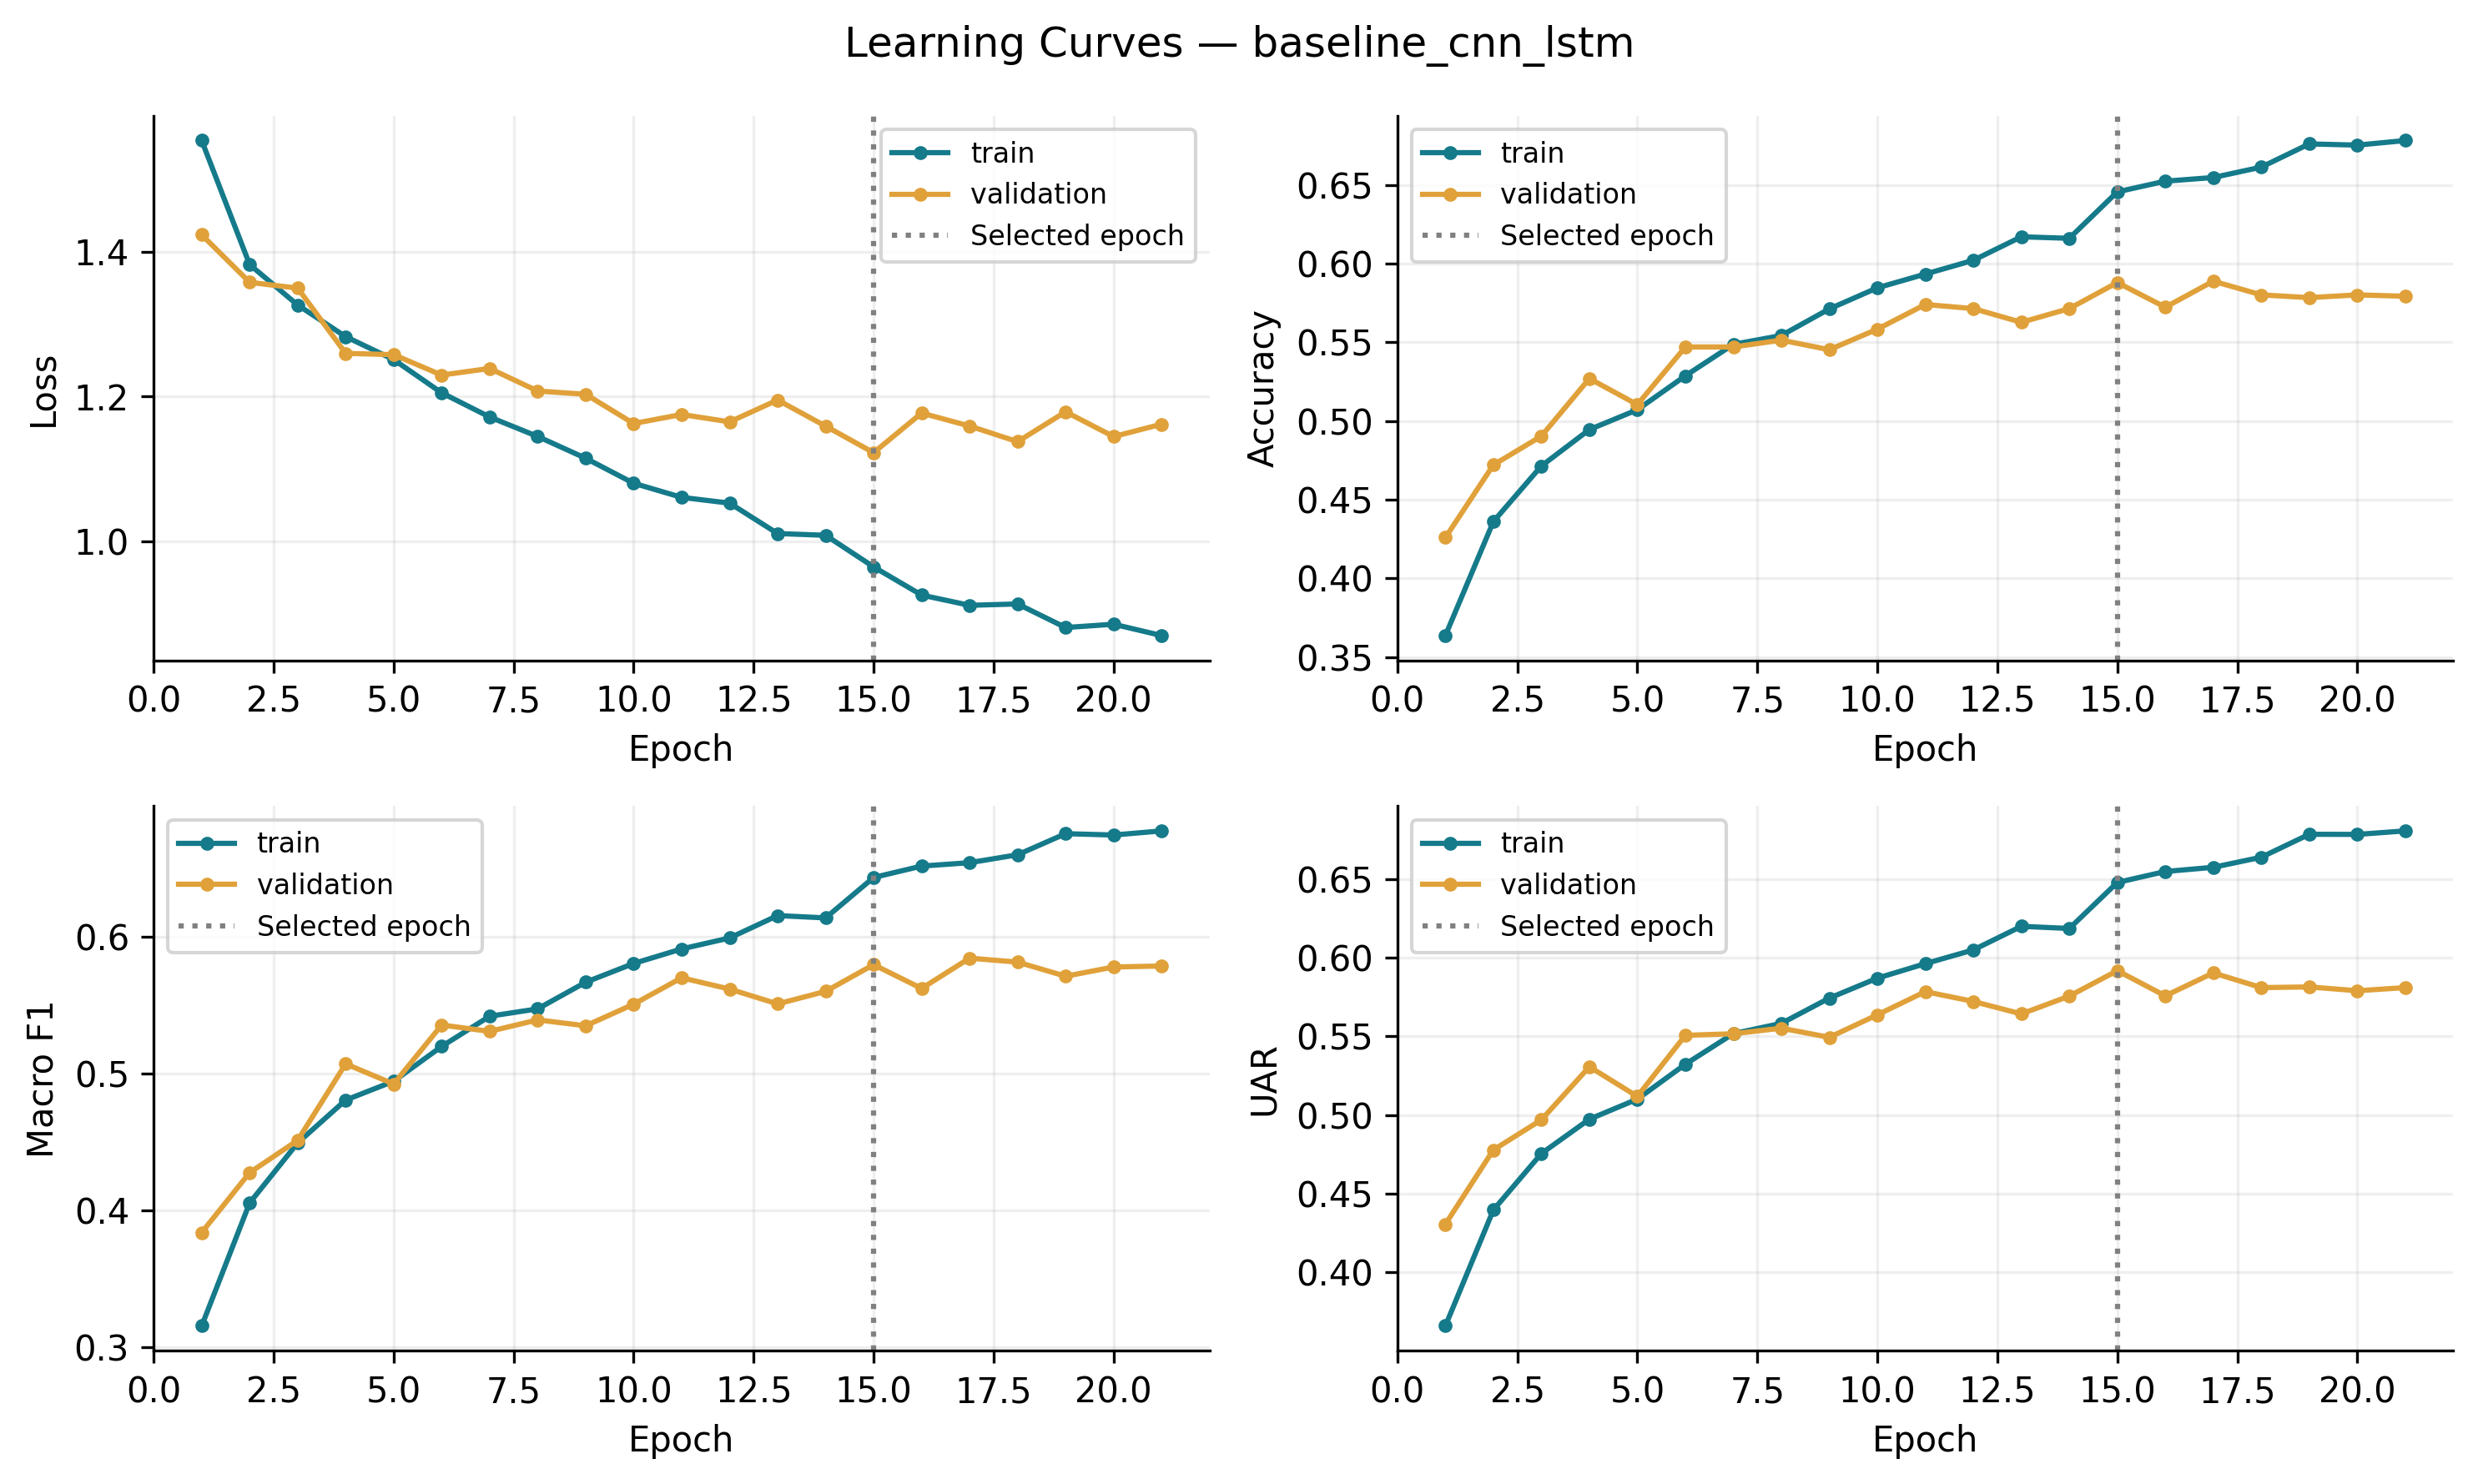

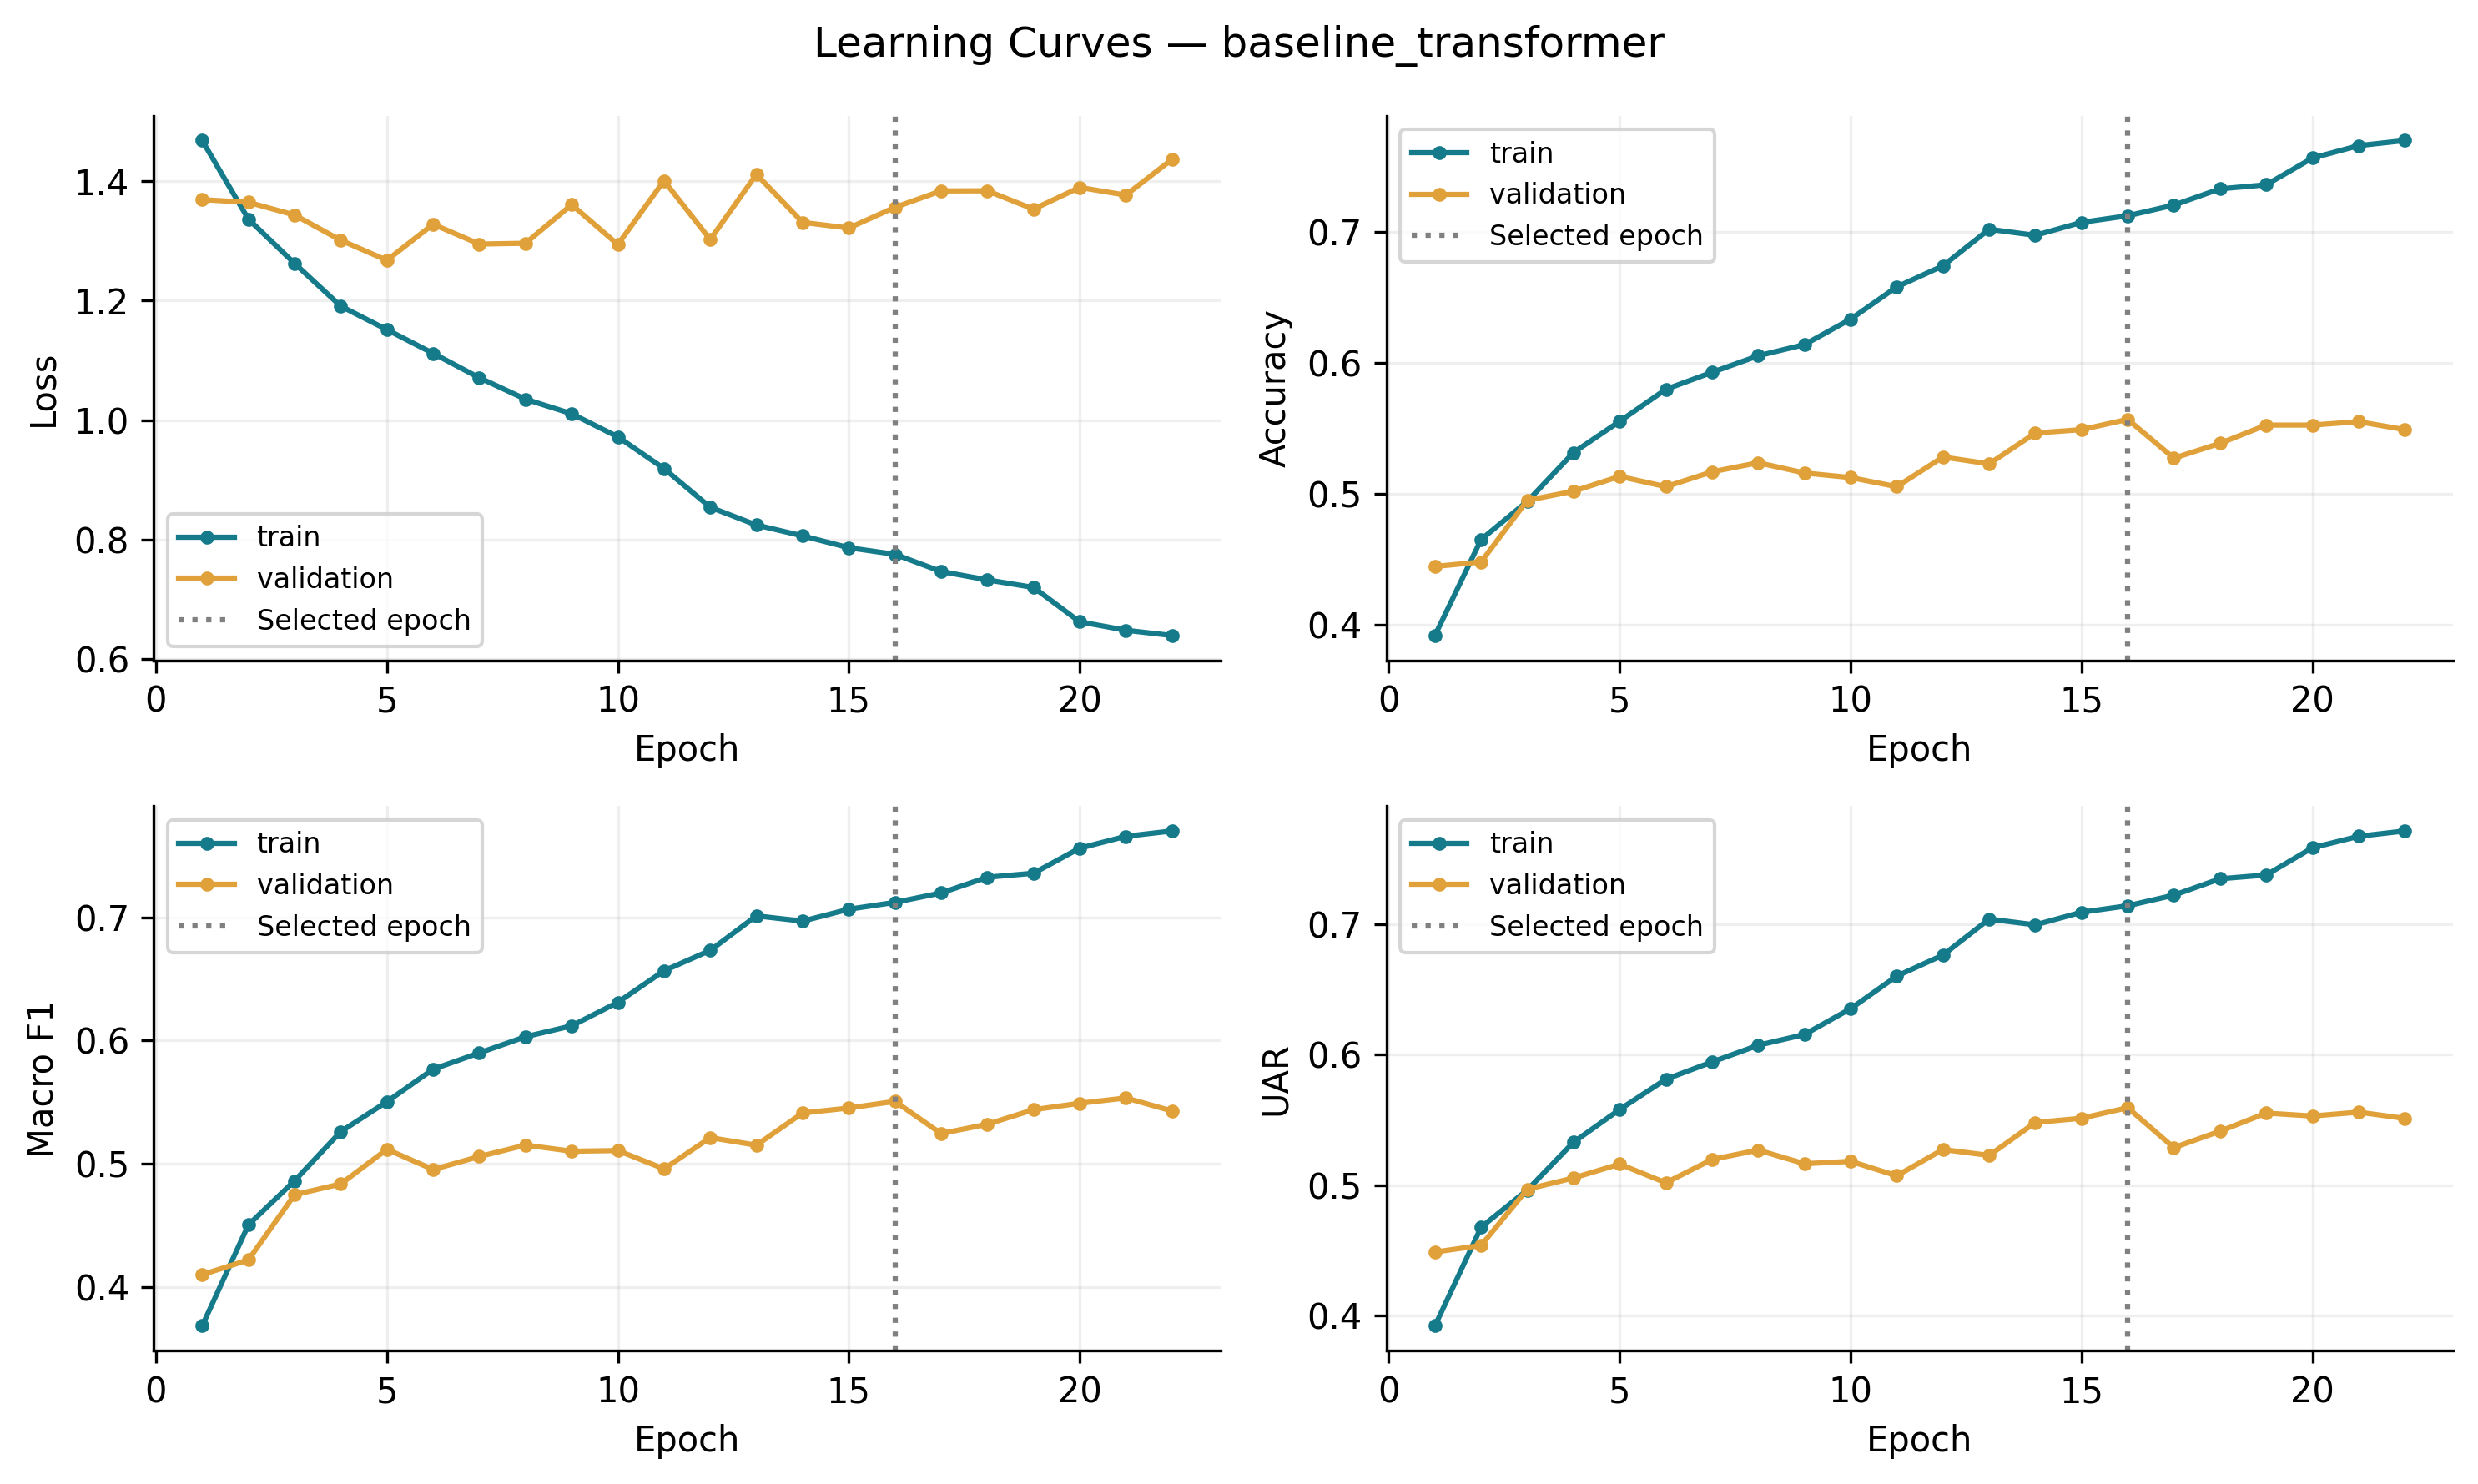

In [60]:
experiment = create_experiment(RUN_ROOT / 'complete_experiments', records, feature_bank, RUN_MODE)
dimensions.to_csv(experiment.root / 'dimension_preflight.csv', index=False)
display(pd.DataFrame([default_config(model, RUN_MODE) for model in ['cnn_lstm', 'transformer']]))
baseline_results = train_baselines(experiment)
trials = export_trials(experiment)
display(trials[trials.stage == 'baseline'][['architecture', 'best_epoch',
    'accuracy', 'macro_f1', 'uar', 'training_seconds']].round(4))
for architecture in ['cnn_lstm', 'transformer']:
    display(Image(filename=str(experiment.root / ('baseline_' + architecture) / 'learning_curves.png')))


Training curves include augmentation and dropout; validation uses evaluation mode. Assess validation trends alongside training loss rather than treating their raw gap as a clean generalization estimate. Accuracy, Macro F1 and UAR are reported separately; UAR is the primary selection measure.

## 6. Hyperparameter optimization
Each architecture receives eight predeclared configurations and eight epochs per trial. The seeded random search varies learning rate, decay, dropout, batch size and recurrent width or Transformer width/depth. A coverage check guarantees all three dropout levels within the fixed budget. Trial 0 is an equal-budget baseline control.

Configurations and checkpoint epochs are selected by validation UAR; exact ties favor the earlier trial. The finite budget makes the search feasible on Colab. Tables retain every trial; plots describe joint-search associations rather than isolated parameter effects.

In [61]:
for architecture in ['cnn_lstm', 'transformer']:
    display(pd.DataFrame(search_configs(architecture, RUN_MODE)))


,architecture,lr,weight_decay,dropout,head_dropout,batch_size,hidden,width,layers,heads,augment,scheduler
0,cnn_lstm,0.0003,0.010,0.25,0.2,32,96,128,3,4,True,True
1,cnn_lstm,0.0010,0.010,0.40,0.2,32,64,128,3,4,True,True
2,cnn_lstm,0.0003,0.030,0.50,0.2,32,64,128,3,4,True,True
3,cnn_lstm,0.0001,0.010,0.25,0.2,16,96,128,3,4,True,True
4,cnn_lstm,0.0010,0.030,0.25,0.2,16,64,128,3,4,True,True
5,cnn_lstm,0.0010,0.001,0.25,0.2,16,64,128,3,4,True,True
6,cnn_lstm,0.0001,0.030,0.25,0.2,16,96,128,3,4,True,True
7,cnn_lstm,0.0001,0.001,0.25,0.2,16,64,128,3,4,True,True


,architecture,lr,weight_decay,dropout,head_dropout,batch_size,hidden,width,layers,heads,augment,scheduler
0,transformer,0.0003,0.010,0.1,0.2,32,96,128,3,4,True,True
1,transformer,0.0001,0.001,0.2,0.2,16,96,128,3,4,True,True
2,transformer,0.0001,0.030,0.1,0.2,16,96,128,2,4,True,True
3,transformer,0.0001,0.001,0.3,0.2,32,96,128,2,4,True,True
4,transformer,0.0001,0.030,0.3,0.2,32,96,128,3,4,True,True
5,transformer,0.0003,0.030,0.2,0.2,32,96,128,3,4,True,True
6,transformer,0.0001,0.010,0.2,0.2,16,96,128,2,4,True,True
7,transformer,0.0010,0.010,0.1,0.2,16,96,64,2,4,True,True


In [62]:
def run_hpo(experiment, max_new_trials=None):
    results, new = ([], 0)
    train, val = (experiment.rows[experiment.rows.split == 'train'], experiment.rows[experiment.rows.split == 'val'])
    for arch in ['cnn_lstm', 'transformer']:
        for i, config in enumerate(search_configs(arch, experiment.mode)):
            name = f'hpo_{arch}_{i:02d}'
            done = (experiment.root / name / 'result.json').exists()
            if not done and max_new_trials is not None and (new >= max_new_trials):
                continue
            results.append(train_trial(experiment, name, config, train, val,
                list(range(40)), experiment.protocol['hpo_epochs']))
            new += not done
    return results


In [63]:
def hpo_figures(experiment, trials):
    plt = plotting()
    for architecture in ['cnn_lstm', 'transformer']:
        selected = trials[(trials.stage == 'hpo') & (trials.architecture == architecture)]
        if selected.empty:
            continue
        parameters = ['lr', 'weight_decay', 'dropout', 'batch_size']
        parameters += ['hidden'] if architecture == 'cnn_lstm' else ['width', 'layers']
        figure, axes = plt.subplots(2, 3, figsize=(11, 6))
        for axis, parameter in zip(axes.flat, parameters):
            for metric, label, color, marker in [('accuracy', 'Accuracy',
                '#446688', 'o'), ('macro_f1', 'Macro F1', '#e0a13a', 'x'), ('uar', 'UAR',
                '#157a8a', '+')]:
                axis.scatter(selected[parameter], selected[metric], label=label, color=color, marker=marker)
            parameter_label = {'lr': 'Learning rate', 'hidden': 'LSTM hidden units',
                'width': 'Embedding dimension', 'layers': 'Encoder layers'}
            axis.set(xlabel=parameter_label.get(parameter, parameter.replace('_',
                ' ').capitalize()), ylabel='Validation score', ylim=(0, 1))
            axis.grid(alpha=0.2)
            if parameter == 'lr':
                axis.set_xscale('log')
        if len(parameters) < 6:
            axes.flat[-1].axis('off')
        axes.flat[0].legend(fontsize=8)
        model_title = 'CNN–LSTM' if architecture == 'cnn_lstm' else 'Transformer'
        figure.suptitle(f'{model_title}: hyperparameter–performance relationships')
        save_figure(figure, experiment.root / 'summary' / f'{architecture}_hpo.png', experiment.scope)
    hpo = trials[trials.stage == 'hpo'].sort_values(['uar', 'trial'], ascending=[False, True])
    best = hpo.drop_duplicates('architecture')
    best.to_csv(experiment.root / 'summary/best_hpo_validation.csv', index=False)
    return best


hpo_cnn_lstm_00 epoch 1/8 validation UAR: 0.4306
hpo_cnn_lstm_00 epoch 5/8 validation UAR: 0.5118
hpo_cnn_lstm_00 epoch 8/8 validation UAR: 0.5551
hpo_cnn_lstm_01 epoch 1/8 validation UAR: 0.4296
hpo_cnn_lstm_01 epoch 5/8 validation UAR: 0.5502
hpo_cnn_lstm_01 epoch 8/8 validation UAR: 0.5374
hpo_cnn_lstm_02 epoch 1/8 validation UAR: 0.4141
hpo_cnn_lstm_02 epoch 5/8 validation UAR: 0.5215
hpo_cnn_lstm_02 epoch 8/8 validation UAR: 0.5411
hpo_cnn_lstm_03 epoch 1/8 validation UAR: 0.4101
hpo_cnn_lstm_03 epoch 5/8 validation UAR: 0.5061
hpo_cnn_lstm_03 epoch 8/8 validation UAR: 0.5184
hpo_cnn_lstm_04 epoch 1/8 validation UAR: 0.451
hpo_cnn_lstm_04 epoch 5/8 validation UAR: 0.5614
hpo_cnn_lstm_04 epoch 8/8 validation UAR: 0.5609
hpo_cnn_lstm_05 epoch 1/8 validation UAR: 0.4573
hpo_cnn_lstm_05 epoch 5/8 validation UAR: 0.567
hpo_cnn_lstm_05 epoch 8/8 validation UAR: 0.5737
hpo_cnn_lstm_06 epoch 1/8 validation UAR: 0.4101
hpo_cnn_lstm_06 epoch 5/8 validation UAR: 0.5208
hpo_cnn_lstm_06 epoch 

,trial,lr,weight_decay,dropout,batch_size,best_epoch,accuracy,macro_f1,uar,training_seconds
2,hpo_cnn_lstm_00,0.0003,0.010,0.25,32,8,0.5514,0.5392,0.5551,91.8998
3,hpo_cnn_lstm_01,0.0010,0.010,0.40,32,6,0.5531,0.5385,0.5564,90.7412
4,hpo_cnn_lstm_02,0.0003,0.030,0.50,32,8,0.5375,0.5235,0.5411,90.8184
5,hpo_cnn_lstm_03,0.0001,0.010,0.25,16,6,0.5244,0.5037,0.5265,129.6331
6,hpo_cnn_lstm_04,0.0010,0.030,0.25,16,5,0.5584,0.5431,0.5614,125.3201
7,hpo_cnn_lstm_05,0.0010,0.001,0.25,16,8,0.5697,0.5568,0.5737,127.9497
8,hpo_cnn_lstm_06,0.0001,0.030,0.25,16,8,0.5366,0.5207,0.5393,130.2893
9,hpo_cnn_lstm_07,0.0001,0.001,0.25,16,8,0.5122,0.4930,0.5163,126.0583
10,hpo_transformer_00,0.0003,0.010,0.10,32,8,0.5235,0.5153,0.5269,76.5598
11,hpo_transformer_01,0.0001,0.001,0.20,16,8,0.5287,0.5192,0.5319,103.1480


,architecture,trial,lr,weight_decay,dropout,batch_size,uar
7,cnn_lstm,hpo_cnn_lstm_05,0.0010,0.001,0.25,16,0.5737
15,transformer,hpo_transformer_05,0.0003,0.030,0.20,32,0.5360


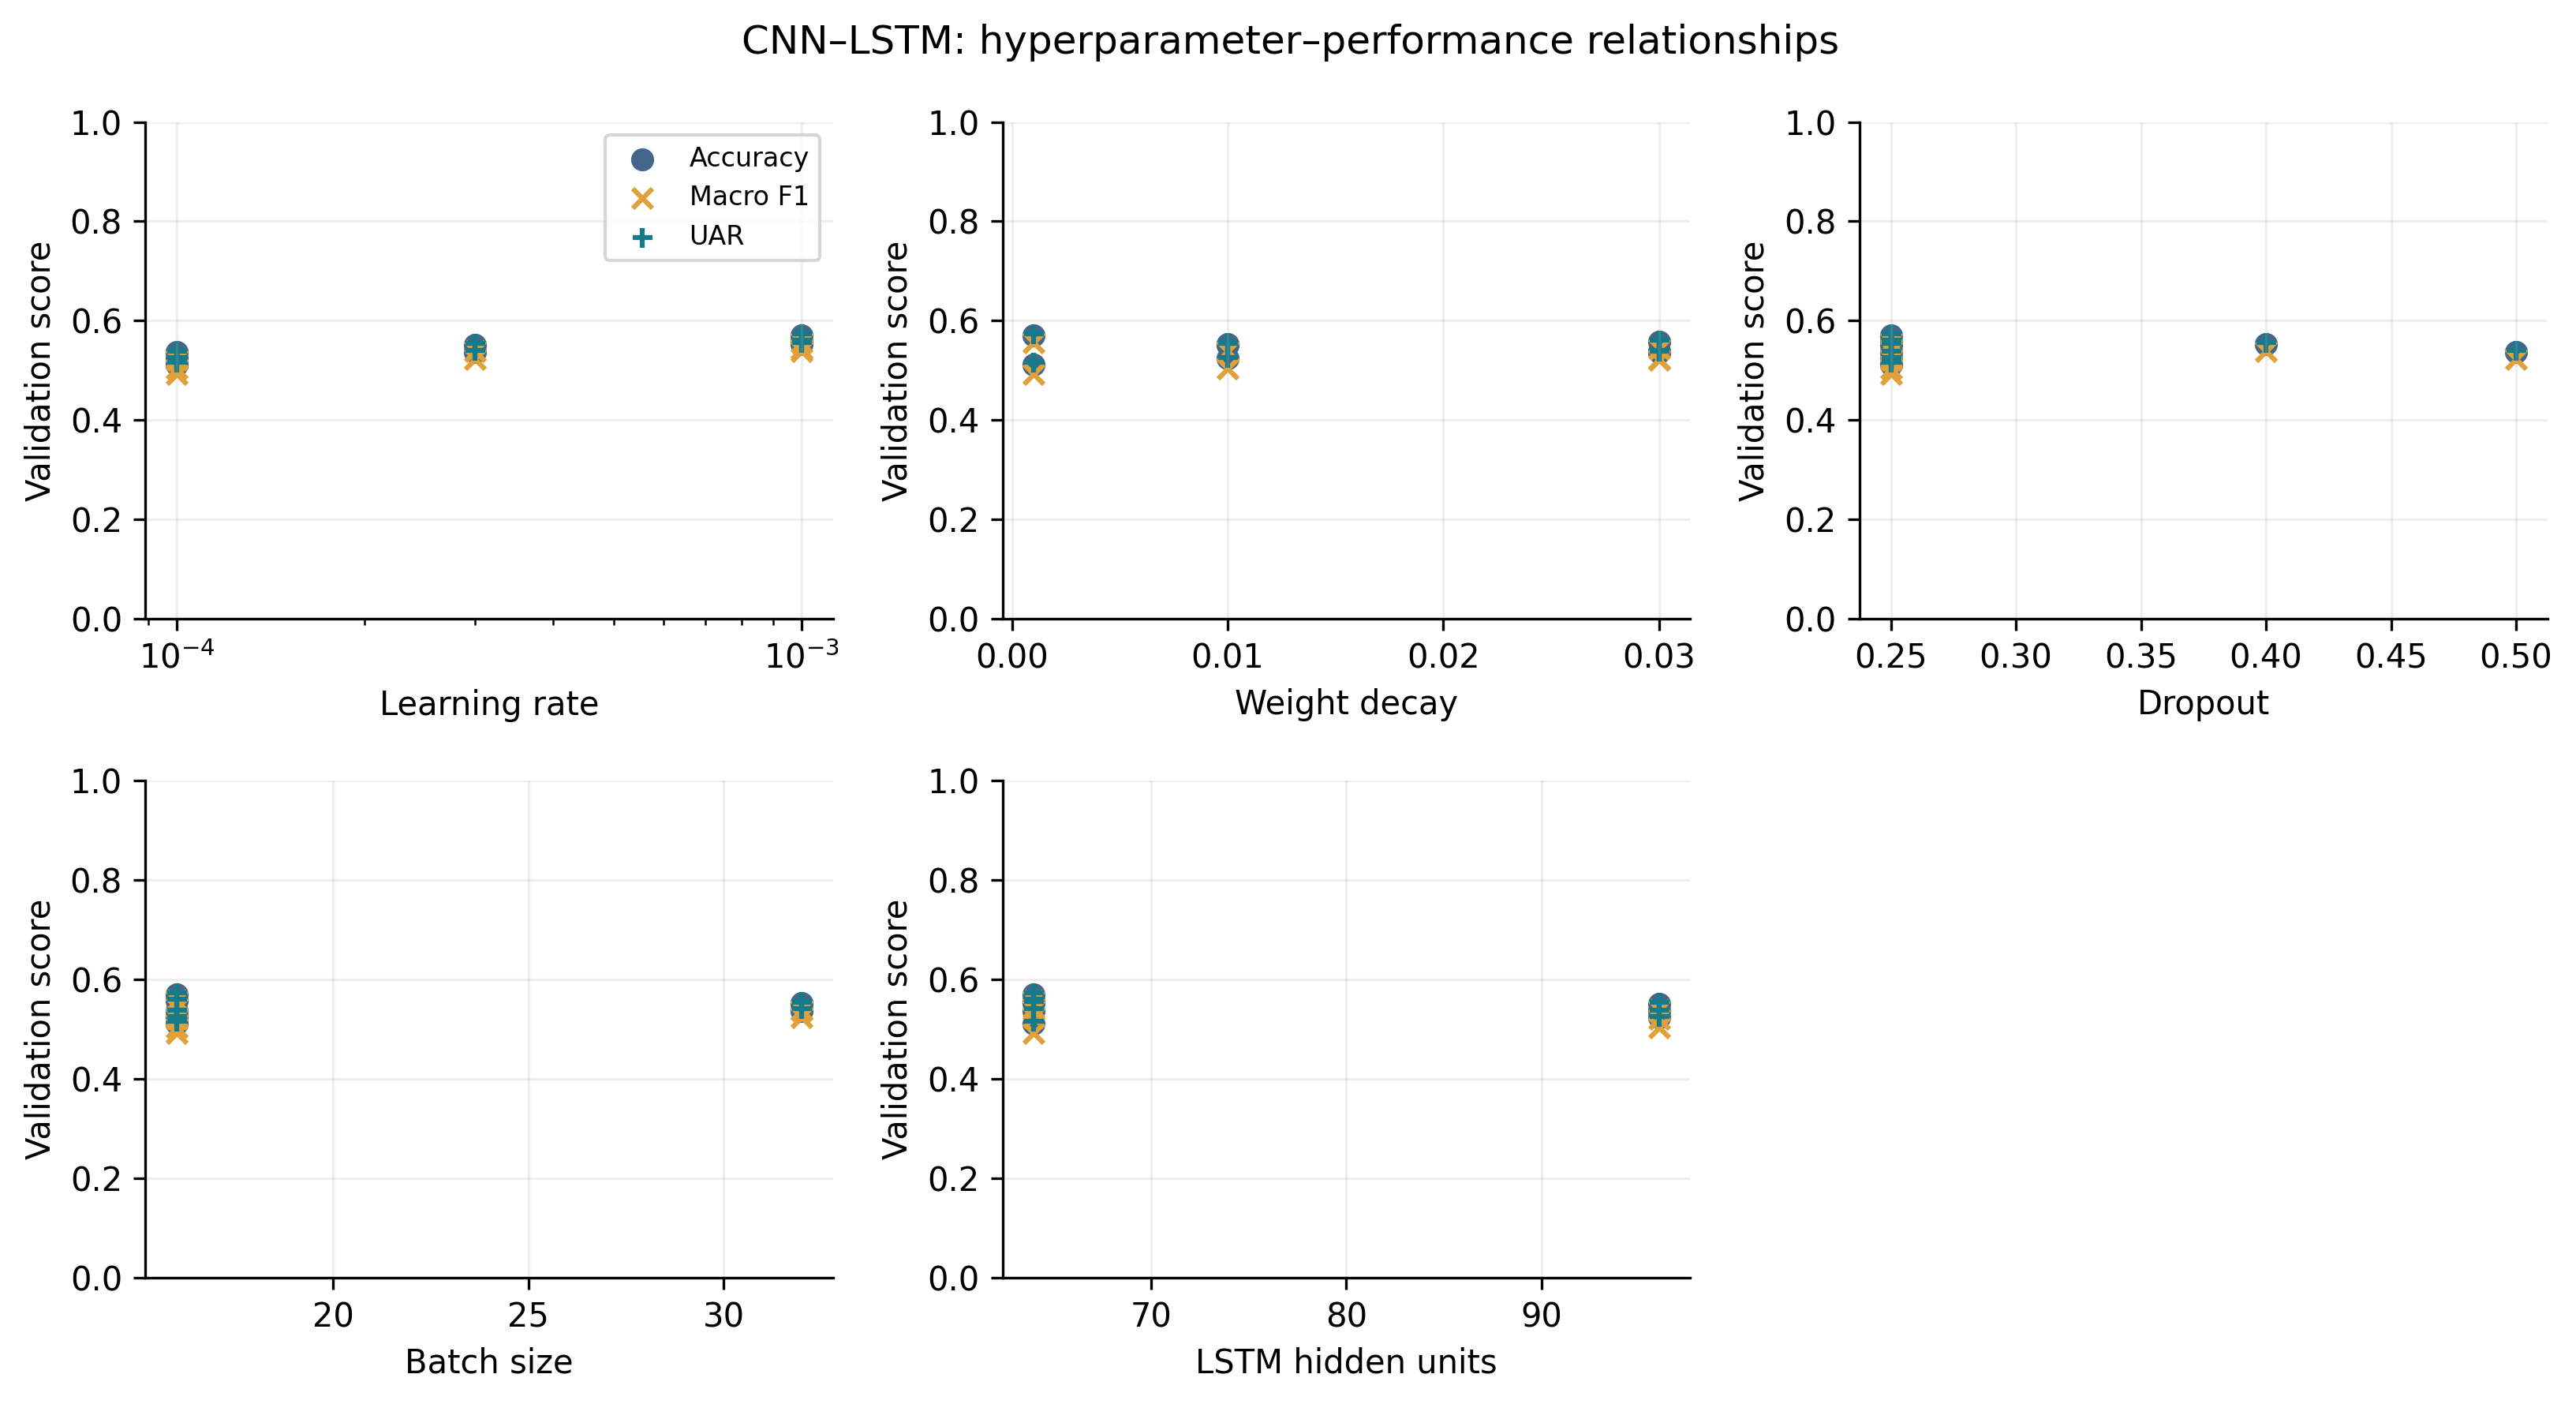

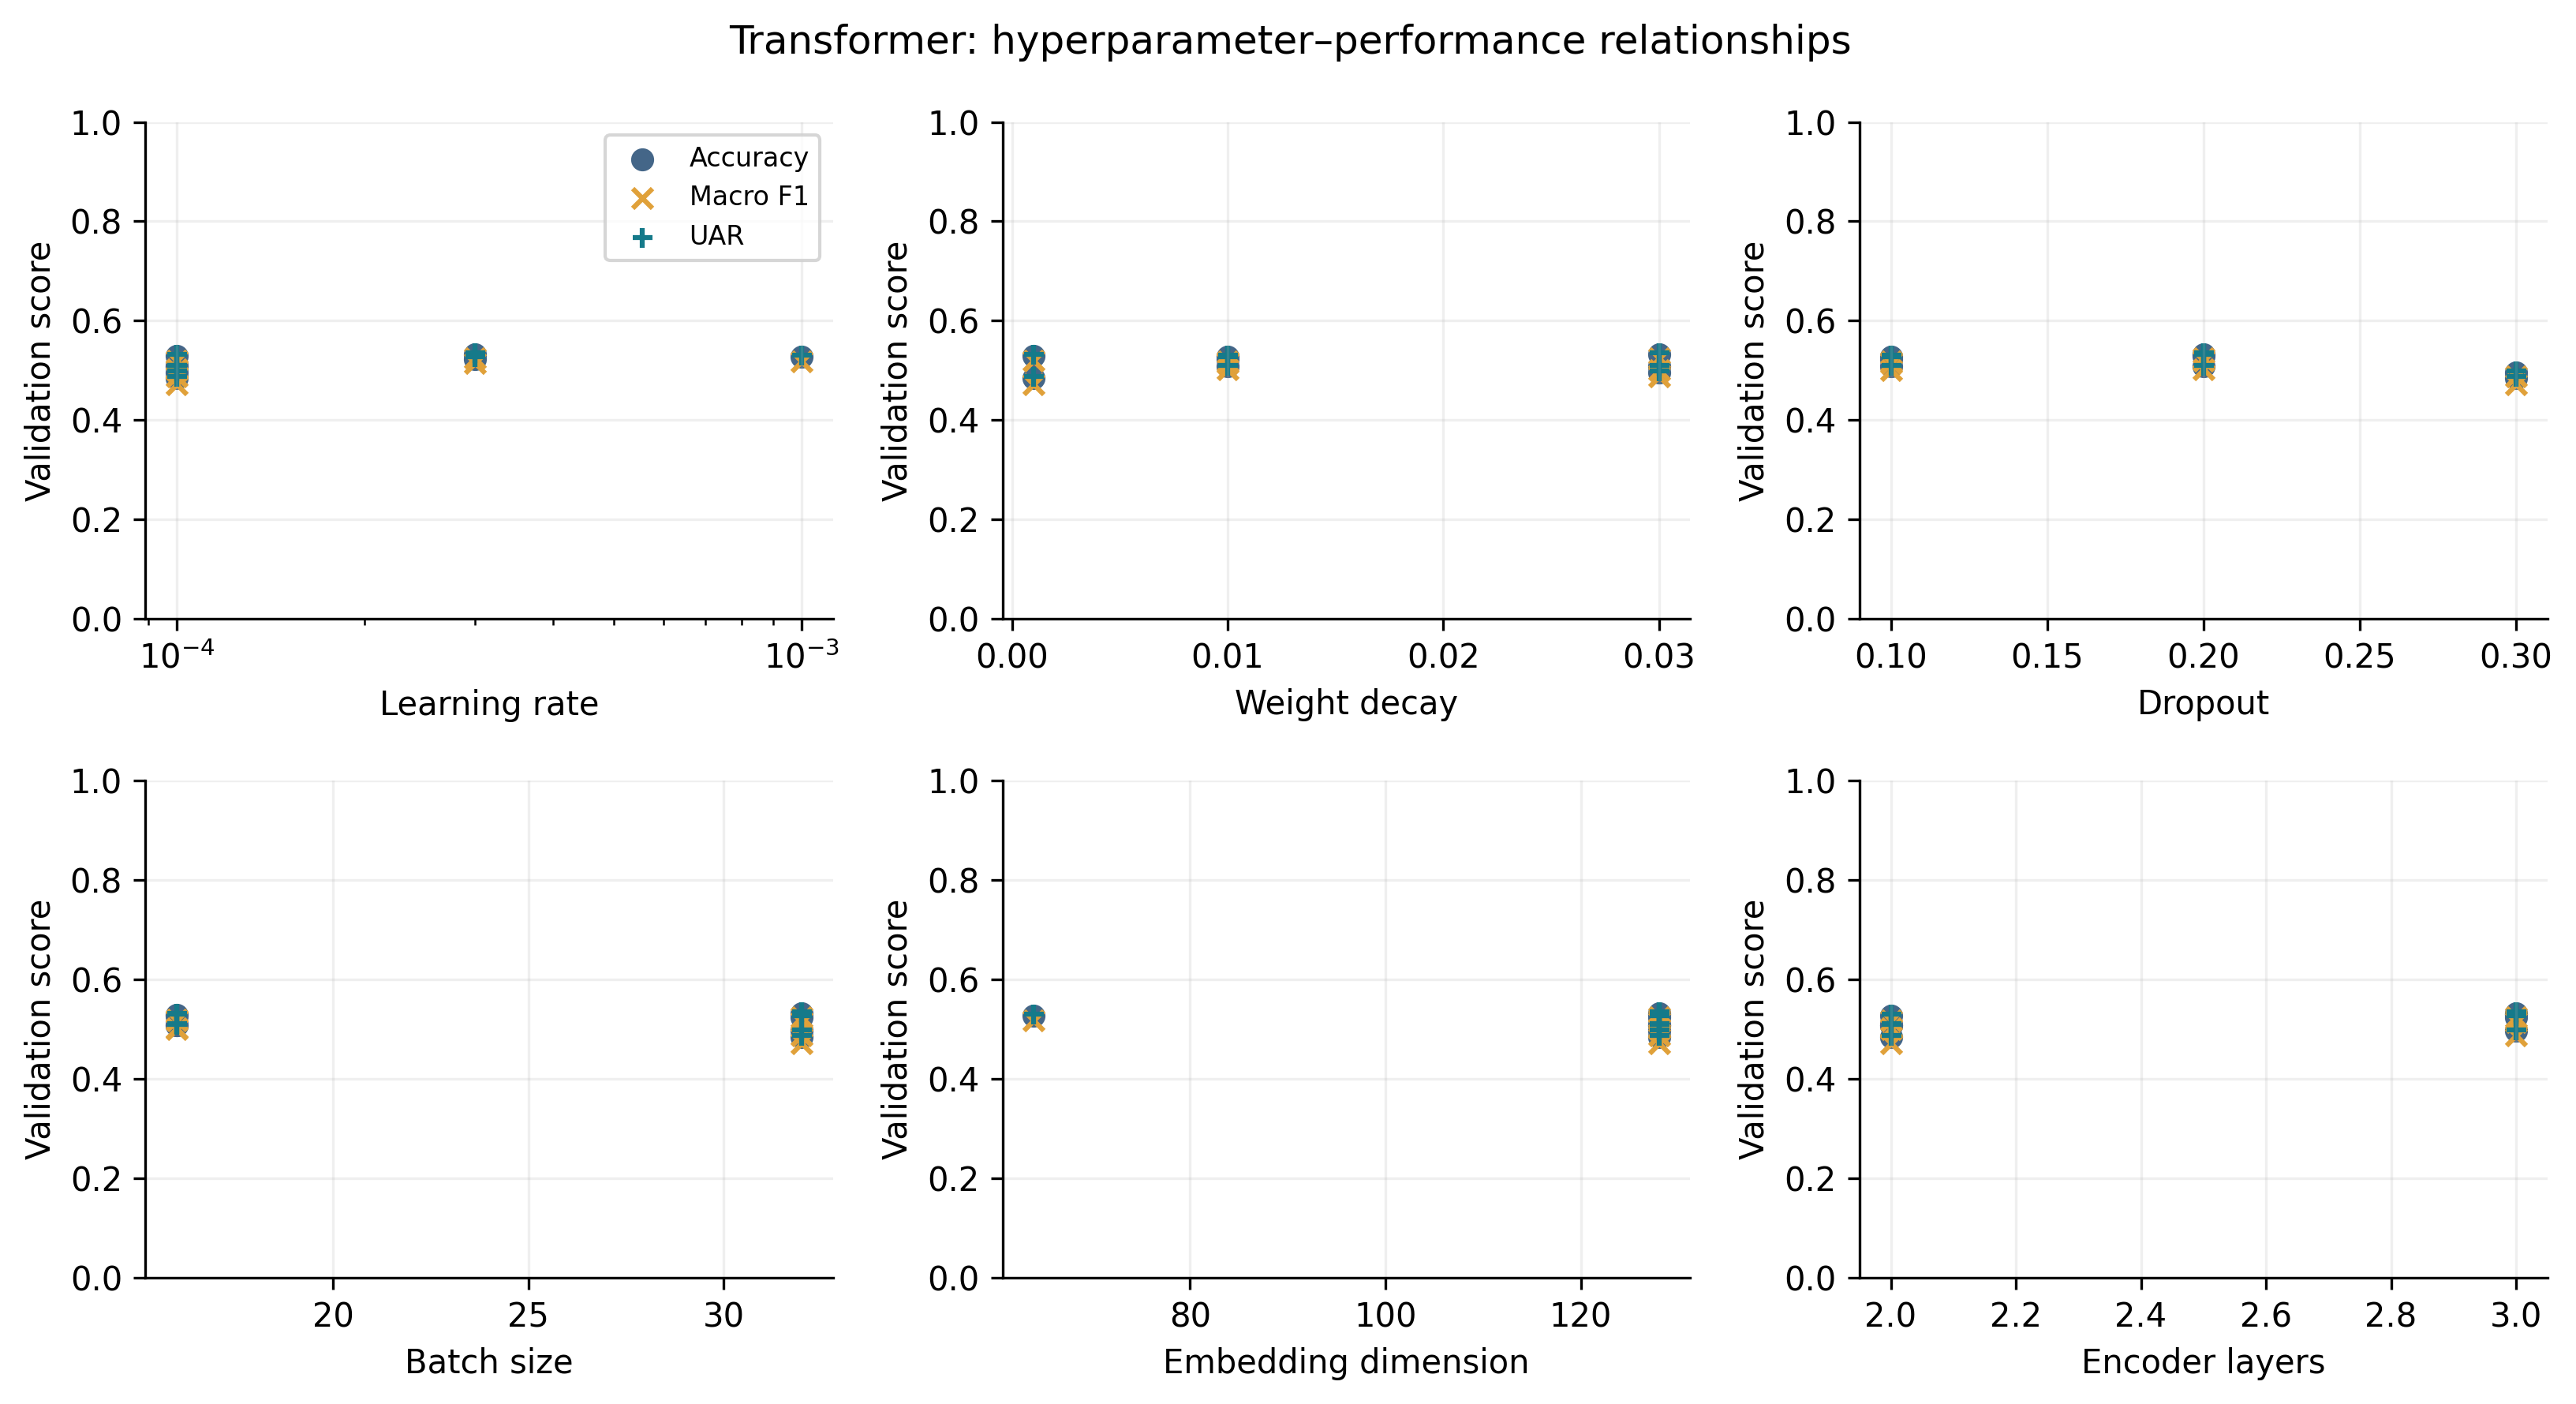

In [64]:
hpo_results = run_hpo(experiment, MAX_NEW_TRIALS)
trials = export_trials(experiment)
best_hpo = hpo_figures(experiment, trials)
display(trials[trials.stage == 'hpo'][['trial', 'lr', 'weight_decay', 'dropout',
    'batch_size', 'best_epoch', 'accuracy', 'macro_f1', 'uar', 'training_seconds']].round(4))
display(best_hpo[['architecture', 'trial', 'lr', 'weight_decay', 'dropout', 'batch_size', 'uar']].round(4))
for architecture in ['cnn_lstm', 'transformer']:
    path = experiment.root / 'summary' / f'{architecture}_hpo.png'
    if path.exists():
        display(Image(filename=str(path)))


## 7. Progressive feature selection
A feature is one mel band retained across every valid frame: **40 → 20 → 10 → 5 → 2 → 1**. We adapt correlation-ranked reduction to a categorical target using speaker-centered, equally speaker-weighted eta squared, averaged across each band's utterance mean and standard deviation. Numeric emotion IDs are not treated as continuous targets.

Univariate scores keep their order after deletion, so nested top-ranked subsets implement the template's halving procedure. Three group folds balance speaker variation against 36 neural fits. Ranking, normalization and class weights are fitted separately within each training fold. Both networks use baseline parameters and eight fixed epochs, preventing assessment feedback into scheduling or HPO. Mean CV UAR selects the feature count; ties favor fewer bands. Fold SD describes split variation, not a confidence interval.

In [65]:
def band_association(bank, rows):
    """Nominal-class effect size, equal total weight per training speaker.

    Each band is represented by utterance mean and SD. Speaker centering removes
    constant speaker offsets; this is ranking only, not model preprocessing.
    """
    if set(rows.split) != {'train'}:
        raise ValueError('Rankings require original training speakers only')
    desc = np.stack([np.stack([bank.get(i).mean(1), bank.get(i).std(1)], axis=1) for i in rows.idx]).astype(np.float64)
    weights = np.zeros(len(rows))
    speakers = rows.speaker.to_numpy()
    for s in np.unique(speakers):
        mask = speakers == s
        desc[mask] -= desc[mask].mean(0)
        weights[mask] = 1 / mask.sum()
    weights /= weights.sum()
    center = np.sum(desc * weights[:, None, None], axis=0)
    total = np.sum((desc - center) ** 2 * weights[:, None, None], axis=0)
    between = np.zeros_like(total)
    for label in np.unique(rows.class_id):
        mask = rows.class_id.to_numpy() == label
        w = weights[mask]
        mass = w.sum()
        group = np.sum(desc[mask] * w[:, None, None], axis=0) / mass
        between += mass * (group - center) ** 2
    eta = np.divide(between, total, out=np.zeros_like(total), where=total > 1e-12).clip(0, 1)
    scores = eta.mean(1)
    order = np.lexsort((np.arange(40), -scores))
    return dict(order=order.tolist(), score=scores.tolist(), mean_eta2=eta[:,
        0].tolist(), sd_eta2=eta[:, 1].tolist(), training_ids=rows.idx.astype(int).tolist(),
        training_speakers=sorted(set(rows.speaker)))


In [66]:
def feature_statistics(feature_bank, training_rows, output_dir, scope):
    ranking = band_association(feature_bank, training_rows)
    import librosa
    centers = librosa.mel_frequencies(n_mels=42, fmin=20, fmax=7600)[1:-1]
    table = pd.DataFrame(dict(band=range(40), center_hz=centers, mean_eta_squared=ranking['mean_eta2'],
        sd_eta_squared=ranking['sd_eta2'], score=ranking['score']))
    table.assign(evidence_scope=scope).to_csv(Path(output_dir) / 'feature_ranking.csv', index=False)
    means = np.stack([feature_bank.get(index).mean(axis=1) for index in training_rows.idx])
    deviations = np.stack([feature_bank.get(index).std(axis=1) for index in training_rows.idx])
    descriptors = pd.DataFrame(np.concatenate([means, deviations], axis=1),
        columns=[f'mel_{band:02d}_{kind}' for kind in ['mean', 'sd'] for band in range(40)])
    descriptors.describe().T.rename(columns={'50%': 'median'})[['count', 'mean',
        'median', 'std', 'min', 'max']].to_csv(Path(output_dir) / 'training_feature_statistics.csv')
    correlation = pd.DataFrame(means).corr()
    correlation.to_csv(Path(output_dir) / 'training_band_correlations.csv')
    plt = plotting()
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].bar(table.band, table.score, color='#157a8a')
    axes[0].set(xlabel='Mel band', ylabel='Speaker-weighted eta squared',
        title='Training feature–emotion association')
    image = axes[1].imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
    axes[1].set(xlabel='Mel band', ylabel='Mel band', title='Training-band mean correlations')
    figure.colorbar(image, ax=axes[1], label='Pearson r')
    save_figure(figure, Path(output_dir) / 'feature_analysis.png', scope)
    return (table.sort_values('score', ascending=False), ranking)


In [67]:
def run_feature_cv(experiment, max_new_trials=None):
    train = experiment.rows[experiment.rows.split == 'train'].reset_index(drop=True)
    splitter = GroupKFold(n_splits=experiment.protocol['cv_folds'], shuffle=True,
        random_state=experiment.protocol['search_seed'])
    results, new = ([], 0)
    for fold, (a, b) in enumerate(splitter.split(train, groups=train.speaker)):
        fit, assess = (train.iloc[a], train.iloc[b])
        ranking = band_association(experiment.bank, fit)
        immutable_json(experiment.root / f'ranking_fold_{fold}.json', dict(ranking=ranking,
            assessment_ids=assess.idx.astype(int).tolist()))
        for arch in ['cnn_lstm', 'transformer']:
            for size in experiment.protocol['feature_sizes']:
                name = f'feature_{arch}_k{size:02d}_fold{fold}'
                done = (experiment.root / name / 'result.json').exists()
                if not done and max_new_trials is not None and (new >= max_new_trials):
                    continue
                results.append(train_trial(experiment, name, default_config(arch,
                    experiment.mode), fit, assess, ranking['order'][:size], experiment.protocol['cv_epochs'],
                    selection='last'))
                new += not done
    return results


In [68]:
def feature_comparison(experiment, trials):
    selected = trials[trials.stage == 'feature']
    summary = selected.groupby(['architecture', 'features']).agg(folds=('uar',
        'count'), accuracy_mean=('accuracy', 'mean'), accuracy_sd=('accuracy', 'std'),
        macro_f1_mean=('macro_f1', 'mean'), macro_f1_sd=('macro_f1', 'std'), uar_mean=('uar',
        'mean'), uar_sd=('uar', 'std')).reset_index()
    summary['complete'] = summary.folds == experiment.protocol['cv_folds']
    summary['scope'] = experiment.scope
    summary.to_csv(experiment.root / 'summary/feature_comparison.csv', index=False)
    plt = plotting()
    for architecture in ['cnn_lstm', 'transformer']:
        complete = summary[(summary.architecture == architecture) & summary.complete]
        if complete.empty:
            continue
        figure, axis = plt.subplots(figsize=(7, 4))
        for metric, label in [('accuracy', 'Accuracy'), ('macro_f1', 'Macro F1'), ('uar', 'UAR')]:
            axis.errorbar(complete.features, complete[metric + '_mean'], yerr=complete[metric + '_sd'],
                marker='o', capsize=3, label=label)
        model_title = 'CNN–LSTM' if architecture == 'cnn_lstm' else 'Transformer'
        axis.set(xlabel='Retained mel bands', ylabel='Training-CV mean ± fold SD',
            ylim=(0, 1), title=f'{model_title}: feature reduction', xticks=experiment.protocol['feature_sizes'])
        axis.invert_xaxis()
        axis.legend()
        axis.grid(alpha=0.2)
        save_figure(figure, experiment.root / 'summary' / f'{architecture}_features.png', experiment.scope)
    return summary


,band,center_hz,mean_eta_squared,sd_eta_squared,score
28,28,3122.8422,0.5061,0.5388,0.5225
27,27,2899.7557,0.5064,0.5380,0.5222
26,26,2692.6058,0.5047,0.5330,0.5189
29,29,3363.0914,0.5029,0.5307,0.5168
25,25,2500.2541,0.5009,0.5254,0.5131
30,30,3621.8236,0.4987,0.5187,0.5087
24,24,2321.6435,0.4916,0.5094,0.5005
31,31,3900.4609,0.4910,0.5018,0.4964
23,23,2155.7922,0.4826,0.4904,0.4865
32,32,4200.5345,0.4782,0.4743,0.4762


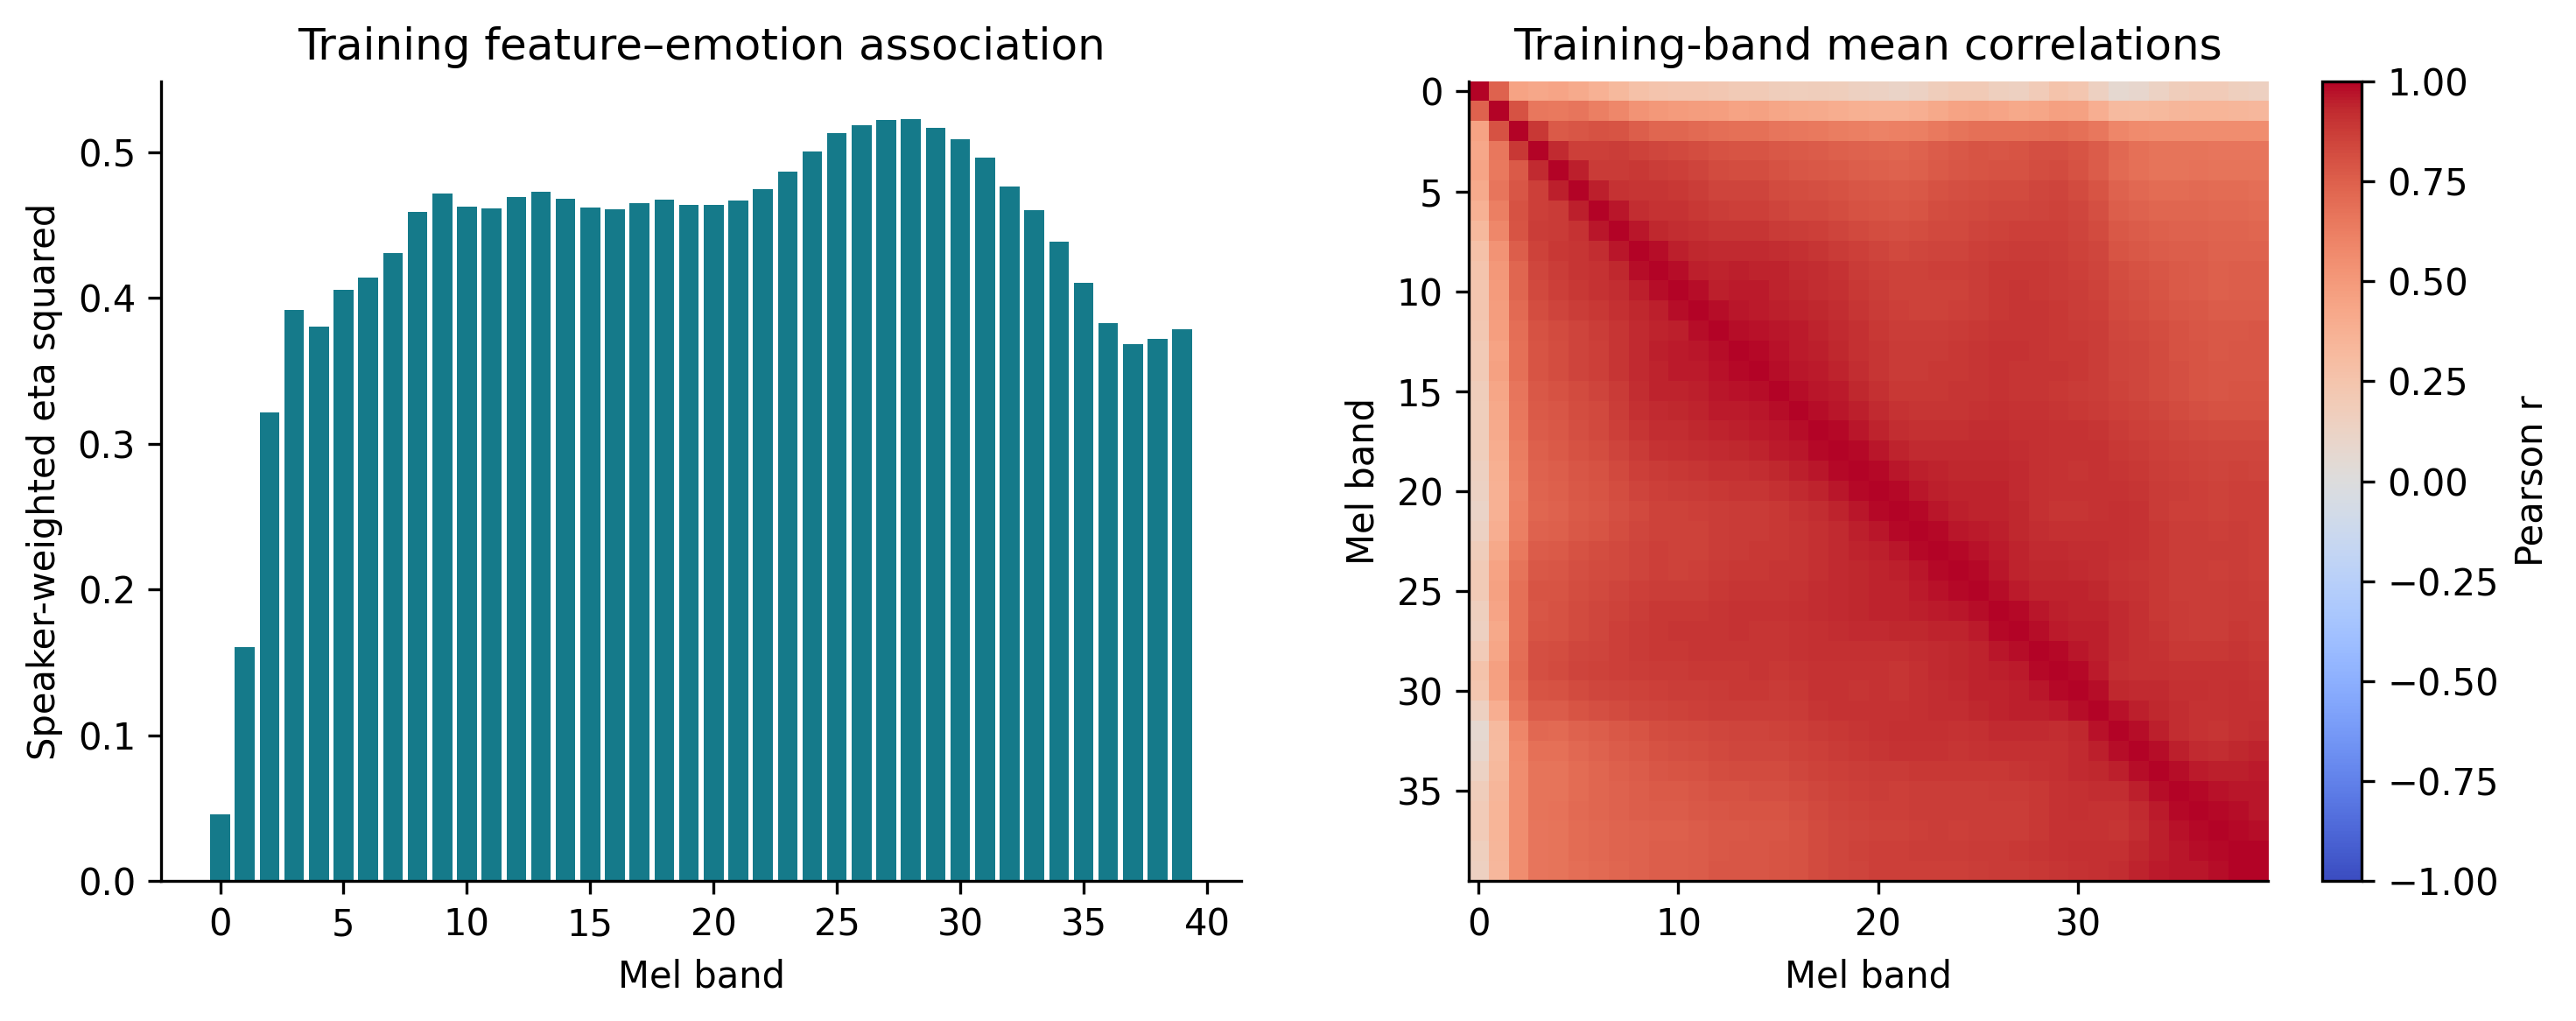

feature_cnn_lstm_k40_fold0 epoch 1/8 validation UAR: None
feature_cnn_lstm_k40_fold0 epoch 5/8 validation UAR: None
feature_cnn_lstm_k40_fold0 epoch 8/8 validation UAR: None
feature_cnn_lstm_k20_fold0 epoch 1/8 validation UAR: None
feature_cnn_lstm_k20_fold0 epoch 5/8 validation UAR: None
feature_cnn_lstm_k20_fold0 epoch 8/8 validation UAR: None
feature_cnn_lstm_k10_fold0 epoch 1/8 validation UAR: None
feature_cnn_lstm_k10_fold0 epoch 5/8 validation UAR: None
feature_cnn_lstm_k10_fold0 epoch 8/8 validation UAR: None
feature_cnn_lstm_k05_fold0 epoch 1/8 validation UAR: None
feature_cnn_lstm_k05_fold0 epoch 5/8 validation UAR: None
feature_cnn_lstm_k05_fold0 epoch 8/8 validation UAR: None
feature_cnn_lstm_k02_fold0 epoch 1/8 validation UAR: None
feature_cnn_lstm_k02_fold0 epoch 5/8 validation UAR: None
feature_cnn_lstm_k02_fold0 epoch 8/8 validation UAR: None
feature_cnn_lstm_k01_fold0 epoch 1/8 validation UAR: None
feature_cnn_lstm_k01_fold0 epoch 5/8 validation UAR: None
feature_cnn_ls

,architecture,features,folds,accuracy_mean,accuracy_sd,macro_f1_mean,macro_f1_sd,uar_mean,uar_sd,complete,scope
0,cnn_lstm,1,3,0.3973,0.0079,0.3495,0.0140,0.4020,0.0083,True,CREMA-D
1,cnn_lstm,2,3,0.4025,0.0194,0.3526,0.0295,0.4075,0.0197,True,CREMA-D
2,cnn_lstm,5,3,0.4082,0.0098,0.3588,0.0136,0.4128,0.0125,True,CREMA-D
3,cnn_lstm,10,3,0.4223,0.0095,0.3808,0.0170,0.4264,0.0099,True,CREMA-D
4,cnn_lstm,20,3,0.4501,0.0173,0.4166,0.0192,0.4543,0.0184,True,CREMA-D
5,cnn_lstm,40,3,0.5132,0.0154,0.5001,0.0188,0.5164,0.0162,True,CREMA-D
6,transformer,1,3,0.3752,0.0251,0.3159,0.0265,0.3791,0.0237,True,CREMA-D
7,transformer,2,3,0.3711,0.0183,0.3038,0.0209,0.3757,0.0192,True,CREMA-D
8,transformer,5,3,0.4010,0.0181,0.3477,0.0165,0.4059,0.0172,True,CREMA-D
9,transformer,10,3,0.4241,0.0231,0.3927,0.0170,0.4267,0.0254,True,CREMA-D


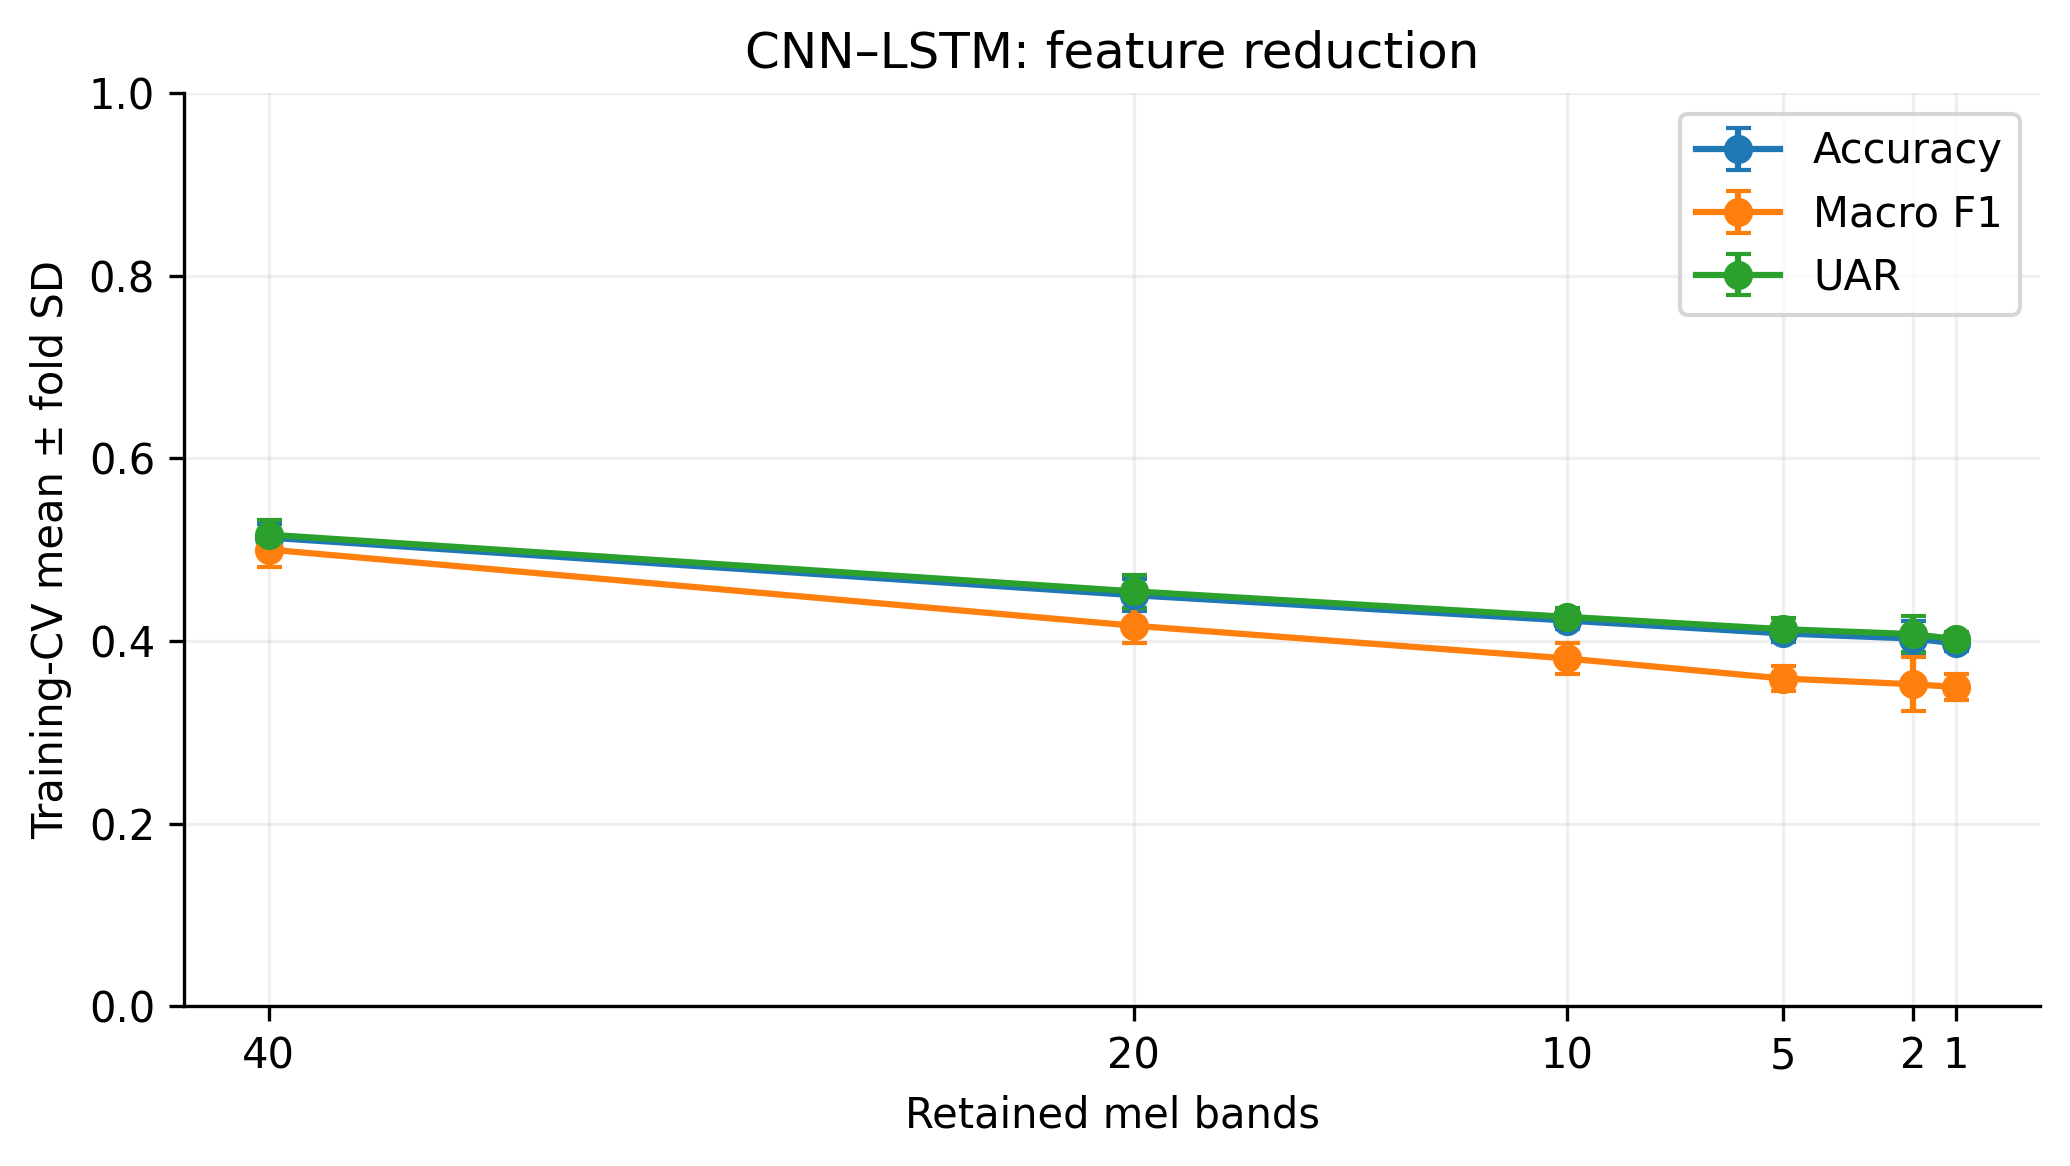

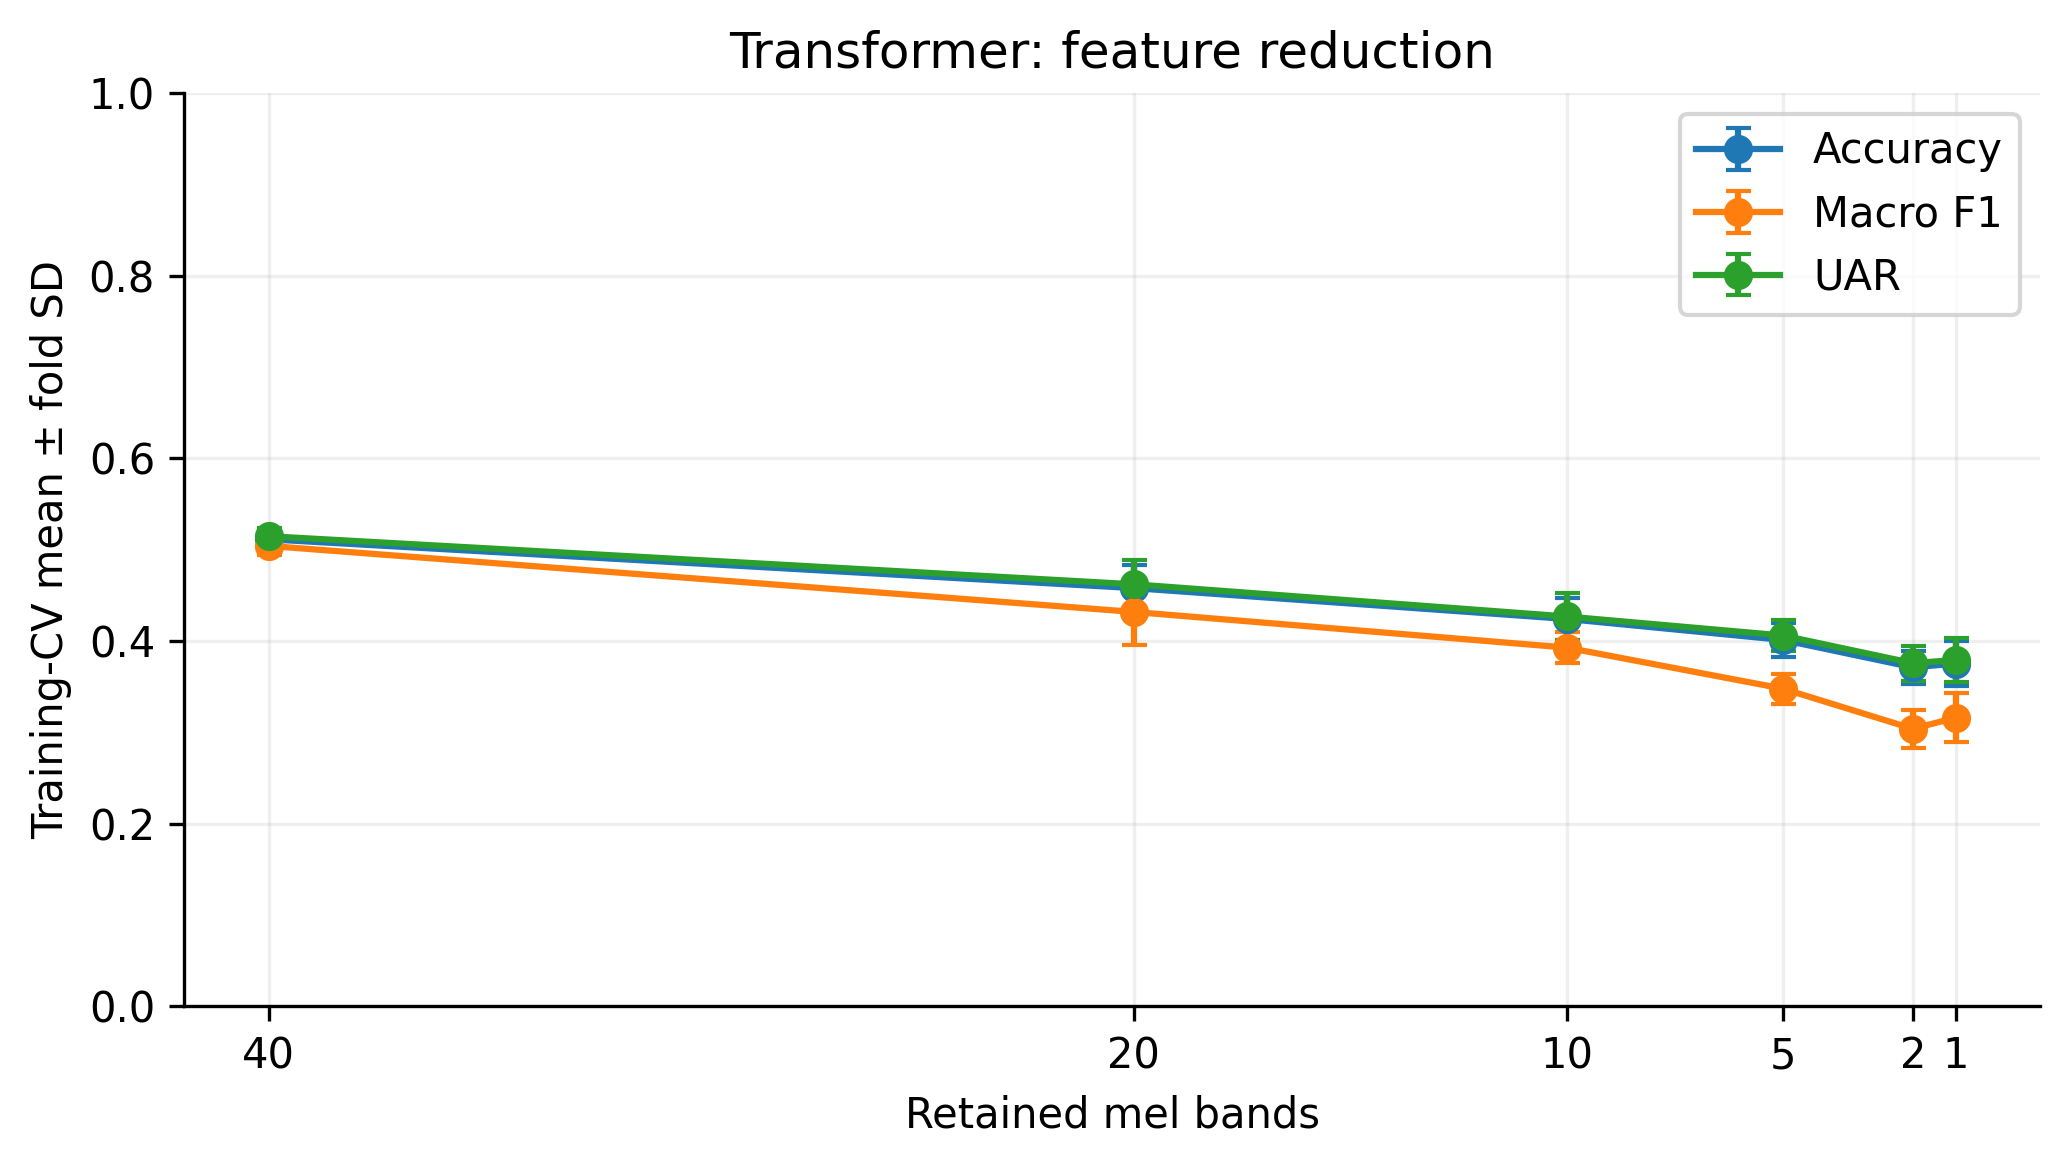

In [69]:
ranking_table, training_ranking = feature_statistics(feature_bank, training_rows, AUDIT_DIR, SCOPE)
display(ranking_table.round(4))
display(Image(filename=str(AUDIT_DIR / 'feature_analysis.png')))
feature_results = run_feature_cv(experiment, MAX_NEW_TRIALS)
trials = export_trials(experiment)
feature_summary = feature_comparison(experiment, trials)
display(feature_summary.round(4))
for architecture in ['cnn_lstm', 'transformer']:
    path = experiment.root / 'summary' / f'{architecture}_features.png'
    if path.exists():
        display(Image(filename=str(path)))


## 8. Final model training and selection
After all HPO and CV trials complete, each architecture is initialized anew with its selected HPO settings. We train all-band and CV-selected-band candidates for up to 25 epochs, then select by validation UAR (ties favor fewer bands). The chosen weights, normalizers and configurations are frozen together.

The all-band candidate checks whether the feature count selected under baseline settings transfers to the chosen HPO configuration. All candidates start from new weights; only training and validation data enter selection.

In [70]:
def train_final_candidates(experiment):
    destination = experiment.root / 'frozen_selection.json'
    if destination.exists():
        frozen = json.loads(destination.read_text())
        verify_frozen_selection(experiment, frozen)
        return frozen
    train, val = (experiment.rows[experiment.rows.split == 'train'], experiment.rows[experiment.rows.split == 'val'])
    ranking = band_association(experiment.bank, train)
    immutable_json(experiment.root / 'ranking_full_train.json', ranking)
    decisions, evaluation_plan = ({}, {})
    for arch in ['cnn_lstm', 'transformer']:
        required = ['baseline_' + arch] + [f'hpo_{arch}_{i:02d}' for i in range(experiment.protocol['hpo_trials_per_model'])]
        required += [f'feature_{arch}_k{k:02d}_fold{f}' for k in experiment.protocol['feature_sizes'] for f in range(experiment.protocol['cv_folds'])]
        if any((not (experiment.root / n / 'result.json').exists() for n in required)):
            raise ValueError('Finish both baselines, all HPO and all feature CV before final training')
        for n in required:
            load_completed_trial(experiment, n)
    for arch in ['cnn_lstm', 'transformer']:
        hpo = [load_completed_trial(experiment, f'hpo_{arch}_{i:02d}') for i in range(experiment.protocol['hpo_trials_per_model'])]
        winner = max(hpo, key=lambda r: (r['assessment']['uar'], -int(r['name'].split('_')[-1])))
        cv = []
        for size in experiment.protocol['feature_sizes']:
            fold_scores = []
            for fold in range(experiment.protocol['cv_folds']):
                trial = load_completed_trial(experiment, f'feature_{arch}_k{size:02d}_fold{fold}')
                fold_scores.append(trial['assessment']['uar'])
            cv.append((float(np.mean(fold_scores)), size))
        cv_score, selected_size = max(cv, key=lambda pair: (pair[0], -pair[1]))
        finalists = [train_trial(experiment, f'final_{arch}_k{k:02d}', winner['config'],
            train, val, ranking['order'][:k], experiment.protocol['final_epochs'], patience=experiment.protocol['early_stopping_patience']) for k in sorted({40,
            selected_size})]
        selected = max(finalists, key=lambda r: (r['assessment']['uar'], -len(r['bands'])))
        decisions[arch] = dict(hpo_trial=winner['name'], hpo_validation=winner['assessment'],
            cv_size=selected_size, cv_mean_uar=cv_score, selected_trial=selected['name'],
            final_config=selected['config'], bands=selected['bands'], validation=selected['assessment'],
            selected_epoch=selected['selected_epoch'], reason='Highest final validation UAR; exact ties favor fewer bands')
        for role, trial in [('baseline', 'baseline_' + arch), ('final', selected['name'])]:
            r = load_completed_trial(experiment, trial)
            evaluation_plan[role + '_' + arch] = dict(trial=trial, checkpoint_sha256=r['artifacts']['best.pt'],
                normalizer_sha256=r['artifacts']['normalizer.npz'])
    frozen = dict(study=signature(experiment.identity), scope=experiment.scope,
        decisions=decisions, evaluation_plan=evaluation_plan, test_used_for_selection=False)
    immutable_json(destination, frozen)
    return frozen


In [71]:
def verify_frozen_selection(experiment, frozen):
    if frozen['study'] != signature(experiment.identity) or frozen['test_used_for_selection']:
        raise ValueError('Invalid frozen selection')
    if set(frozen['evaluation_plan']) != {f'{role}_{arch}' for role in ['baseline',
        'final'] for arch in ['cnn_lstm', 'transformer']}:
        raise ValueError('Unexpected test evaluation plan')
    for item in frozen['evaluation_plan'].values():
        r = load_completed_trial(experiment, item['trial'])
        if item['checkpoint_sha256'] != r['artifacts']['best.pt'] or item['normalizer_sha256'] != r['artifacts']['normalizer.npz']:
            raise ValueError('Frozen model artifacts changed')


In [72]:
def selected_model_table(experiment, frozen):
    rows, pointers = ([], {})
    for architecture, selection in frozen['decisions'].items():
        rows.append(dict(**selection['final_config'], retained_bands=len(selection['bands']),
            bands=json.dumps(selection['bands']), selected_epoch=selection['selected_epoch'],
            selected_trial=selection['selected_trial'], **selection['validation']))
        pointers[architecture] = dict(checkpoint=f"{selection['selected_trial']}/best.pt",
            normalizer=f"{selection['selected_trial']}/normalizer.npz", bands=selection['bands'],
            scope=experiment.scope)
    table = pd.DataFrame(rows)
    table.to_csv(experiment.root / 'summary/selected_parameters.csv', index=False)
    write_json(experiment.root / 'summary/selected_models.json', pointers)
    return table


final_cnn_lstm_k40 epoch 1/25 validation UAR: 0.4573
final_cnn_lstm_k40 epoch 5/25 validation UAR: 0.567
final_cnn_lstm_k40 epoch 10/25 validation UAR: 0.6063
final_cnn_lstm_k40 epoch 15/25 validation UAR: 0.6178
final_cnn_lstm_k40 epoch 20/25 validation UAR: 0.6121
final_cnn_lstm_k40 epoch 21/25 validation UAR: 0.6148
final_transformer_k40 epoch 1/25 validation UAR: 0.444
final_transformer_k40 epoch 5/25 validation UAR: 0.5123
final_transformer_k40 epoch 10/25 validation UAR: 0.5149
final_transformer_k40 epoch 15/25 validation UAR: 0.5519
final_transformer_k40 epoch 20/25 validation UAR: 0.5293
final_transformer_k40 epoch 21/25 validation UAR: 0.5462


,architecture,lr,weight_decay,dropout,head_dropout,batch_size,hidden,width,layers,heads,...,selected_epoch,selected_trial,accuracy,precision_macro,recall_macro,uar,balanced_accuracy,macro_f1,weighted_f1,loss
0,cnn_lstm,0.0010,0.001,0.25,0.2,16,64,128,3,4,...,15,final_cnn_lstm_k40,0.6141,0.6134,0.6178,0.6178,0.6178,0.6080,0.6061,1.0832
1,transformer,0.0003,0.030,0.20,0.2,32,96,128,3,4,...,15,final_transformer_k40,0.5488,0.5526,0.5519,0.5519,0.5519,0.5407,0.5404,1.3335


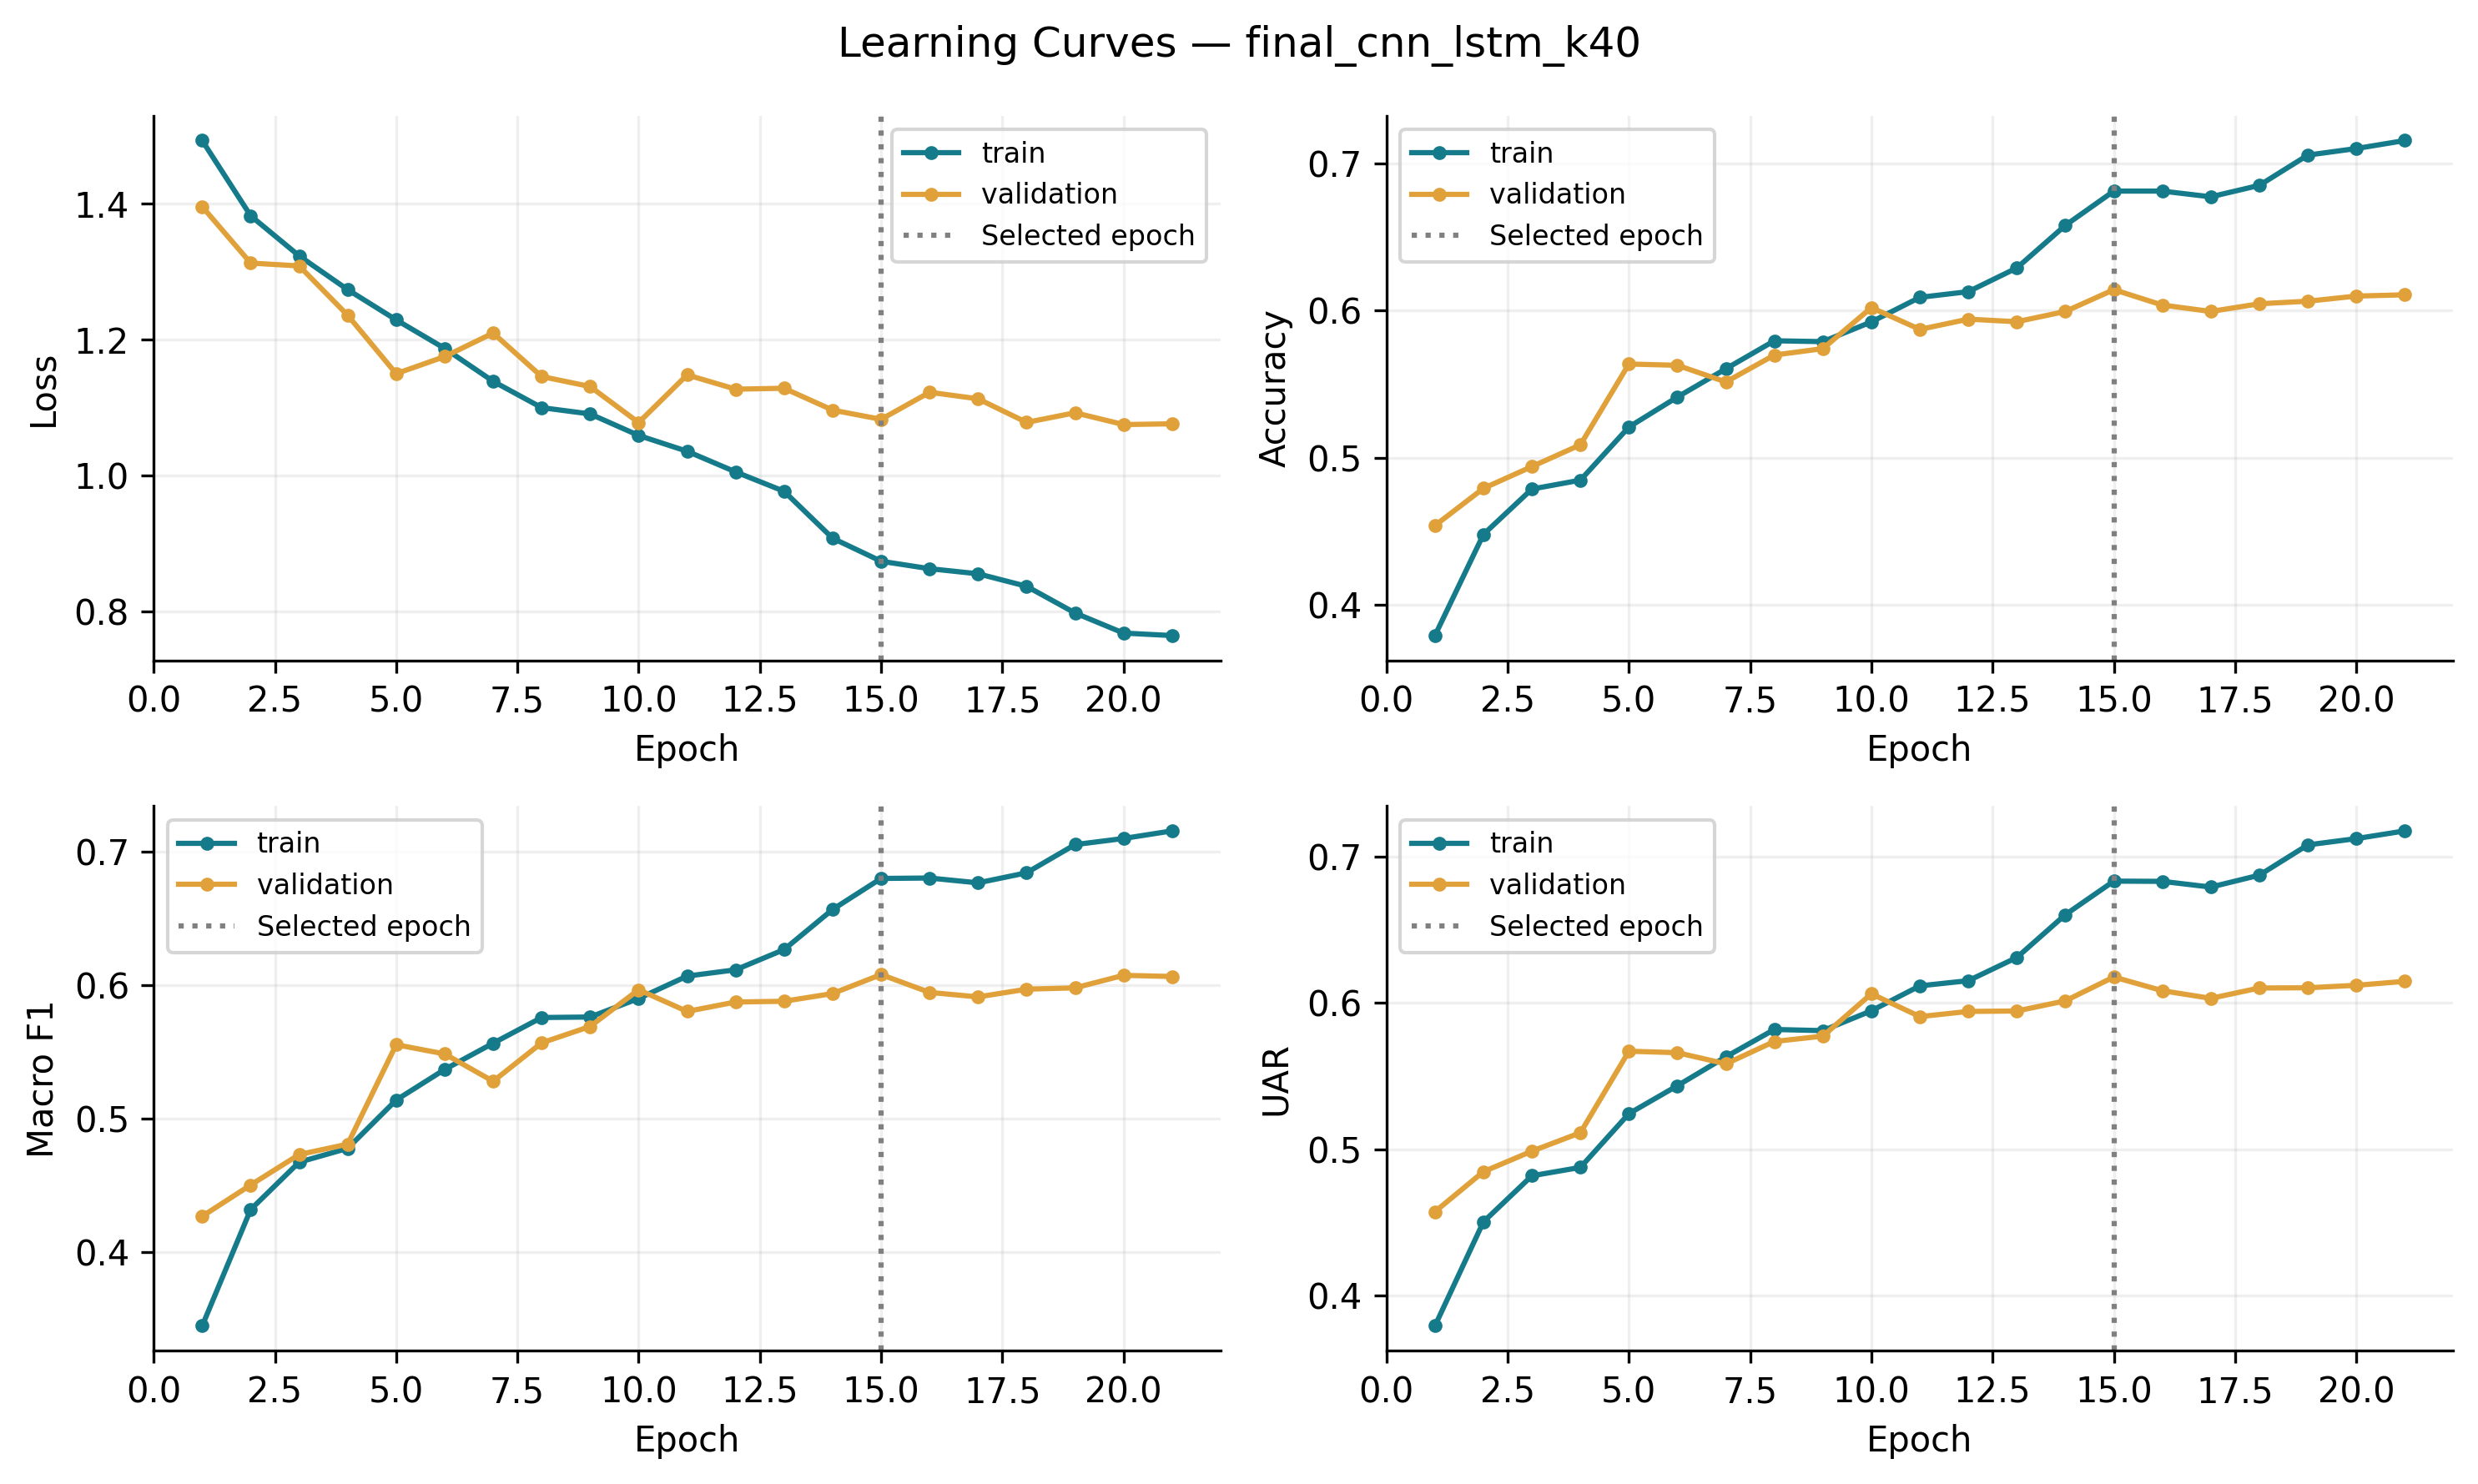

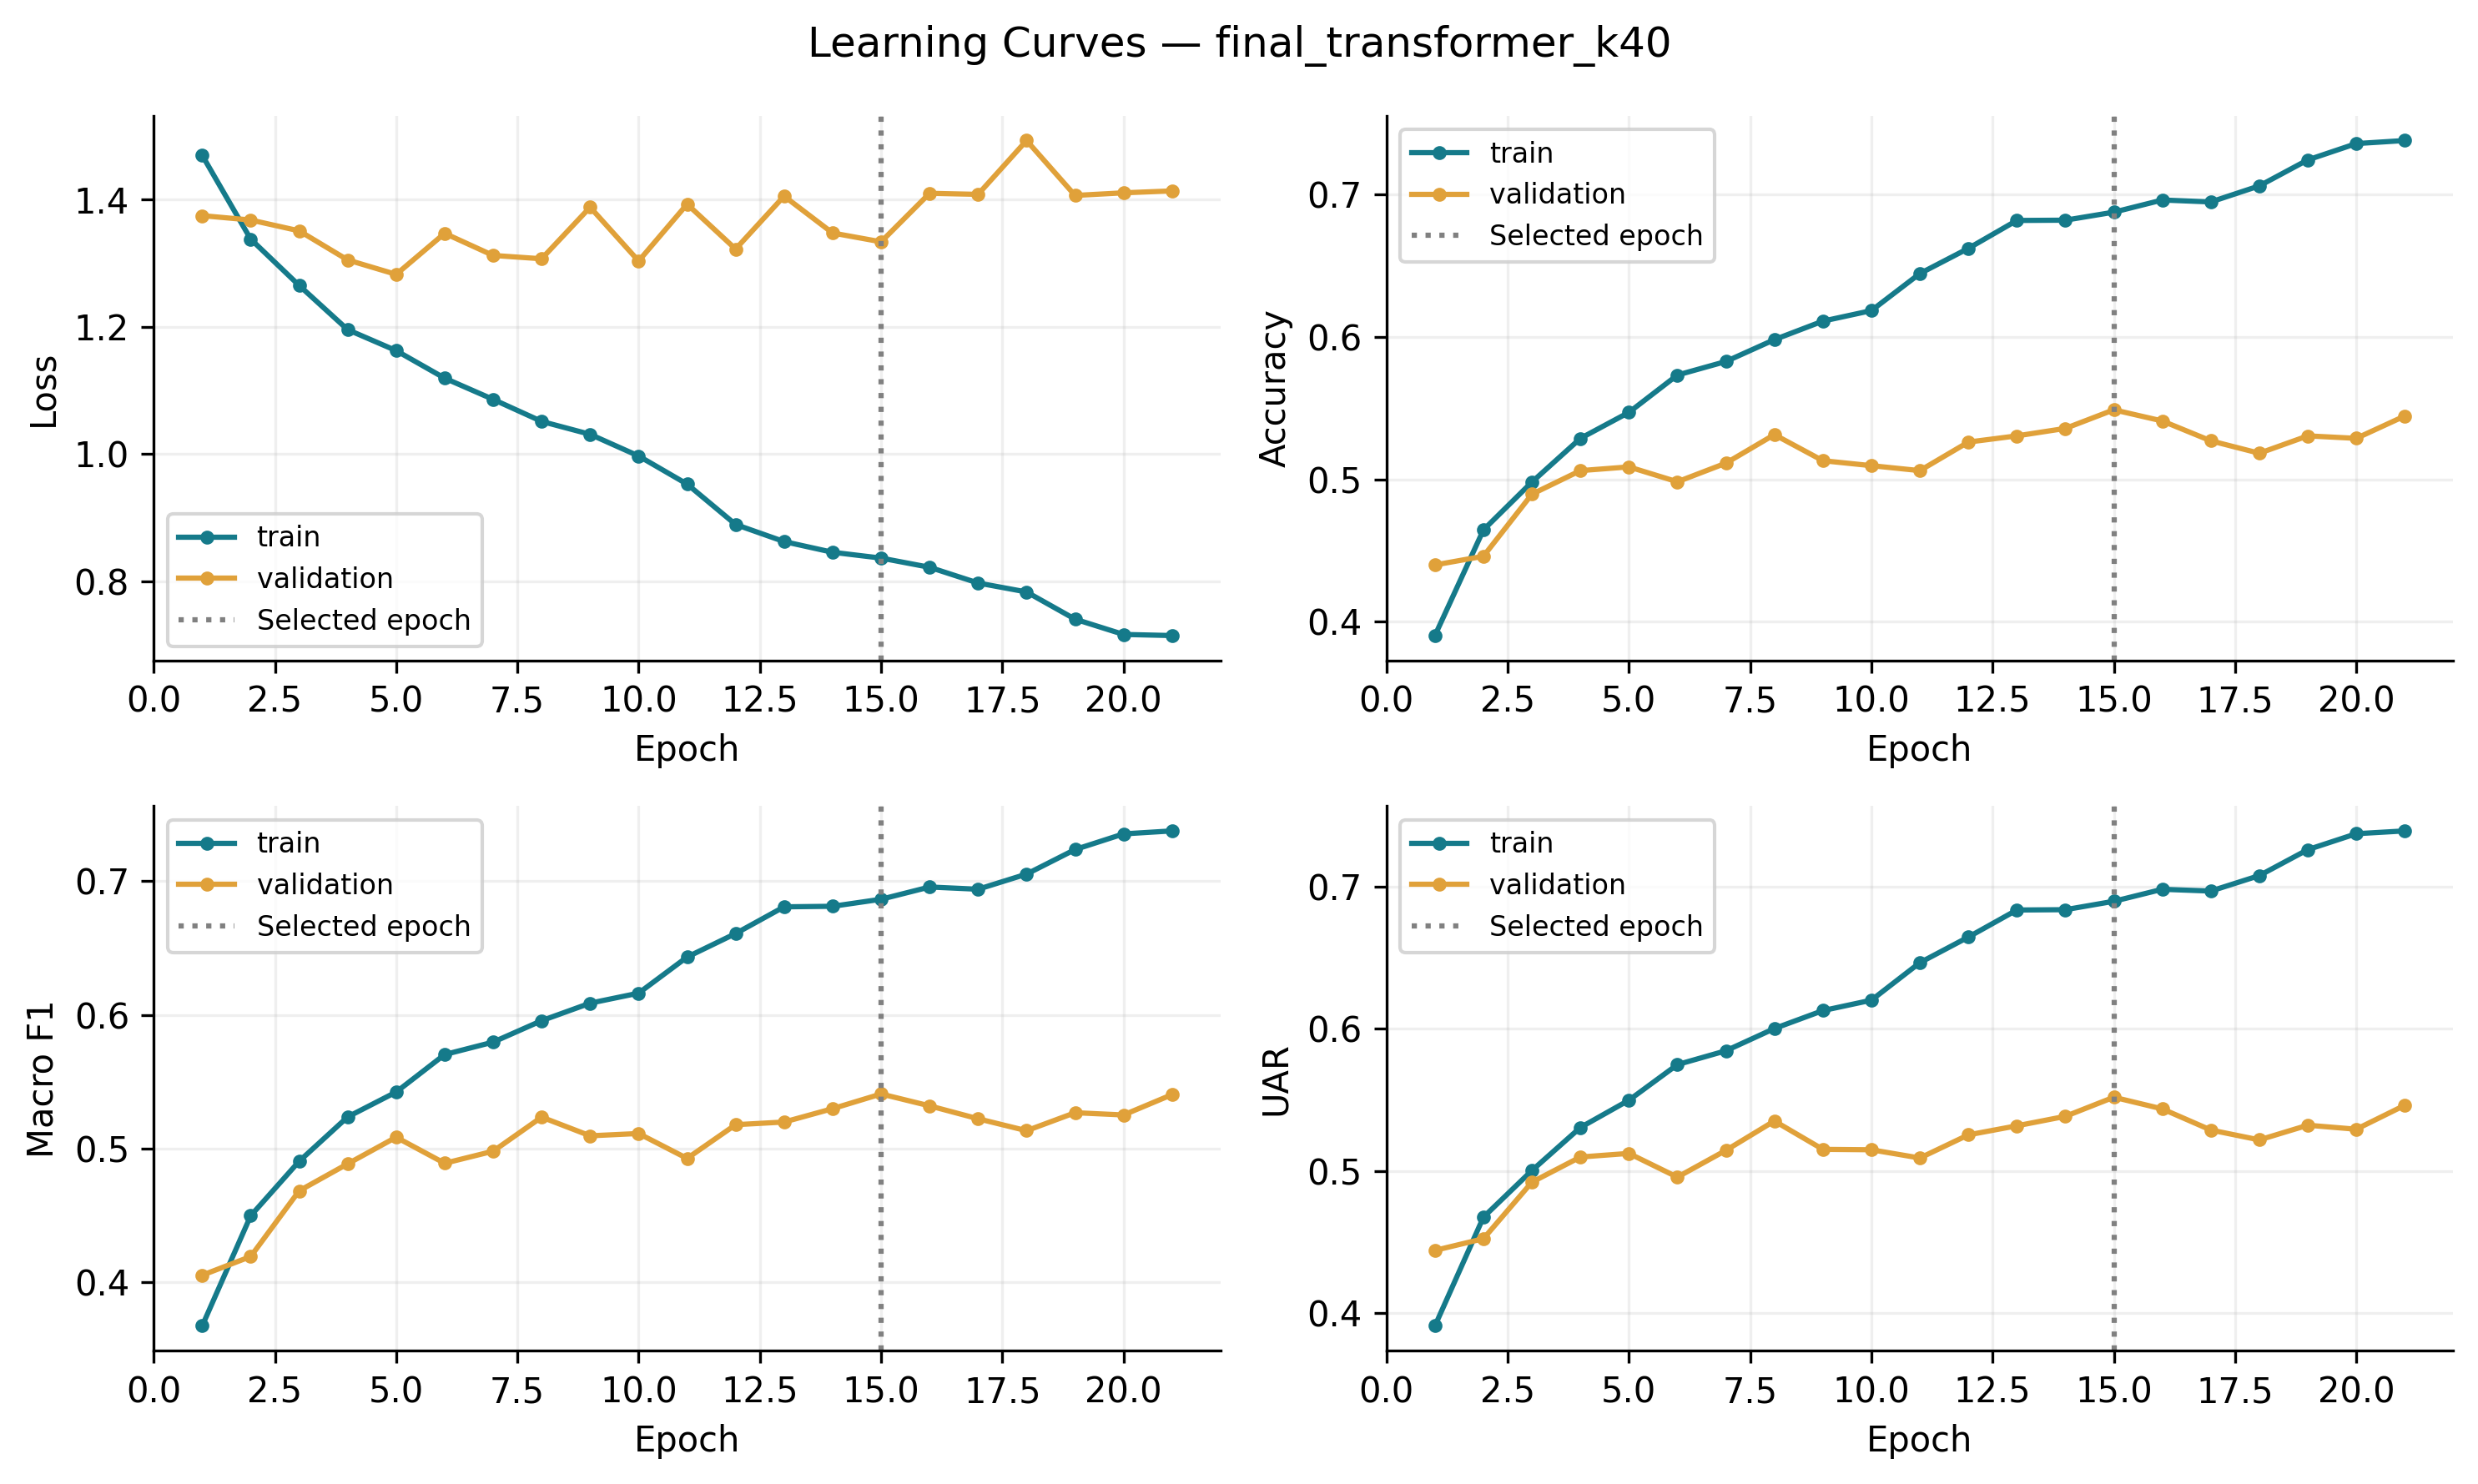

In [73]:
frozen = train_final_candidates(experiment)
trials = export_trials(experiment)
selected_parameters = selected_model_table(experiment, frozen)
display(selected_parameters.round(4))
for selection in frozen['decisions'].values():
    display(Image(filename=str(experiment.root / selection['selected_trial'] / 'learning_curves.png')))


## 9. Held-out Test evaluation
The frozen final models and the two predeclared baseline controls each receive one completed, cached Test pass. Rerunning the cell reuses verified score files. Test outcomes must not trigger another tuning cycle.

We report Accuracy, macro Precision/Recall/F1, weighted F1, UAR (balanced accuracy), per-class scores and one-vs-rest ROC/AUC. Accuracy weights recordings equally; UAR averages class recalls. Macro F1 weights classes equally, while weighted F1 uses class support. ROC/AUC measures score-based discrimination across thresholds, not calibration. Confusion matrices show counts and row-normalized proportions. All six probability scores are retained for error analysis.

In [ ]:
def evaluation_artifacts(output, rows, probabilities, provenance):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)

    scope = provenance['scope']
    y, pred = rows.class_id.to_numpy(), probabilities.argmax(1)

    metrics = measures(y, probabilities)
    cm = confusion_matrix(y, pred, labels=range(6))
    normalized = np.divide(
        cm, cm.sum(1, keepdims=True),
        out=np.zeros_like(cm, dtype=float),
        where=cm.sum(1, keepdims=True) > 0
    )

    report = classification_report(
        y, pred, labels=range(6), target_names=LABELS,
        output_dict=True, zero_division=0
    )

    pd.DataFrame(report).T.assign(evidence_scope=scope).to_csv(output / 'per_class.csv')
    pd.DataFrame(cm, index=LABELS, columns=LABELS).to_csv(output / 'confusion_counts.csv')
    pd.DataFrame(normalized, index=LABELS, columns=LABELS).to_csv(output / 'confusion_normalized.csv')

    plt = plotting()
    for values, name, title in [
        (cm, 'confusion_counts', 'Confusion counts'),
        (normalized, 'confusion_normalized', 'Row-normalized confusion')
    ]:
        fig, ax = plt.subplots(figsize=(6.5, 5.5))
        im = ax.imshow(values, cmap='Blues', vmin=0, vmax=1 if name.endswith('normalized') else None)
        fig.colorbar(im, ax=ax)

        for i in range(6):
            for j in range(6):
                ax.text(
                    j, i,
                    str(values[i, j]) if name.endswith('counts') else f'{values[i, j]:.2f}',
                    ha='center', va='center',
                    color='white' if values[i, j] > values.max() * 0.55 else '#18324a'
                )

        model_title = output.name.replace('cnn_lstm', 'CNN–LSTM').replace('transformer', 'Transformer')
        model_title = model_title.replace('baseline_', 'Baseline ').replace('final_', 'Final ')

        ax.set(
            xticks=range(6), yticks=range(6),
            xticklabels=LABELS, yticklabels=LABELS,
            xlabel='Predicted', ylabel='Actual',
            title=model_title + ' | ' + title
        )
        ax.tick_params(axis='x', rotation=30)
        save_figure(fig, output / (name + '.png'), scope)

    curves = []
    fig, ax = plt.subplots(figsize=(7, 5))
    for i, label in enumerate(LABELS):
        binary = y == i
        if not binary.any() or binary.all():
            raise ValueError('Cannot compute six-class OvR ROC with missing classes')

        fpr, tpr, threshold = roc_curve(binary, probabilities[:, i])
        area = float(auc(fpr, tpr))
        curves.append(dict(label=label, auc=area))
        pd.DataFrame(dict(fpr=fpr, tpr=tpr, threshold=threshold)).to_csv(
            output / (label + '_roc.csv'), index=False
        )
        ax.plot(fpr, tpr, label=f'{label}: {area:.3f}')

    ax.plot([0, 1], [0, 1], '--', color='gray')
    ax.set(
        xlabel='False-positive rate',
        ylabel='True-positive rate',
        title=model_title + ' | One-vs-rest ROC'
    )
    ax.legend(fontsize=9)
    save_figure(fig, output / 'roc.png', scope)

    scores = scores_frame(rows, probabilities, scope)
    scores[~scores.correct].sort_values('confidence', ascending=False).to_csv(
        output / 'errors.csv', index=False
    )

    speaker_rows = []
    for speaker, part in scores.groupby('speaker'):
        speaker_rows.append(
            dict(
                speaker=speaker,
                recordings=len(part),
                **measures(part.class_id, part[['score_' + l for l in LABELS]].to_numpy())
            )
        )
    pd.DataFrame(speaker_rows).assign(evidence_scope=scope).to_csv(output / 'per_speaker.csv', index=False)

    offdiag = cm.copy()
    np.fill_diagonal(offdiag, 0)
    confusions = [
        dict(actual=LABELS[i], predicted=LABELS[j], count=int(offdiag[i, j]))
        for i in range(6) for j in range(6) if i != j
    ]
    pd.DataFrame(confusions).sort_values('count', ascending=False).assign(
        evidence_scope=scope
    ).to_csv(output / 'error_pairs.csv', index=False)

    result = dict(
        metrics=metrics,
        per_class=report,
        roc_auc=curves,
        macro_ovr_auc=float(np.mean([r['auc'] for r in curves])),
        recordings=len(rows),
        provenance=provenance,
        scope=scope,
        artifacts={
            p.name: digest(p)
            for p in output.iterdir()
            if p.is_file() and p.suffix in ('.csv', '.png', '.svg')
        }
    )

    write_json(output / 'evaluation.json', result)
    return result

In [ ]:
def evaluate_test_set(experiment):
    path = experiment.root / 'frozen_selection.json'
    if not path.exists():
        raise ValueError('Freeze development decisions before accessing Test')
    frozen = json.loads(path.read_text())
    verify_frozen_selection(experiment, frozen)
    rows = experiment.rows[experiment.rows.split == 'test']
    results = {}
    for key, item in frozen['evaluation_plan'].items():
        output = experiment.root / 'test_evaluation' / key
        output.mkdir(parents=True, exist_ok=True)
        provenance = dict(frozen_sha256=digest(path), **item, scope=experiment.scope,
            test_manifest=signature(rows.to_dict('records')))
        marker = output / 'evaluation.json'
        if marker.exists():
            result = json.loads(marker.read_text())
            if result['provenance'] != provenance:
                raise ValueError('Existing evaluation provenance mismatch')
            for filename, checksum in result['artifacts'].items():
                if digest(output / filename) != checksum:
                    raise ValueError('Completed evaluation changed')
            results[key] = result
            continue
        immutable_json(output / 'evaluation_identity.json', provenance)
        prediction_file = output / 'predictions.csv'
        if prediction_file.exists():
            saved = pd.read_csv(prediction_file)
            if saved.idx.tolist() != rows.idx.tolist():
                raise ValueError('Partial prediction identity mismatch')
            probabilities = saved[['score_' + label for label in LABELS]].to_numpy()
        else:
            source = experiment.root / item['trial']
            checkpoint = torch.load(source / 'best.pt', map_location='cpu', weights_only=True)
            config, bands = (checkpoint['config'], checkpoint['bands'])
            model = model_for(config, bands).to(experiment.device)
            model.load_state_dict(checkpoint['model'], strict=True)
            normalizer = np.load(source / 'normalizer.npz', allow_pickle=False)
            norm = (normalizer['mean'], normalizer['std'])
            loader = DataLoader(MelDataset(experiment.bank, rows, norm, bands),
                batch_size=config['batch_size'], num_workers=0)
            _, _, probabilities = pass_epoch(model, loader, experiment.device,
                torch.ones(6, device=experiment.device))
            temp = prediction_file.with_suffix('.pending')
            scores_frame(rows, probabilities, experiment.scope).to_csv(temp, index=False)
            os.replace(temp, prediction_file)
        results[key] = evaluation_artifacts(output, rows, probabilities, provenance)
    return results


In [ ]:
evaluations = evaluate_test_set(experiment)
test_metrics = pd.DataFrame([dict(model=name, **result['metrics'], macro_ovr_auc=result['macro_ovr_auc']) for name,
    result in evaluations.items()])
display(test_metrics.round(4))
for architecture in ['cnn_lstm', 'transformer']:
    directory = experiment.root / 'test_evaluation' / ('final_' + architecture)
    display(pd.read_csv(directory / 'per_class.csv').round(4))
    for name in ['confusion_counts.png', 'confusion_normalized.png', 'roc.png']:
        display(Image(filename=str(directory / name)))


**Controlled noise robustness.** After freezing both models, we evaluate clean, 20, 10 and 0 dB conditions using one Gaussian draw per Test recording (seed 502), shared by both architectures and all SNRs. Noise is added to the mono 16 kHz, six-second waveform window before log-mel extraction; measured power includes pauses. Training-derived normalization remains fixed.

A common per-recording gain bounds every condition below clipping while preserving SNR and speech level. Consequently, this gain-matched clean reference can differ from standard clean Test evaluation. We save gains, measured SNRs, input hashes and all six scores. Drops are clean minus noisy scores in percentage points; negative drops remain visible. This single-draw synthetic stress test is not evidence of generalization to real environments and cannot select models.

In [ ]:
def waveform_noise_conditions(waveform, sample_rate, source_file, protocol):
    """One paired Gaussian draw per clip; common headroom preserves speech level."""
    import librosa
    signal = np.asarray(waveform, dtype=np.float32)
    if signal.ndim == 2:
        signal = signal.mean(axis=1)
    if signal.ndim != 1 or not len(signal) or (not np.isfinite(signal).all()):
        raise ValueError('Invalid robustness waveform')
    if sample_rate != 16000:
        signal = librosa.resample(signal, orig_sr=sample_rate, target_sr=16000, res_type='soxr_hq')
    signal = signal[:96000].astype(np.float64)
    power = float(np.mean(signal ** 2))
    if not np.isfinite(power) or power <= 0:
        raise ValueError('SNR is undefined for a zero-energy recording')
    seed_text = f"{protocol['seed']}:{source_file}"
    clip_seed = int.from_bytes(hashlib.sha256(seed_text.encode()).digest()[:8], 'little')
    noise = np.random.default_rng(clip_seed).standard_normal(len(signal))
    noise /= np.sqrt(np.mean(noise ** 2))
    mixtures = [('clean', None, signal)]
    for snr in protocol['snr_db']:
        mixtures.append((f'{snr}dB', snr, signal + noise * np.sqrt(power / 10 ** (snr / 10))))
    peak = max((float(np.abs(mixture).max()) for _, _, mixture in mixtures))
    gain = min(1.0, 0.99 / peak)
    clean = (gain * signal).astype(np.float32)
    signal_power = float(np.mean(clean.astype(np.float64) ** 2))
    conditions = []
    for condition, target_snr, mixture in mixtures:
        audio = (gain * mixture).astype(np.float32)
        residual = audio.astype(np.float64) - clean.astype(np.float64)
        noise_power = float(np.mean(residual ** 2))
        measured_snr = None if target_snr is None else float(10 * np.log10(signal_power / noise_power))
        if not np.isfinite(audio).all() or np.abs(audio).max() > 1:
            raise ValueError('Invalid or clipping robustness waveform')
        if target_snr is not None and abs(measured_snr - target_snr) > 0.001:
            raise ValueError('Measured SNR differs from the prescribed condition')
        record = dict(condition=condition, target_snr_db=target_snr, measured_snr_db=measured_snr,
            clip_seed=clip_seed, gain=gain, samples=len(audio), sample_rate=16000, signal_power=signal_power,
            noise_power=noise_power, peak=float(np.abs(audio).max()), waveform_sha256=hashlib.sha256(audio.astype('<f4').tobytes()).hexdigest())
        conditions.append((condition, audio, record))
    return conditions


In [78]:
def noise_evaluation_identity(experiment):
    path = experiment.root / 'frozen_selection.json'
    if not path.exists():
        raise ValueError('Freeze model selection before noise evaluation')
    frozen = json.loads(path.read_text())
    verify_frozen_selection(experiment, frozen)
    expected = [experiment.root / 'test_evaluation' / name / 'evaluation.json' for name in frozen['evaluation_plan']]
    if not all((path.is_file() for path in expected)):
        raise ValueError('Complete standard held-out evaluation before noise evaluation')
    evaluate_test_set(experiment)
    rows = experiment.rows[experiment.rows.split == 'test']
    identity = dict(frozen_sha256=digest(path), study=signature(experiment.identity),
        protocol=experiment.protocol['noise_evaluation'], scope=experiment.scope,
        test_manifest=signature(rows.to_dict('records')), standard_evaluations={path.parent.name: digest(path) for path in expected})
    output = experiment.root / 'noise_robustness'
    output.mkdir(exist_ok=True)
    immutable_json(output / 'identity.json', identity)
    return (output, rows, frozen, identity)


In [ ]:
def prepare_noise_features(experiment, corpus, rows, cache_dir, audit_dir, output):
    audit = Path(audit_dir)
    inventory = json.loads((audit / 'audio_inventory.json').read_text())
    expected = {row['idx']: row['audio_sha256'] for row in inventory}
    feature_inventory = json.loads((audit / 'feature_inventory.json').read_text())
    if signature(feature_inventory) != experiment.bank.fingerprint:
        raise ValueError('Robustness source differs from the registered study')
    records, banks = ([], {})
    for record in rows.itertuples():
        waveform, sample_rate, checksum = corpus.read(record)
        if checksum != expected[record.idx]:
            raise ValueError('Original Test audio changed after the data audit')
        conditions = waveform_noise_conditions(waveform, sample_rate, record.source_file,
            experiment.protocol['noise_evaluation'])
        for condition, audio, details in conditions:
            features = extract_logmel(audio, 16000)
            directory = Path(cache_dir) / 'noise_features' / condition
            directory.mkdir(parents=True, exist_ok=True)
            path = directory / f'{int(record.idx):05d}.npy'
            if path.exists():
                if not np.array_equal(np.load(path, allow_pickle=False), features):
                    raise ValueError('Robustness feature cache changed')
            else:
                temporary = path.with_suffix('.pending')
                with temporary.open('wb') as stream:
                    np.save(stream, features, allow_pickle=False)
                os.replace(temporary, path)
            records.append(dict(idx=int(record.idx), source_file=record.source_file,
                speaker=record.speaker, label=record.label, class_id=int(record.class_id),
                split=record.split, original_audio_sha256=checksum, feature_sha256=digest(path),
                **details))
            banks[condition] = FeatureBank(directory, 'paired-noise-evaluation')
    immutable_json(output / 'inputs.json', records)
    temporary = output / 'input_metadata.pending'
    pd.DataFrame(records).to_csv(temporary, index=False)
    os.replace(temporary, output / 'input_metadata.csv')
    return banks


In [80]:
def verify_noise_result(output, filename, identity):
    record = json.loads((output / filename).read_text())
    if record['identity'] != identity:
        raise ValueError('Noise evaluation identity changed')
    for relative, checksum in record['artifacts'].items():
        if digest(output / relative) != checksum:
            raise ValueError('Completed noise evaluation artifact changed: ' + relative)
    return record


In [81]:
def noise_condition_predictions(experiment, rows, bank, item, output, identity):
    output.mkdir(parents=True, exist_ok=True)
    immutable_json(output / 'identity.json', identity)
    if (output / 'evaluation.json').exists():
        return verify_noise_result(output, 'evaluation.json', identity)
    path = output / 'predictions.csv'
    if not path.exists():
        source = experiment.root / item['trial']
        checkpoint = torch.load(source / 'best.pt', map_location='cpu', weights_only=True)
        model = model_for(checkpoint['config'], checkpoint['bands']).to(experiment.device)
        model.load_state_dict(checkpoint['model'], strict=True)
        normalizer = np.load(source / 'normalizer.npz', allow_pickle=False)
        norm = (normalizer['mean'], normalizer['std'])
        loader = DataLoader(MelDataset(bank, rows, norm, checkpoint['bands']),
            batch_size=checkpoint['config']['batch_size'], num_workers=0)
        _, _, probabilities = pass_epoch(model, loader, experiment.device, torch.ones(6, device=experiment.device))
        temporary = path.with_suffix('.pending')
        scores_frame(rows, probabilities, experiment.scope).to_csv(temporary, index=False)
        os.replace(temporary, path)
    predictions = pd.read_csv(path)
    columns = ['idx', 'source_file', 'speaker', 'label', 'class_id', 'split']
    if not predictions[columns].equals(rows[columns].reset_index(drop=True)):
        raise ValueError('Robustness prediction rows differ from the held-out manifest')
    metrics = measures(rows.class_id, predictions[['score_' + label for label in LABELS]].to_numpy())
    result = dict(identity=identity, metrics=metrics, recordings=len(rows),
        artifacts={'predictions.csv': digest(path)})
    write_json(output / 'evaluation.json', result)
    return result


In [82]:
def noise_summary(experiment, results, output):
    table = pd.DataFrame(results)

    for metric in ['accuracy', 'macro_f1', 'uar']:
        clean = table[table.condition == 'clean'].set_index('architecture')[metric]
        table[f'{metric}_drop_pp'] = 100 * (table.architecture.map(clean) - table[metric])

    table.to_csv(output / 'comparison.csv', index=False)

    plt = plotting()
    figure, axes = plt.subplots(1, 3, figsize=(12, 4))

    snr_values = experiment.protocol['noise_evaluation']['snr_db']
    conditions = ['clean'] + [f'{snr}dB' for snr in snr_values]
    labels = ['Clean\n(gain matched)'] + [f'{snr} dB' for snr in snr_values]
    positions = range(len(conditions))

    for axis, metric, title in zip(
        axes,
        ['accuracy', 'macro_f1', 'uar'],
        ['Accuracy', 'Macro F1', 'UAR']
    ):
        for architecture, label, color in [
            ('cnn_lstm', 'CNN–LSTM', '#157a8a'),
            ('transformer', 'Transformer', '#bc791d')
        ]:
            part = table[table.architecture == architecture].set_index('condition').loc[conditions]
            axis.plot(positions, part[metric], marker='o', color=color, label=label)

        axis.set(
            title=title,
            ylabel='Held-out score',
            ylim=(0, 1),
            xticks=list(positions),
            xticklabels=labels,
            xlabel='Noise condition (SNR)'
        )
        axis.grid(alpha=0.2)

    axes[0].legend(fontsize=8)
    figure.suptitle('Fixed-model robustness to additive white Gaussian noise')
    save_figure(figure, output / 'performance_vs_snr.png', experiment.scope)
    return table


In [83]:
def evaluate_noise_robustness(experiment, corpus, cache_dir, audit_dir):
    output, rows, frozen, identity = noise_evaluation_identity(experiment)
    if (output / 'completion.json').exists():
        verify_noise_result(output, 'completion.json', identity)
        return pd.read_csv(output / 'comparison.csv')
    banks = prepare_noise_features(experiment, corpus, rows, cache_dir, audit_dir, output)
    inputs_sha256 = digest(output / 'inputs.json')
    results = []
    for architecture in ['cnn_lstm', 'transformer']:
        item = frozen['evaluation_plan']['final_' + architecture]
        for condition, bank in banks.items():
            evaluation_identity = dict(study=signature(identity), **item,
                inputs_sha256=inputs_sha256, condition=condition)
            result = noise_condition_predictions(experiment, rows, bank, item,
                output / architecture / condition, evaluation_identity)
            results.append(dict(architecture=architecture, condition=condition,
                **result['metrics'], recordings=len(rows), scope=experiment.scope))
    table = noise_summary(experiment, results, output)
    files = [path for path in output.rglob('*') if path.is_file() and path.name != 'completion.json']
    record = dict(identity=identity, completed_evaluations=len(table), artifacts={path.relative_to(output).as_posix(): digest(path) for path in files})
    write_json(output / 'completion.json', record)
    return table


,architecture,condition,accuracy,macro_f1,uar,accuracy_drop_pp,macro_f1_drop_pp,uar_drop_pp
0,cnn_lstm,clean,0.6077,0.6049,0.6118,0.0000,0.0000,0.0000
1,cnn_lstm,20dB,0.2434,0.1683,0.2376,36.4273,43.6640,37.4185
2,cnn_lstm,10dB,0.2662,0.1450,0.2598,34.1506,45.9887,35.1963
3,cnn_lstm,0dB,0.2592,0.1271,0.2530,34.8511,47.7845,35.8800
4,transformer,clean,0.5438,0.5430,0.5487,0.0000,0.0000,0.0000
5,transformer,20dB,0.2618,0.1788,0.2561,28.1961,36.4181,29.2553
6,transformer,10dB,0.1734,0.0543,0.1692,37.0403,48.8664,37.9451
7,transformer,0dB,0.1708,0.0486,0.1667,37.3030,49.4369,38.2015


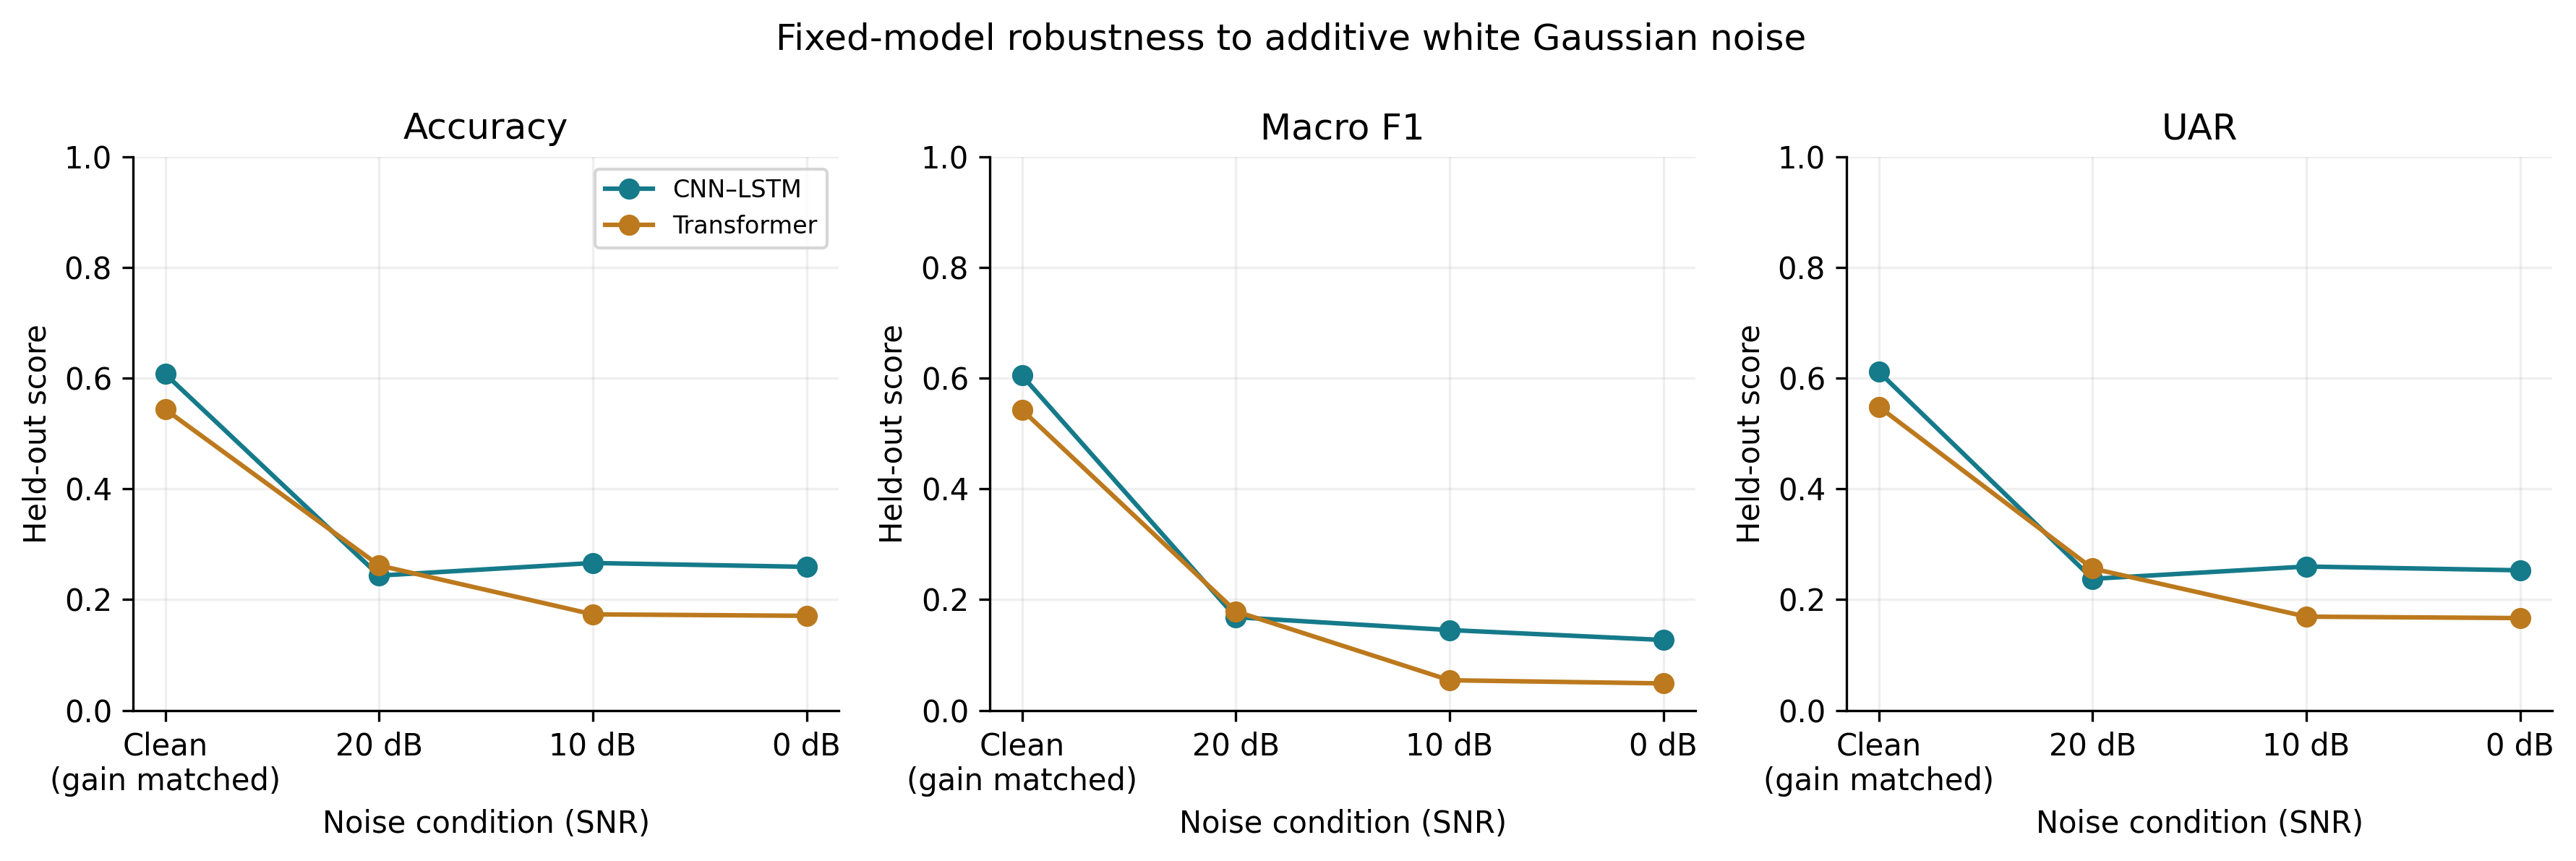

In [84]:
noise_comparison = evaluate_noise_robustness(experiment, corpus, CACHE_DIR, AUDIT_DIR)
display(noise_comparison[['architecture', 'condition', 'accuracy', 'macro_f1',
    'uar', 'accuracy_drop_pp', 'macro_f1_drop_pp', 'uar_drop_pp']].round(4))
display(Image(filename=str(experiment.root / 'noise_robustness/performance_vs_snr.png')))


## 10. Results and discussion
Compare the baseline and selected final models on the same Test recordings. Examine class and speaker errors rather than relying on a single aggregate score. Duration-group results describe associations, not a causal duration experiment.

HPO, feature-CV and final-validation results have different purposes and budgets. Their tables remain separate; the numerical summary describes measured differences within this study.

In [ ]:
def final_comparison(experiment, evaluations, audio_statistics):
    summary_dir = experiment.root / 'summary'
    rows, duration_errors = ([], [])

    for name, result in evaluations.items():
        rows.append(dict(
            model=name,
            **result['metrics'],
            macro_ovr_auc=result['macro_ovr_auc'],
            recordings=result['recordings'],
            scope=experiment.scope
        ))

        scores = pd.read_csv(
            experiment.root / 'test_evaluation' / name / 'predictions.csv'
        )

        joined = scores.merge(
            audio_statistics[['idx', 'duration_seconds']],
            on='idx',
            validate='one_to_one'
        )

        if len(joined) != len(scores):
            raise ValueError('Missing duration statistics for Test recordings')

        joined['duration_group'] = pd.cut(
            joined.duration_seconds,
            [0, 2, 4, 6, np.inf],
            labels=['0–2 s', '2–4 s', '4–6 s', '>6 s']
        )

        for group, part in joined.groupby('duration_group', observed=True):
            duration_errors.append(dict(
                model=name,
                duration_group=str(group),
                recordings=len(part),
                accuracy=float(part.correct.mean()),
                scope=experiment.scope
            ))

    table = pd.DataFrame(rows)

    table.to_csv(
        summary_dir / 'test_comparison.csv',
        index=False
    )

    pd.DataFrame(duration_errors).to_csv(
        summary_dir / 'duration_errors.csv',
        index=False
    )

    plt = plotting()
    figure, axis = plt.subplots(figsize=(10, 4.5))

    plot_table = table.set_index('model')[['accuracy', 'macro_f1', 'uar']]

    plot_table.index = [
        name.replace('cnn_lstm', 'CNN–LSTM')
            .replace('transformer', 'Transformer')
            .replace('baseline_', 'Baseline ')
            .replace('final_', 'Final ')
        for name in plot_table.index
    ]

    plot_table.rename(columns={
        'accuracy': 'Accuracy',
        'macro_f1': 'Macro F1',
        'uar': 'UAR'
    }).plot.bar(ax=axis)

    axis.set(
        ylim=(0, 1),
        ylabel='Held-out Test score',
        xlabel='',
        title='Baseline and Final Model Comparison'
    )

    axis.tick_params(axis='x', rotation=15)

    save_figure(
        figure,
        summary_dir / 'test_comparison.png',
        experiment.scope
    )

    return table


In [ ]:
def summarize_findings(experiment, comparison, feature_summary, frozen):
    lines = [f'## Results summary\n\n{experiment.scope}\n']
    scores = comparison.set_index('model')
    for architecture, selection in frozen['decisions'].items():
        baseline, final = (scores.loc['baseline_' + architecture], scores.loc['final_' + architecture])
        subset = feature_summary[feature_summary.architecture == architecture].set_index('features')
        change = subset.loc[selection['cv_size'], 'uar_mean'] - subset.loc[40, 'uar_mean']
        control = load_completed_trial(experiment, f'hpo_{architecture}_00')['assessment']['uar']
        paragraph = [f"**{architecture}**: CV selected {selection['cv_size']} bands.",
            f"Best HPO validation UAR was {100 * selection['hpo_validation']['uar']:.2f}%",
            f'versus {100 * control:.2f}% for its equal-budget control.', f'Mean CV UAR difference from 40 bands was {100 * change:+.2f} percentage points.',
            f"Final validation selected {len(selection['bands'])} bands at epoch {selection['selected_epoch']}",
            f"(UAR {100 * selection['validation']['uar']:.2f}%).", f'Baseline/final Test UAR: {100 * baseline.uar:.2f}% / {100 * final.uar:.2f}%',
            f'({100 * (final.uar - baseline.uar):+.2f} points).']
        lines.append(' '.join(paragraph))
    lines.append('Feature reduction changes model input dimensionality; all 40 mel bands are still extracted. These joint searches do not isolate causal parameter effects.')
    text = '\n\n'.join(lines)
    (experiment.root / 'summary/results_discussion.md').write_text(text, encoding='utf-8')
    return text


In [ ]:
comparison = final_comparison(experiment, evaluations, audio_statistics)
display(comparison.round(4))
display(Image(filename=str(experiment.root / 'summary/test_comparison.png')))
display(pd.read_csv(experiment.root / 'summary/duration_errors.csv').round(4))
for architecture in ['cnn_lstm', 'transformer']:
    directory = experiment.root / 'test_evaluation' / ('final_' + architecture)
    display(pd.read_csv(directory / 'error_pairs.csv').head(8))
    display(pd.read_csv(directory / 'per_speaker.csv').round(4))
discussion = summarize_findings(experiment, comparison, feature_summary, frozen)
display(Markdown(discussion))


## 11. Research Summary

The selected configurations and held-out Test metrics summarize the study. CSV tables, 300-dpi PNG figures, and scalable SVG figures are organized for report preparation.

Interpretation remains exploratory: a single training seed is used, and selection CV is not nested evaluation. Gaussian noise and acted speech do not establish performance in real-world microphone conditions. Stronger confirmation requires repeated training seeds and independently collected, labeled recordings.

In [ ]:
def evidence_index(experiment, audit_dir):
    summary = experiment.root / 'summary'
    specifications = [
        ('Dataset statistics and experimental setup', '5.1 / 5.2', Path(audit_dir)),
        ('Parameters, comparisons and discussion', '5.4 / 6.1–6.4', summary),
        ('Test metrics, ROC and error analysis', '5.3 / 6.2', experiment.root / 'test_evaluation'),
        ('Controlled waveform-noise robustness', '6.2 / 6.4', experiment.root / 'noise_robustness')
    ]

    entries = []
    for requirement, section, directory in specifications:
        for path in sorted(directory.rglob('*')):
            if path.is_file() and path.suffix in ['.csv', '.json', '.png', '.svg', '.md']:
                if path.name in ['results_index.csv', 'completion.json']:
                    continue
                entries.append(dict(
                    requirement=requirement,
                    template_section=section,
                    file=str(path.relative_to(experiment.root.parent)),
                    sha256=digest(path)
                ))

    patterns = [
        '*/learning_curves.*',
        '*/configuration.json',
        '*/history.json',
        '*/result.json',
        'study_identity.json',
        '*_search_plan.json',
        'ranking_*.json',
        'frozen_selection.json'
    ]

    for pattern in patterns:
        for path in sorted(experiment.root.glob(pattern)):
            entries.append(dict(
                requirement='Reproducibility and training behavior',
                template_section='5.2 / 6.0',
                file=str(path.relative_to(experiment.root.parent)),
                sha256=digest(path)
            ))

    for pattern in ['split_manifest.csv', 'complete_run_identity.json', 'preflight/*.json']:
        for path in sorted(experiment.root.parent.glob(pattern)):
            entries.append(dict(
                requirement='Partition and runtime provenance',
                template_section='5.2',
                file=str(path.relative_to(experiment.root.parent)),
                sha256=digest(path)
            ))

    table = pd.DataFrame(entries)
    table.to_csv(summary / 'results_index.csv', index=False)

    trials = pd.read_csv(summary / 'completed_trials.csv')

    expected = {
        'baseline': 2,
        'hpo': 2 * experiment.protocol['hpo_trials_per_model'],
        'feature': 2 * experiment.protocol['cv_folds'] * len(experiment.protocol['feature_sizes'])
    }

    counts = trials.stage.value_counts().to_dict()
    complete = all(
        counts.get(stage, 0) == number
        for stage, number in expected.items()
    )

    complete &= len(list(
        (experiment.root / 'test_evaluation').glob('*/evaluation.json')
    )) == 4

    noise_marker = experiment.root / 'noise_robustness/completion.json'
    noise_complete = (
        noise_marker.exists()
        and json.loads(noise_marker.read_text())['completed_evaluations'] == 8
    )

    complete &= noise_complete

    status = dict(
        scope=experiment.scope,
        development_and_evaluation_complete=bool(complete),
        noise_robustness_complete=bool(noise_complete),
        scientific_complete=bool(complete and experiment.mode == 'full'),
        final_submission_ready=False
    )

    write_json(summary / 'completion.json', status)
    return (table, status)


In [89]:
display(selected_parameters[['architecture', 'retained_bands', 'selected_epoch',
    'lr', 'weight_decay', 'dropout', 'batch_size']])
display(comparison[['model', 'accuracy', 'macro_f1', 'weighted_f1', 'uar', 'macro_ovr_auc']].round(4))
index, completion = evidence_index(experiment, AUDIT_DIR)
display(index.groupby(['requirement', 'template_section']).size().rename('evidence_files').reset_index())
print('Selected checkpoints:', experiment.root / 'summary/selected_models.json')
print('Evidence index:', experiment.root / 'summary/results_index.csv')


,architecture,retained_bands,selected_epoch,lr,weight_decay,dropout,batch_size
0,cnn_lstm,40,15,0.0010,0.001,0.25,16
1,transformer,40,15,0.0003,0.030,0.20,32


,model,accuracy,macro_f1,weighted_f1,uar,macro_ovr_auc
0,baseline_cnn_lstm,0.5797,0.5749,0.5741,0.5833,0.8687
1,final_cnn_lstm,0.6042,0.6008,0.5990,0.6084,0.8849
2,baseline_transformer,0.5534,0.5527,0.5519,0.5561,0.8574
3,final_transformer,0.5499,0.5483,0.5475,0.5547,0.8577


,requirement,template_section,evidence_files
0,Controlled waveform-noise robustness,6.2 / 6.4,30
1,Dataset statistics and experimental setup,5.1 / 5.2,20
2,"Parameters, comparisons and discussion",5.4 / 6.1–6.4,23
3,Partition and runtime provenance,5.2,3
4,Reproducibility and training behavior,5.2 / 6.0,288
5,"Test metrics, ROC and error analysis",5.3 / 6.2,84


Selected checkpoints: /content/drive/MyDrive/ARTI502_Research/CREMAD_SER/full/complete_experiments/summary/selected_models.json
Evidence index: /content/drive/MyDrive/ARTI502_Research/CREMAD_SER/full/complete_experiments/summary/results_index.csv
